# Cairo Weather: NASA POWER API and Time-Series EDA

**Region:** Cairo, Egypt (30.04° N, 31.24° E) · **Period:** 1990-01-01 to 2025-12-31, daily · **Source:** NASA POWER API

**Forecasting goal (used from Part 3 on):** two targets for **tomorrow**: the mean temperature (°C, regression) and whether there will be a real rain day (≥ 1 mm, yes/no).

## Pipeline

| Part | Steps | Question |
|---|---|---|
| **Setup** | Install, imports, plot style | |
| **1 — Data collection** | API settings → request → save raw JSON → units → missing value code → JSON to table → column names → save CSV | Can we get a long, reproducible daily record for Cairo? |
| **2 — Preparation** | 2.1 Understand the data → 2.2 Date index, gaps and duplicates → 2.3 Every variable over time → 2.4 Missing values → 2.5 Impossible values → 2.6 Decision and save → Data limitations | Is the data clean and complete? |
| **3 — EDA** | Visual overview → 3.1 Descriptive overview → 3.2 Temporal patterns → 3.3 Decomposition and structure → 3.4 Relationships and anomalies → 3.5 From EDA to modeling | What patterns must a forecast learn? |
| **Summary** | Region, API, patterns, stationarity, data quality | The written answers for Parts 1–3 |
| **4 — Forecasting setup** | 4.1 Targets and time split → 4.2 Metrics → 4.3 Temperature baselines → 4.4 Rain baselines | What score must a model beat? |
| **Next steps** | Features → models → walk-forward validation → residual checks → final test | |

**Rules**
1. The raw data is never changed; all work is on a copy.
2. No rows are dropped: the time series needs one row for every day.
3. Wrong values become empty (NaN). Short gaps are filled from the days around them; long gaps stay empty.
4. Real extreme days (storms, heat waves) are kept, never removed.
5. Every result is explained in three short parts: **What we see**, **Why**, and **What we do with it**.
6. Time order is kept: anything fitted from data (normals, thresholds, scalers) uses the training years only.

# Setup
Libraries for data (pandas, NumPy), the API request (requests), plots (matplotlib, seaborn) and time-series tools (statsmodels).

In [285]:
%pip install statsmodels

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [286]:
import json
import requests
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

### Plot style
Same style for every plot: light gray background with a white grid, bold titles.

In [287]:
sns.set_theme(style="darkgrid", font_scale=1.05)
plt.rcParams.update({"axes.titleweight": "bold", "axes.titlesize": 13, "figure.titleweight": "bold", "figure.titlesize": 18})

# Part 1 — Data Collection (NASA POWER API)

**Why NASA POWER:** It is free and needs no API key. It returns one consistent daily record for any point on Earth back to 1981, so a long series (36 years here) comes from a single call that anyone can repeat.

**Endpoint:** `https://power.larc.nasa.gov/api/temporal/daily/point`

| Parameter | Value | Meaning |
|---|---|---|
| `latitude`, `longitude` | 30.0444, 31.2357 | Central Cairo |
| `start`, `end` | 19900101, 20251231 | 36 full years of daily data |
| `community` | AG | Agroclimatology units (°C, mm/day, %, m/s, kPa) |
| `format` | JSON | The raw response is saved as it is |
| `parameters` | T2M, T2M_MAX, T2M_MIN, PRECTOTCORR, RH2M, WS2M, PS, WD2M | Mean, max and min temperature at 2 m; corrected rainfall; humidity; wind speed and direction at 2 m; surface pressure |

**Why daily for 36 years:** The task asks for at least one full year. Many years are needed to measure a trend and to see the yearly cycle many times; daily values are enough to forecast tomorrow.

**Rate limits:** All 36 years and 8 parameters come back in one request, so no rate limit was hit.

### Settings

In [288]:
API_URL = "https://power.larc.nasa.gov/api/temporal/daily/point"
LAT = 30.0444
LON = 31.2357
START = "19900101"
END = "20251231"
VARIABLES = "T2M,T2M_MAX,T2M_MIN,PRECTOTCORR,RH2M,WS2M,PS,WD2M"

RAW_JSON_FILE = "cairo_raw_nasa_power.json"
RAW_DATAFILE = "cairo_weather_raw.csv"
CLEAN_DATAFILE = "cairo_weather_clean.csv"

### Request

In [289]:
params = {
    "parameters": VARIABLES,
    "community": "AG",
    "latitude": LAT,
    "longitude": LON,
    "start": START,
    "end": END,
    "format": "JSON",
}

response = requests.get(API_URL, params=params, timeout=120)
response.status_code

200

### Save the raw response
The JSON is saved exactly as received, so the analysis can be repeated without calling the API again.

In [290]:
data = response.json()

with open(RAW_JSON_FILE, "w") as f:
    json.dump(data, f)

### Units
The unit of each variable, to make sure they are consistent before analysis.

In [291]:
for code in data["parameters"]:
    print(code, "->", data["parameters"][code]["units"])

T2M -> C
T2M_MAX -> C
T2M_MIN -> C
PRECTOTCORR -> mm/day
RH2M -> %
WS2M -> m/s
PS -> kPa
WD2M -> Degrees


**What we see:** Every variable already comes in the unit we want: °C, mm/day, %, m/s, kPa and degrees.

**Why:** We asked for the AG community, which returns metric units.

**What we do with it:** Nothing to convert.

### Missing value code
The number NASA writes when a value is missing, instead of leaving the cell empty.

In [292]:
data["header"]["fill_value"]

-999.0

**What we see:** NASA writes -999 when a value is missing.

**Why:** It is a code, not a real reading, but pandas reads it as a normal number. One -999 would pull an average far down.

**What we do with it:** Turn every -999 into NaN (empty) before counting or plotting (Step 2.4).

### JSON to table
The values are inside `properties → parameter`. Each variable becomes a column, and each date becomes a row.

In [293]:
weather_raw = pd.DataFrame(data["properties"]["parameter"])
weather_raw.index.name = "date"
weather_raw = weather_raw.reset_index()
weather_raw.head()

,date,T2M,T2M_MAX,T2M_MIN,PRECTOTCORR,RH2M,WS2M,PS,WD2M
0,19900101,13.31,20.23,8.66,0.37,62.42,1.49,100.00,58.0
1,19900102,15.33,23.23,10.14,0.01,48.45,3.03,99.54,216.4
2,19900103,13.99,19.98,8.22,0.12,66.60,4.21,99.53,242.1
3,19900104,12.90,18.70,8.92,0.58,68.98,3.67,99.97,261.4
4,19900105,12.41,17.99,7.54,0.34,69.80,2.32,100.35,280.7


### Clear column names
Replace NASA's codes with names that are easy to read.

In [294]:
weather_raw = weather_raw.rename(columns={
    "T2M": "temp_mean",
    "T2M_MAX": "temp_max",
    "T2M_MIN": "temp_min",
    "PRECTOTCORR": "precipitation",
    "RH2M": "humidity",
    "WS2M": "wind_speed",
    "PS": "pressure",
    "WD2M": "wind_dir",
})
weather_raw.head()

,date,temp_mean,temp_max,temp_min,precipitation,humidity,wind_speed,pressure,wind_dir
0,19900101,13.31,20.23,8.66,0.37,62.42,1.49,100.00,58.0
1,19900102,15.33,23.23,10.14,0.01,48.45,3.03,99.54,216.4
2,19900103,13.99,19.98,8.22,0.12,66.60,4.21,99.53,242.1
3,19900104,12.90,18.70,8.92,0.58,68.98,3.67,99.97,261.4
4,19900105,12.41,17.99,7.54,0.34,69.80,2.32,100.35,280.7


### Units for plot labels
The unit of each column, so every plot shows its unit.

In [295]:
UNITS = {
    "temp_mean": "°C",
    "temp_max": "°C",
    "temp_min": "°C",
    "precipitation": "mm/day",
    "humidity": "%",
    "wind_speed": "m/s",
    "pressure": "kPa",
    "wind_dir": "degrees",
}

### Save as CSV
This file is the starting point of Part 2.

In [296]:
weather_raw.to_csv(RAW_DATAFILE, index=False)

# Part 2 — Understanding and Preparing the Data
We start from the saved raw CSV, so this part does not need the API. Each cell uses one simple method to learn one thing about the data.

In [297]:
weather_raw = pd.read_csv(RAW_DATAFILE)

## 2.1 Understand the Data



In [298]:
weather_raw.head(10)

,date,temp_mean,temp_max,temp_min,precipitation,humidity,wind_speed,pressure,wind_dir
0,19900101,13.31,20.23,8.66,0.37,62.42,1.49,100.00,58.0
1,19900102,15.33,23.23,10.14,0.01,48.45,3.03,99.54,216.4
2,19900103,13.99,19.98,8.22,0.12,66.60,4.21,99.53,242.1
3,19900104,12.90,18.70,8.92,0.58,68.98,3.67,99.97,261.4
4,19900105,12.41,17.99,7.54,0.34,69.80,2.32,100.35,280.7
5,19900106,12.85,19.99,7.18,0.18,68.91,1.88,100.48,56.1
6,19900107,12.02,19.09,6.61,0.15,72.20,2.11,100.63,50.0
7,19900108,10.82,16.35,6.80,0.36,80.95,2.02,100.90,350.4
8,19900109,11.73,18.39,6.94,0.10,62.66,2.43,100.95,346.9
9,19900110,11.18,16.89,6.36,0.09,63.54,2.13,100.87,18.5


In [299]:
weather_raw.tail()

,date,temp_mean,temp_max,temp_min,precipitation,humidity,wind_speed,pressure,wind_dir
13144,20251227,13.67,20.97,8.41,0.11,73.26,2.44,99.85,-6028.0
13145,20251228,12.96,19.19,9.13,0.72,74.78,2.66,99.75,-6101.0
13146,20251229,13.75,20.18,7.69,0.06,73.13,2.79,100.06,-6208.0
13147,20251230,14.61,20.58,10.27,0.00,66.58,1.53,100.34,-6548.0
13148,20251231,13.63,20.03,8.82,0.00,46.42,3.83,99.81,-6765.0


In [300]:
weather_raw.shape

(13149, 9)

In [301]:
weather_raw.columns

Index(['date', 'temp_mean', 'temp_max', 'temp_min', 'precipitation',
       'humidity', 'wind_speed', 'pressure', 'wind_dir'],
      dtype='str')

### dtypes

In [302]:
weather_raw.dtypes

date               int64
temp_mean        float64
temp_max         float64
temp_min         float64
precipitation    float64
humidity         float64
wind_speed       float64
pressure         float64
wind_dir         float64
dtype: object

In [303]:
weather_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 13149 entries, 0 to 13148
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   date           13149 non-null  int64  
 1   temp_mean      13149 non-null  float64
 2   temp_max       13149 non-null  float64
 3   temp_min       13149 non-null  float64
 4   precipitation  13149 non-null  float64
 5   humidity       13149 non-null  float64
 6   wind_speed     13149 non-null  float64
 7   pressure       13149 non-null  float64
 8   wind_dir       13149 non-null  float64
dtypes: float64(8), int64(1)
memory usage: 924.7 KB


In [304]:
weather_raw.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
date,13149.0,20075671.44,103887.13,19900101.00,19990101.00,20080101.00,20161231.00,20251231.00
temp_mean,13149.0,21.75,6.82,5.63,15.34,22.41,28.06,36.34
temp_max,13149.0,29.75,7.68,7.90,22.83,30.57,36.72,45.49
temp_min,13149.0,14.77,5.76,0.44,9.53,15.37,19.97,27.90
precipitation,13149.0,0.17,1.60,0.00,0.00,0.00,0.00,95.48
humidity,13149.0,50.96,13.07,9.58,42.16,50.10,60.43,90.17
wind_speed,13149.0,2.85,0.84,0.66,2.28,2.83,3.38,7.38
pressure,13149.0,99.80,0.47,98.32,99.44,99.78,100.12,101.61
wind_dir,13149.0,-2394.50,3540.76,-9000.00,-5778.00,29.10,300.20,360.00


**What we see:** All columns look normal for Cairo, except `wind_dir`: its minimum is -9000 and its mean is negative.

**Why:** A wind direction is an angle, so it can only be between 0° and 360°. Negative values cannot be real.

**What we do with it:** Look closer at wind direction (below and in Step 2.3).

### .nunique()


In [305]:
weather_raw.nunique()

date             13149
temp_mean         2516
temp_max          2838
temp_min          2225
precipitation      355
humidity          4885
wind_speed         509
pressure           268
wind_dir          4379
dtype: int64

### .value_counts()


In [306]:
weather_raw["wind_dir"].value_counts().head()

wind_dir
350.1    17
349.4    16
341.3    14
346.7    14
4.6      14
Name: count, dtype: int64

**What we see:** The most common values are real angles near north (340°–360°).

**Why:** The wrong values are all different, so they are not one repeated error code we could simply replace.

**What we do with it:** Find *when* the wrong values start (Step 2.3) instead of looking for one code.

## 2.2 Date Index, Gaps and Duplicates

### Date as index
The date is read from the CSV as a number (19900101), so we turn it into a real date and make it the index.

In [307]:
# Work on a copy, so the raw data stays as it is
weather = weather_raw.copy()
weather["date"] = pd.to_datetime(weather["date"].astype(str), format="%Y%m%d")
weather = weather.set_index("date")
weather.index

DatetimeIndex(['1990-01-01', '1990-01-02', '1990-01-03', '1990-01-04',
               '1990-01-05', '1990-01-06', '1990-01-07', '1990-01-08',
               '1990-01-09', '1990-01-10',
               ...
               '2025-12-22', '2025-12-23', '2025-12-24', '2025-12-25',
               '2025-12-26', '2025-12-27', '2025-12-28', '2025-12-29',
               '2025-12-30', '2025-12-31'],
              dtype='datetime64[us]', name='date', length=13149, freq=None)

### No gaps
Every day from 1 Jan 1990 to 31 Dec 2025 must be in the data, in order. If a day is missing, this cell stops with an error.

In [308]:
full_date_range = pd.date_range(start="1990-01-01", end="2025-12-31", freq="D")
assert (full_date_range == weather.index).all()

# The step between two rows, as pandas sees it ("D" = one day)
print("Sampling frequency:", pd.infer_freq(weather.index))
print("Days:", len(weather.index), "| expected:", len(full_date_range))

Sampling frequency: D
Days: 13149 | expected: 13149


### Duplicates
Each date must appear once, and two different days should never have exactly the same values.

In [309]:
# Dates that appear more than once
weather.index.duplicated().sum()

np.int64(0)

In [310]:
# Different days with exactly the same values
weather.duplicated().sum()

np.int64(0)

**What we see:** The data is daily (frequency "D"), with no missing dates and no duplicates: exactly one row for each of the 13,149 days.

**Why:** NASA POWER is built from satellites and weather models, so it gives a value for every day, unlike a weather station that can break down.

**What we do with it:** Nothing to fix; the daily index can be used as it is.

## 2.3 Look at Every Variable Over Time

### Every variable over time
A line for each variable over 36 years. Gaps and wrong values show up by eye before any calculation.

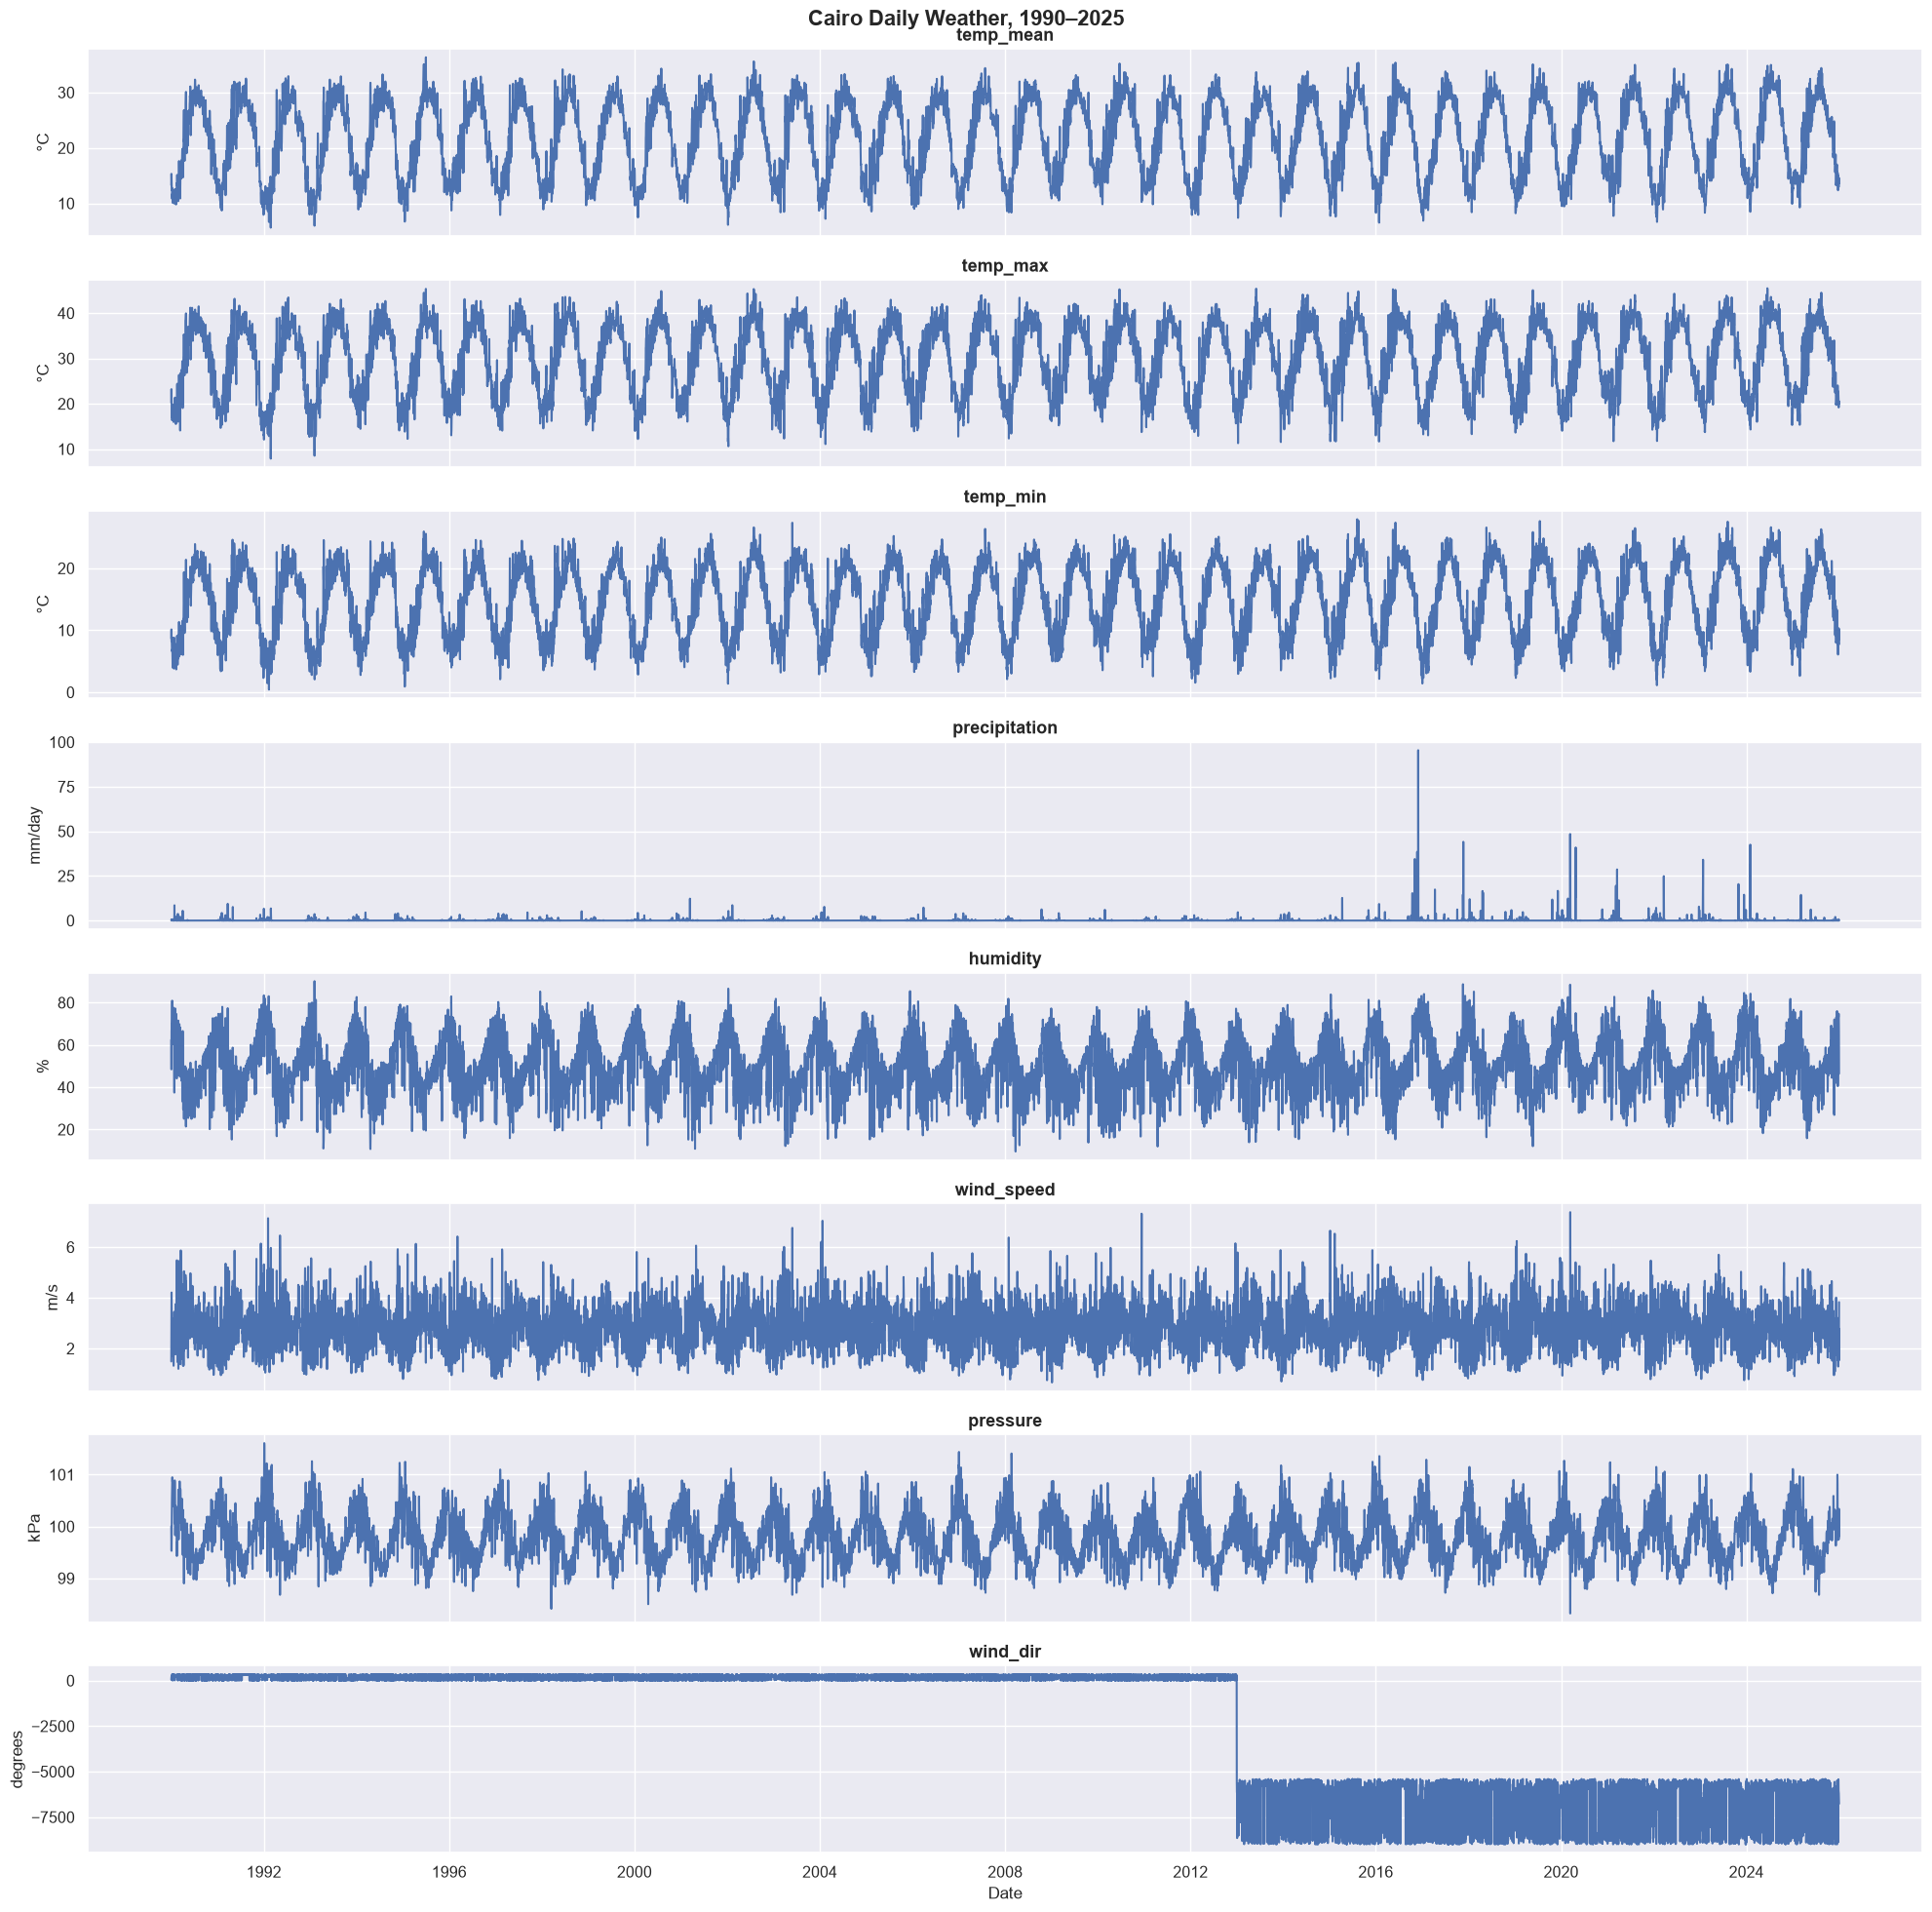

In [311]:
fig, ax = plt.subplots(nrows=8, figsize=(20, 20), sharex=True)
for i, column in enumerate(weather.columns):
    ax[i].plot(weather.index, weather[column])
    ax[i].set_title(column)
    ax[i].set_ylabel(UNITS[column])
ax[-1].set_xlabel("Date")
plt.suptitle("Cairo Daily Weather, 1990–2025", fontsize=16)
plt.tight_layout()
plt.show()

**What we see:**
- Temperature, humidity and pressure repeat the same yearly wave, with no gaps or strange jumps.
- `wind_dir` is fine until the end of 2012, then drops below 0 and stays there until 2025.
- Heavy rain (above 20 mm) appears only after 2016. Before that, no day reaches 13 mm.
- The lowest pressure of all 36 years (about 98.3 kPa) is in March 2020, at the time of a big storm.
- The coldest days are in early 1992 (min temperature near 0.4 °C).

**Why:** When 13 years of wind direction go wrong at once, the problem is in the data, not the weather. The rain jump could be either, so it needs a test.

**What we do with it:** Wind direction from 2013 becomes empty (Step 2.4). The rain jump (H3), the 2020 storm (H5) and the 1992 cold wave (H4) are studied in Part 3.

### Wrong wind direction values
How many there are, their range, and when they start and end.

In [312]:
wrong_wind_dir = weather[weather["wind_dir"] < 0]["wind_dir"]
wrong_wind_dir.describe()

count    4749.000000
mean    -6970.649610
std      1376.423324
min     -9000.000000
25%     -8587.000000
50%     -6370.000000
75%     -5701.000000
max     -5400.000000
Name: wind_dir, dtype: float64

In [313]:
print("First wrong day:", wrong_wind_dir.index.min().date())
print("Last wrong day:", wrong_wind_dir.index.max().date())

First wrong day: 2012-12-31
Last wrong day: 2025-12-31


## 2.4 Missing Value Analysis

### Wrong values become missing
NASA's code (-999) and wind direction below 0 are not real values, so we turn them into empty cells (NaN) before counting.

In [314]:
weather = weather.replace(-999, np.nan)
weather.loc[weather["wind_dir"] < 0, "wind_dir"] = np.nan

### Share of missing values in the whole table

In [315]:
weather.isnull().sum().sum() / weather.size

np.float64(0.04514601870864705)

### Share of missing values in each column

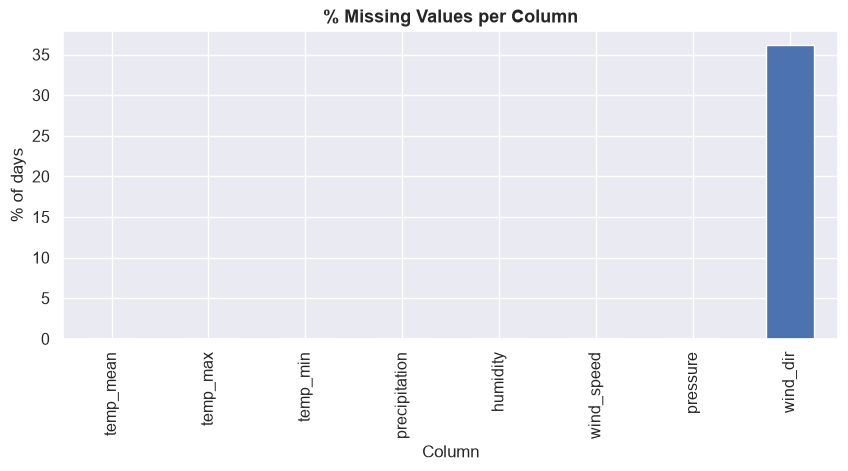

In [316]:
perc_nan_by_column = 100 * weather.isnull().sum() / len(weather)

perc_nan_by_column.plot(kind="bar", figsize=(10, 4), title="% Missing Values per Column")
plt.xlabel("Column")
plt.ylabel("% of days")
plt.show()

### When the missing values happen
Missing wind direction values counted by year, to see if they are scattered or in one block of years.

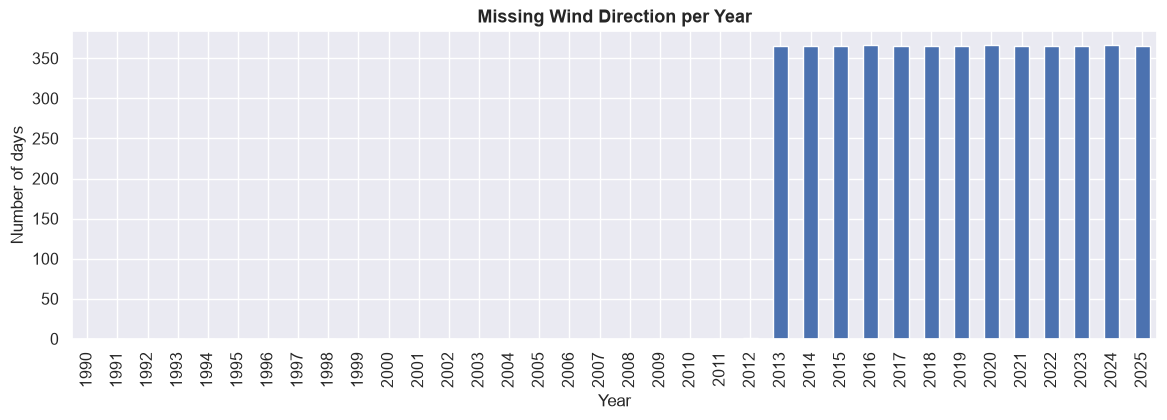

In [317]:
nan_by_year = weather["wind_dir"].isnull().groupby(weather.index.year).sum()

nan_by_year.plot(kind="bar", figsize=(14, 4), title="Missing Wind Direction per Year")
plt.xlabel("Year")
plt.ylabel("Number of days")
plt.show()

**What we see:** About 4.5 % of the table is empty, and all of it is wind direction: 4,749 days (36 % of that column), every day from 2013 to 2025. The other 7 columns have nothing missing.

**Why:** These are the negative wind directions from Step 2.3, now marked as empty. They are one long block, not scattered days.

**What we do with it:** Decided in Step 2.6.

## 2.5 Impossible Values
Now that missing codes are empty, we check values that cannot happen in real weather.

### Q1. Is there any negative rain?

In [318]:
(weather["precipitation"] < 0).sum()

np.int64(0)

### Q2. Is the min temperature ever above the max temperature?

In [319]:
(weather["temp_min"] > weather["temp_max"]).sum()

np.int64(0)

### Q3. Is humidity ever outside 0–100 %?

In [320]:
((weather["humidity"] < 0) | (weather["humidity"] > 100)).sum()

np.int64(0)

### Q4. Is wind speed ever negative?

In [321]:
(weather["wind_speed"] < 0).sum()

np.int64(0)

**What we see:** All four checks give 0: no negative rain, no min above max, no humidity outside 0–100 %, no negative wind speed.

**Why:** These are four rules that every real weather record must follow. Breaking one would mean a data error.

**What we do with it:** Nothing to remove; these values can be trusted.

## 2.6 Decision and Save

**Decisions:**
- **Units:** All consistent (°C, mm/day, %, m/s, kPa, degrees; checked in Part 1), so nothing is converted.
- **Wind direction:** 13 years in a row are missing. Filling them would mean making up data, so they stay empty, and wind direction is only used for 1990–2012.
- **Other columns:** Nothing is missing. The gap-filling code below stays as a safety net; it changes nothing here.
- **Heavy rain after 2016:** Kept. It might be real, so we test it in Part 3 (H3) instead of deleting it.

In [322]:
weather_clean = weather.copy()

NUMBER_COLUMNS = ["temp_mean", "temp_max", "temp_min", "precipitation", "humidity", "wind_speed", "pressure"]
def fill_short_gaps(series, max_days=3):
    # Fill a gap from the days around it only if it is at most max_days long; longer gaps stay empty
    missing = series.isnull()
    gap_length = missing.groupby((~missing).cumsum()).transform("sum")
    return series.where(~(missing & (gap_length <= max_days)), series.interpolate(method="time"))

for column in NUMBER_COLUMNS:
    weather_clean[column] = fill_short_gaps(weather_clean[column])

weather_clean.isnull().sum()

temp_mean           0
temp_max            0
temp_min            0
precipitation       0
humidity            0
wind_speed          0
pressure            0
wind_dir         4749
dtype: int64

### Save and Clean Data

In [323]:
weather_clean.to_csv(CLEAN_DATAFILE)
weather_clean.shape

(13149, 8)

## Data Limitations

1. **Model data, not a weather station:** NASA POWER estimates the weather from satellites and models, as an average over about 50 km × 50 km. Very hot and very cold days may look a bit milder than a station would show.
2. **Rain is the weakest variable:** Rain in Cairo is rare and local, so the exact mm can be off; "rain or no rain" is more reliable. From 2016, rain days suddenly double and yearly totals grow about 4.6 times (H3, Step 3.2.2). This is most likely a change in the data, so the rain analysis and the rain model use 2016–2025 only.
3. **Wind direction only works for 1990–2012:** From 2013, every value is below 0, which is not a real angle. These days stay empty, so questions that need wind direction (H6, Khamasin) use 1990–2012 only.

# Part 3 — Exploratory Data Analysis (Time-Series Focus)
We start from the clean CSV saved in Part 2. The steps follow the task:

| Step | What we do |
|---|---|
| Visual overview | Three dashboards: climate overview, every day since 1990, warmer or colder than normal |
| 3.1 Descriptive overview | Summary statistics, skew, rain days, distributions |
| 3.2 Temporal patterns | 3.2.1 Full time range · 3.2.2 Trend (H1–H4) · 3.2.3 Seasonality · 3.2.4 Rolling statistics |
| 3.3 Decomposition and structure | 3.3.1 Decomposition · 3.3.2 ACF and PACF, which lags to use · 3.3.3 Stationarity (ADF) |
| 3.4 Relationships and anomalies | 3.4.1 Correlation · 3.4.2 Outliers on rolling windows · 3.4.3 Suspicious values · 3.4.4 Extreme events (H5, H6) |
| 3.5 From EDA to modeling | Every finding and the modeling decision it leads to |

Every result is explained in three short parts: **What we see**, **Why**, and **What we do with it**.

**Hypotheses tested**

| | Question | Step |
|---|---|---|
| H1 | Is Cairo getting warmer, and are nights warming faster than days? | 3.2.2 |
| H2 | Are very hot days becoming more frequent? | 3.2.2 |
| H3 | Did heavy rain really increase after 2016, or did the data change? | 3.2.2 |
| H4 | Are cold waves becoming rarer? Which years were the strongest? | 3.2.2 |
| H5 | Do storms have a signature in the days before them? | 3.4.4 |
| H6 | Can Khamasin-like days be detected, and when do they happen? | 3.4.4 |

In [324]:
weather = pd.read_csv(CLEAN_DATAFILE, index_col="date", parse_dates=True)
weather.head()

,temp_mean,temp_max,temp_min,precipitation,humidity,wind_speed,pressure,wind_dir
date,,,,,,,,
1990-01-01,13.31,20.23,8.66,0.37,62.42,1.49,100.00,58.0
1990-01-02,15.33,23.23,10.14,0.01,48.45,3.03,99.54,216.4
1990-01-03,13.99,19.98,8.22,0.12,66.60,4.21,99.53,242.1
1990-01-04,12.90,18.70,8.92,0.58,68.98,3.67,99.97,261.4
1990-01-05,12.41,17.99,7.54,0.34,69.80,2.32,100.35,280.7


In [325]:
BEFORE_COLOR = "#2a78d6"   # 1990–2015
AFTER_COLOR = "#eb6834"    # 2016–2025

MONTHS = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]

## Visual Overview
Three dashboards that summarize 36 years of Cairo weather before the detailed analysis.

### Dashboard 1: Cairo climate overview
A. The average year · B. Max temperature by month and decade · C. Real rain days by month, before and after 2016 · D. Temperature vs humidity by season.

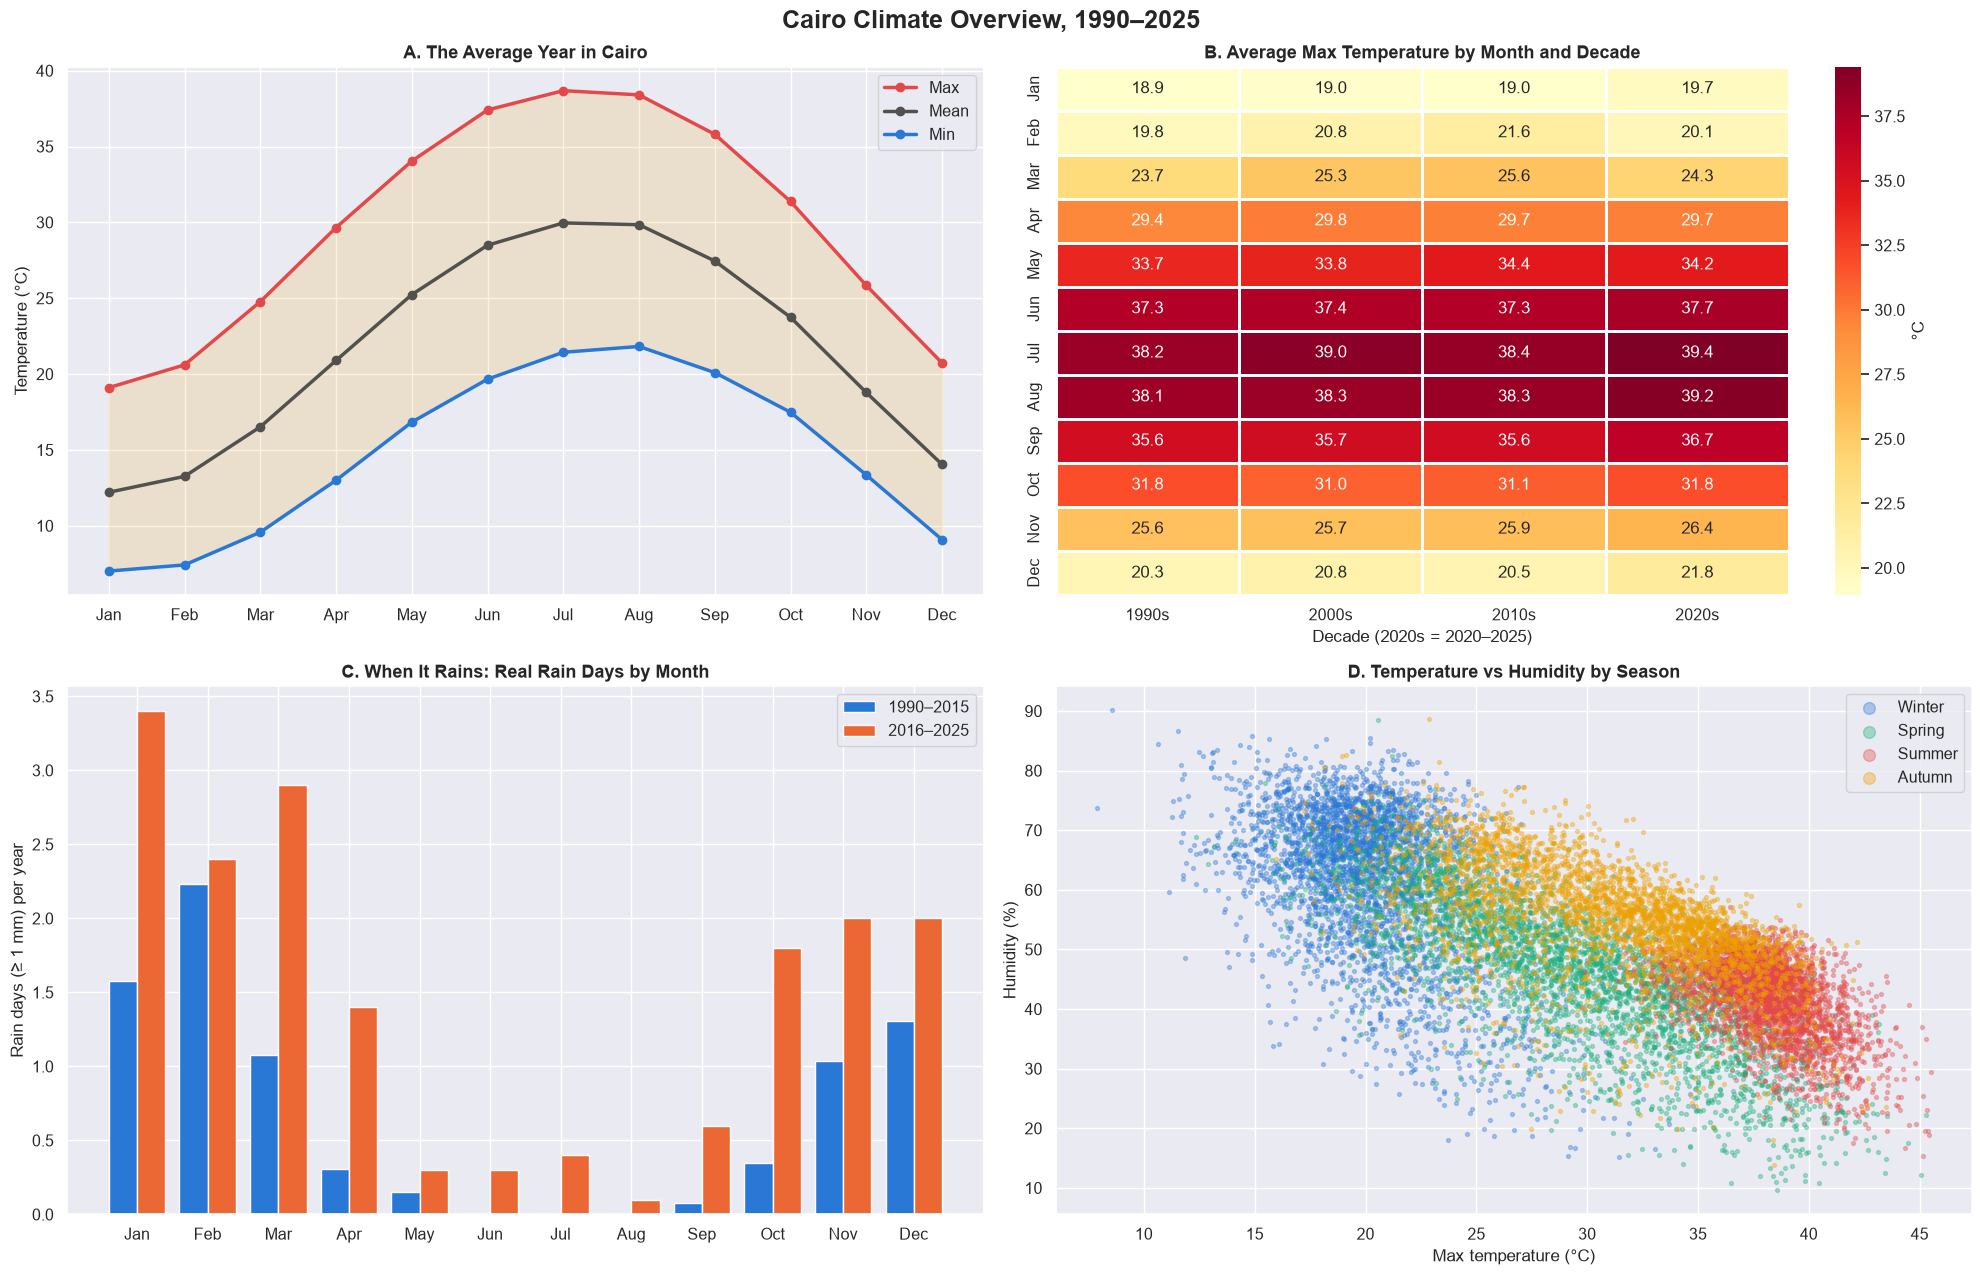

In [326]:
SEASONS = {12: "Winter", 1: "Winter", 2: "Winter", 3: "Spring", 4: "Spring", 5: "Spring",
           6: "Summer", 7: "Summer", 8: "Summer", 9: "Autumn", 10: "Autumn", 11: "Autumn"}
SEASON_COLORS = {"Winter": "#2a78d6", "Spring": "#1baf7a", "Summer": "#e34948", "Autumn": "#eda100"}
month = weather.index.month

fig, ax = plt.subplots(nrows=2, ncols=2, figsize=(20, 13))

# A. Average year: max, mean and min temperature by month
average_year = weather.groupby(month)[["temp_max", "temp_mean", "temp_min"]].mean()
ax[0, 0].fill_between(average_year.index, average_year["temp_min"], average_year["temp_max"], color="#eda100", alpha=0.15)
ax[0, 0].plot(average_year.index, average_year["temp_max"], marker="o", color="#e34948", linewidth=2.5, label="Max")
ax[0, 0].plot(average_year.index, average_year["temp_mean"], marker="o", color="#52514e", linewidth=2.5, label="Mean")
ax[0, 0].plot(average_year.index, average_year["temp_min"], marker="o", color="#2a78d6", linewidth=2.5, label="Min")
ax[0, 0].set_xticks(range(1, 13))
ax[0, 0].set_xticklabels(MONTHS)
ax[0, 0].set_ylabel("Temperature (°C)")
ax[0, 0].set_title("A. The Average Year in Cairo")
ax[0, 0].legend()

# B. Max temperature by month and decade, with the numbers inside
decade = (weather.index.year // 10 * 10).astype(str) + "s"
by_decade = weather.groupby([month, decade])["temp_max"].mean().unstack()
by_decade.index = MONTHS
sns.heatmap(by_decade, annot=True, fmt=".1f", cmap="YlOrRd", linewidths=1, cbar_kws={"label": "°C"}, ax=ax[0, 1])
ax[0, 1].set_title("B. Average Max Temperature by Month and Decade")
ax[0, 1].set_xlabel("Decade (2020s = 2020–2025)")
ax[0, 1].set_ylabel("")

# C. Real rain days per month, before and after 2016
rain_day = weather["precipitation"] >= 1
before = rain_day.loc[:"2015"].groupby(rain_day.loc[:"2015"].index.month).sum() / 26
after = rain_day.loc["2016":].groupby(rain_day.loc["2016":].index.month).sum() / 10
ax[1, 0].bar(before.index - 0.2, before, width=0.4, color=BEFORE_COLOR, label="1990–2015")
ax[1, 0].bar(after.index + 0.2, after, width=0.4, color=AFTER_COLOR, label="2016–2025")
ax[1, 0].set_xticks(range(1, 13))
ax[1, 0].set_xticklabels(MONTHS)
ax[1, 0].set_ylabel("Rain days (≥ 1 mm) per year")
ax[1, 0].set_title("C. When It Rains: Real Rain Days by Month")
ax[1, 0].legend()

# D. Temperature vs humidity, one color per season
season = weather.index.month.map(SEASONS)
for name, color in SEASON_COLORS.items():
    days = weather[season == name]
    ax[1, 1].scatter(days["temp_max"], days["humidity"], s=8, alpha=0.35, color=color, label=name)
ax[1, 1].set_xlabel("Max temperature (°C)")
ax[1, 1].set_ylabel("Humidity (%)")
ax[1, 1].set_title("D. Temperature vs Humidity by Season")
ax[1, 1].legend(markerscale=3)

plt.suptitle("Cairo Climate Overview, 1990–2025")
plt.tight_layout()
plt.show()

**What we see:**
- **A.** Max, mean and min move together. The mean goes from about 12 °C in January to about 30 °C in July–August. Day and night are about 12 °C apart in winter and 17 °C apart in summer.
- **B.** Each month keeps almost the same color in every decade. The 2020s have the hottest summers (July 39.4 °C, against 38.2 °C in the 1990s).
- **C.** Rain falls from November to March; summer is almost dry. After 2016, every month has more rain days (January 1.6 → 3.4).
- **D.** Hotter days are drier: humidity drops from 70–80 % at 15–20 °C to 20–40 % above 40 °C. At the same temperature, spring days are drier than autumn days.

**Why:** Cairo's weather follows the sun's yearly cycle: more sun means hotter and drier days. Spring is drier than autumn because it brings dry desert winds (Khamasin, H6).

**What we do with it:** The calendar (day of year, month) is the most important input. The model also needs the season, not only today's temperature, because spring and autumn behave differently.

### Dashboard 2: Cairo weather overview
Left: every day of the 36 years, colored by its max temperature (one row per year). Right: a summary of each year; in each column, red is high and blue is low.

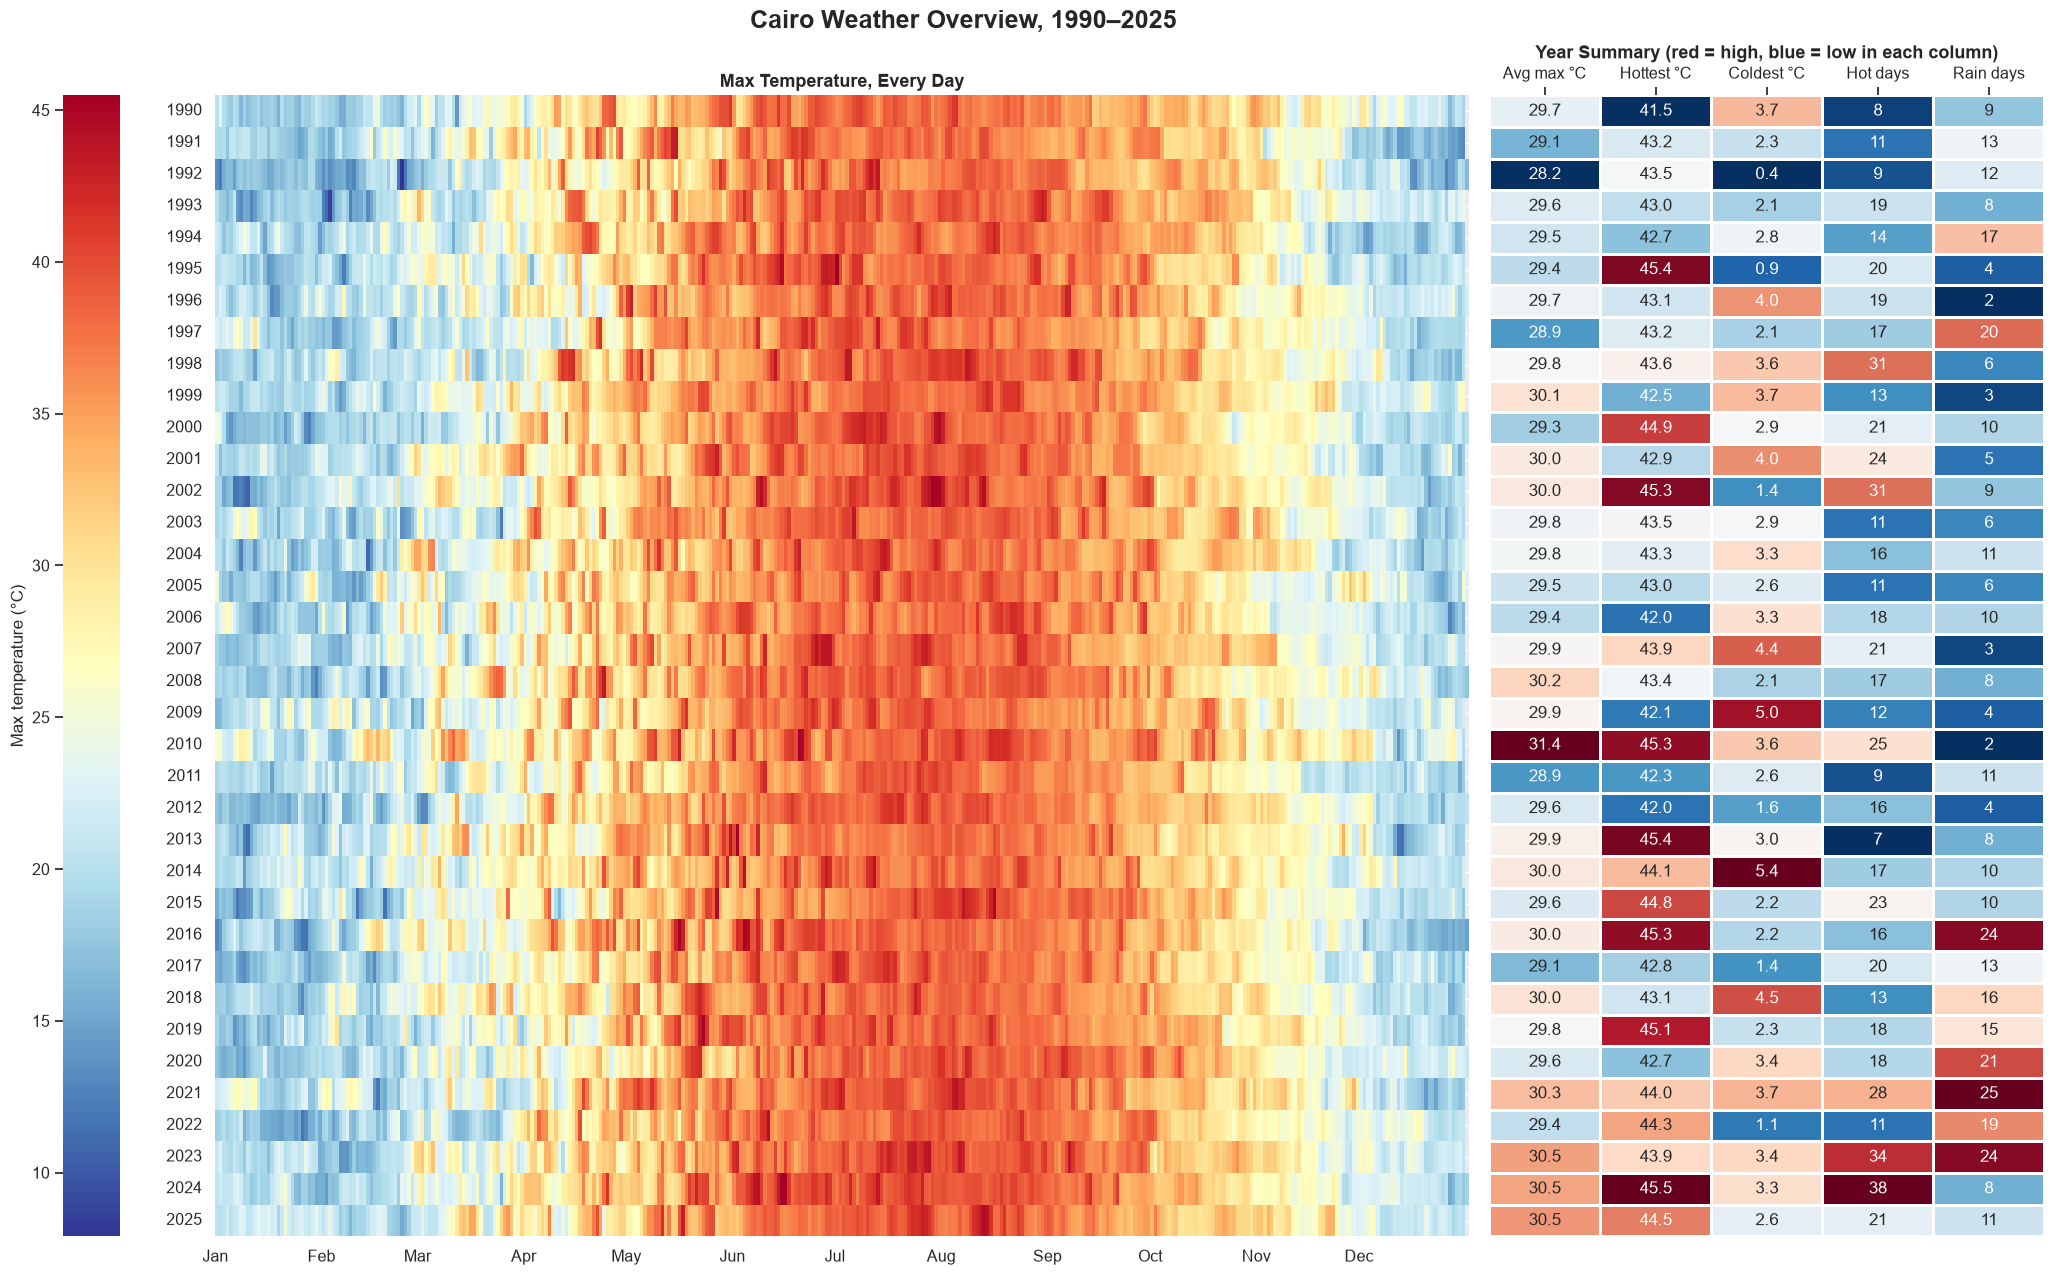

In [327]:
year = weather.index.year

# Left: one row per year, one column per day of the year
daily_max = weather.pivot_table(values="temp_max", index=year, columns=weather.index.dayofyear)

# Right: summary numbers for each year
yearly_stats = pd.DataFrame({
    "Avg max °C": weather["temp_max"].groupby(year).mean(),
    "Hottest °C": weather["temp_max"].groupby(year).max(),
    "Coldest °C": weather["temp_min"].groupby(year).min(),
    "Hot days": (weather["temp_max"] > weather["temp_max"].quantile(0.95)).groupby(year).sum(),
    "Rain days": (weather["precipitation"] >= 1).groupby(year).sum(),
})

# Scale each column from 0 to 1, so every column gets its own color range
scaled = (yearly_stats - yearly_stats.min()) / (yearly_stats.max() - yearly_stats.min())
labels = yearly_stats.round(1).astype(str)

fig, ax = plt.subplots(ncols=2, figsize=(22, 13), gridspec_kw={"width_ratios": [4, 1.4]})

sns.heatmap(daily_max, cmap="RdYlBu_r", cbar_kws={"label": "Max temperature (°C)", "location": "left", "pad": 0.06}, ax=ax[0])
ax[0].set_xticks([0, 31, 59, 90, 120, 151, 181, 212, 243, 273, 304, 334])
ax[0].set_xticklabels(MONTHS, rotation=0)
ax[0].set_xlabel("")
ax[0].set_ylabel("")
ax[0].set_title("Max Temperature, Every Day")

sns.heatmap(scaled, annot=labels, fmt="", cmap="RdBu_r", cbar=False, linewidths=1, linecolor="white", ax=ax[1])
ax[1].set_ylabel("")
ax[1].set_yticks([])
ax[1].xaxis.tick_top()
ax[1].set_title("Year Summary (red = high, blue = low in each column)")

plt.suptitle("Cairo Weather Overview, 1990–2025")
plt.tight_layout()
plt.show()

**What we see:** Every year has the same hot band from May to September. Winters change more: 1992–1993 have long cold spells, and early 2010 is unusually warm. The last three years (2023–2025) have an average max of 30.5 °C, the highest after 2010. Rain days jump from 2–13 per year before 2016 to often 15–25 after.

**Why:** In summer, the same stable hot air sits over Cairo every year. In winter, weather systems come and go from the Mediterranean, so one winter can be very different from the next.

**What we do with it:** Expect bigger errors in winter and spring. The test years are among the warmest, so we will check whether the model forecasts them too cold.

### Dashboard 3: Warmer or colder than normal?
For each day, the mean temperature minus the normal for that day of the year (its 36-year average), smoothed over 30 days. Red is warmer than normal, blue is colder. The warmest and coldest periods are labeled.

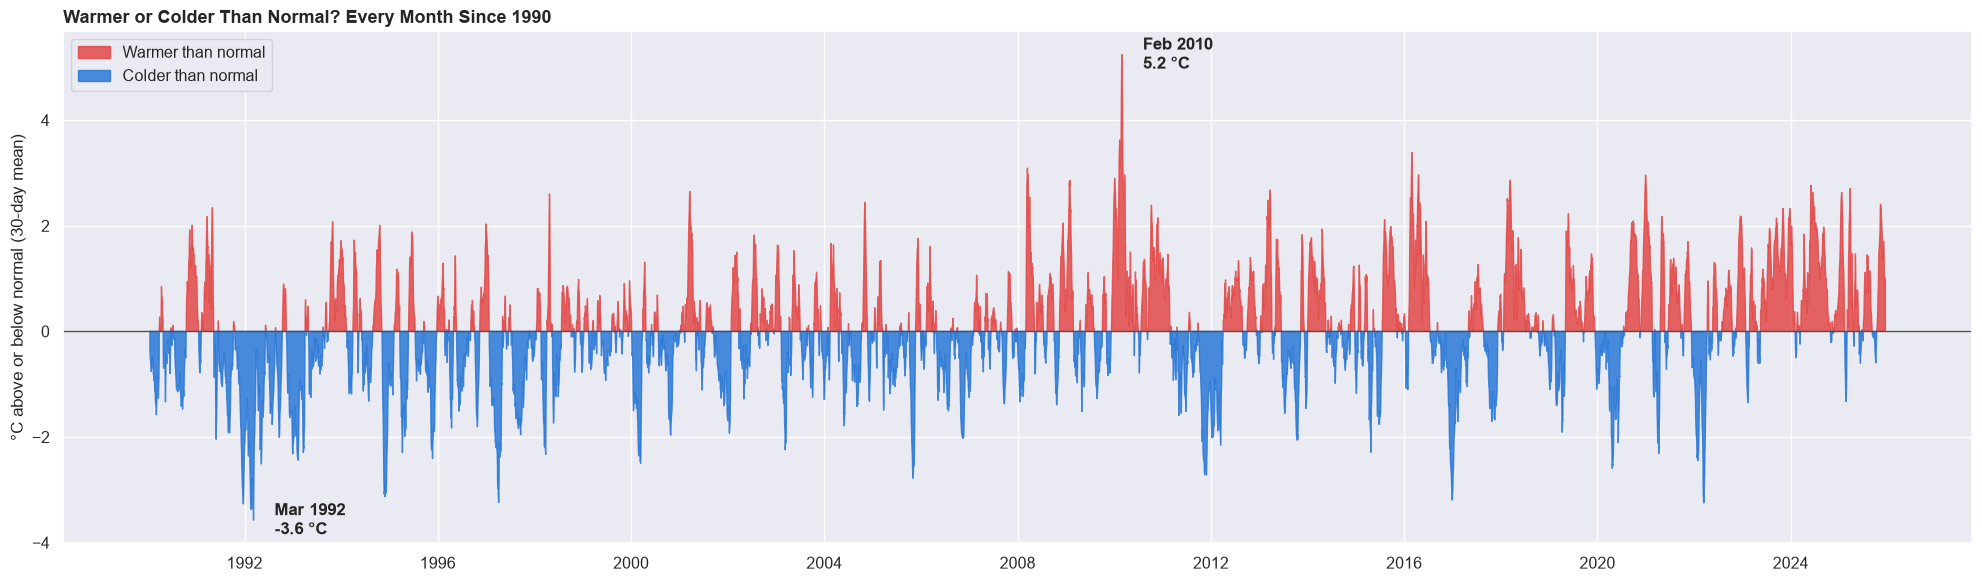

In [328]:
# Normal = the 36-year average of each day of the year
normal = weather["temp_mean"].groupby(weather.index.dayofyear).transform("mean")
anomaly = (weather["temp_mean"] - normal).rolling(30, center=True).mean()

fig, ax = plt.subplots(figsize=(20, 6))
ax.fill_between(anomaly.index, anomaly, 0, where=anomaly > 0, color="#e34948", alpha=0.85, label="Warmer than normal")
ax.fill_between(anomaly.index, anomaly, 0, where=anomaly < 0, color="#2a78d6", alpha=0.85, label="Colder than normal")
ax.axhline(0, color="#52514e", linewidth=1)

# Label the warmest and the coldest period
for day in [anomaly.idxmax(), anomaly.idxmin()]:
    ax.annotate(day.strftime("%b %Y") + "\n" + str(round(anomaly[day], 1)) + " °C",
                xy=(day, anomaly[day]), xytext=(15, 0), textcoords="offset points", fontweight="bold", va="center")

ax.set_ylabel("°C above or below normal (30-day mean)")
ax.set_title("Warmer or Colder Than Normal? Every Month Since 1990", loc="left")
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

**What we see:** Warm and cold spells last weeks or months, not single days. The 1990s are mostly colder than normal (coldest: March 1992, −3.6 °C). Since about 2008, warmer than normal is more common (warmest: February 2010, +5.2 °C), and since 2023 there is almost no cold spell.

**Why:** Large weather patterns stay in place for weeks. Also, "normal" here is the 36-year average, so with the warming trend, old years look cold and recent years look warm.

**What we do with it:** If today is warmer than normal, tomorrow probably is too, so "today's difference from normal" is a useful input (measured in Step 3.3.2). For the model, normals come from the training years only, so it never sees the future.

## 3.1 Descriptive Overview

### Summary statistics and skew
Skew shows if a variable is balanced around its mean (close to 0) or has a long tail (far from 0).

In [329]:
summary = weather.describe().T
summary["skew"] = weather.skew()
summary.round(2)

,count,mean,std,min,25%,50%,75%,max,skew
temp_mean,13149.0,21.75,6.82,5.63,15.34,22.41,28.06,36.34,-0.17
temp_max,13149.0,29.75,7.68,7.90,22.83,30.57,36.72,45.49,-0.22
temp_min,13149.0,14.77,5.76,0.44,9.53,15.37,19.97,27.90,-0.17
precipitation,13149.0,0.17,1.60,0.00,0.00,0.00,0.00,95.48,28.71
humidity,13149.0,50.96,13.07,9.58,42.16,50.10,60.43,90.17,-0.01
wind_speed,13149.0,2.85,0.84,0.66,2.28,2.83,3.38,7.38,0.37
pressure,13149.0,99.80,0.47,98.32,99.44,99.78,100.12,101.61,0.28
wind_dir,8400.0,192.65,141.00,0.00,34.78,246.85,330.60,360.00,-0.20


**What we see:** Temperature, humidity, wind and pressure are balanced around their mean (skew between −0.2 and 0.4). Rain is extremely one-sided (skew 28.7): at least 75 % of days have no rain, but the maximum is 95.5 mm. Wind direction has only 8,400 values (1990–2012).

**Why:** Most days in Cairo are dry, and a few storms bring a lot of rain at once, so rain has a very long tail. The mean of wind direction (193°) means nothing, because angles wrap around: 10° and 350° are both north.

**What we do with it:** Describe rain with counts of rain days, not its mean. Never average wind direction as a plain number.

### How many days had rain?
Two levels: any rain (> 0 mm), and a real rain day (≥ 1 mm), because the model gives many tiny values that are not real rain.

In [330]:
total_days = len(weather)
any_rain = (weather["precipitation"] > 0).sum()
real_rain = (weather["precipitation"] >= 1).sum()

print("Days with any rain:", any_rain, "-", round(100 * any_rain / total_days, 1), "%")
print("Days with real rain (>= 1 mm):", real_rain, "-", round(100 * real_rain / total_days, 1), "%")

Days with any rain: 2726 - 20.7 %
Days with real rain (>= 1 mm): 387 - 2.9 %


**What we see:** 21 % of days have some rain, but only 2.9 % have real rain (≥ 1 mm).

**Why:** The model behind the data often gives tiny amounts (below 1 mm) that you would not notice as rain.

**What we do with it:** A rain day means ≥ 1 mm. With only 3 % rain days, a model that always says "no rain" is 97 % accurate and still useless, so rain models are judged on hits, misses and false alarms, not accuracy.

### Distribution of each variable
A histogram with a smooth curve (KDE) for each variable: where most values are, and whether it has one peak or two.

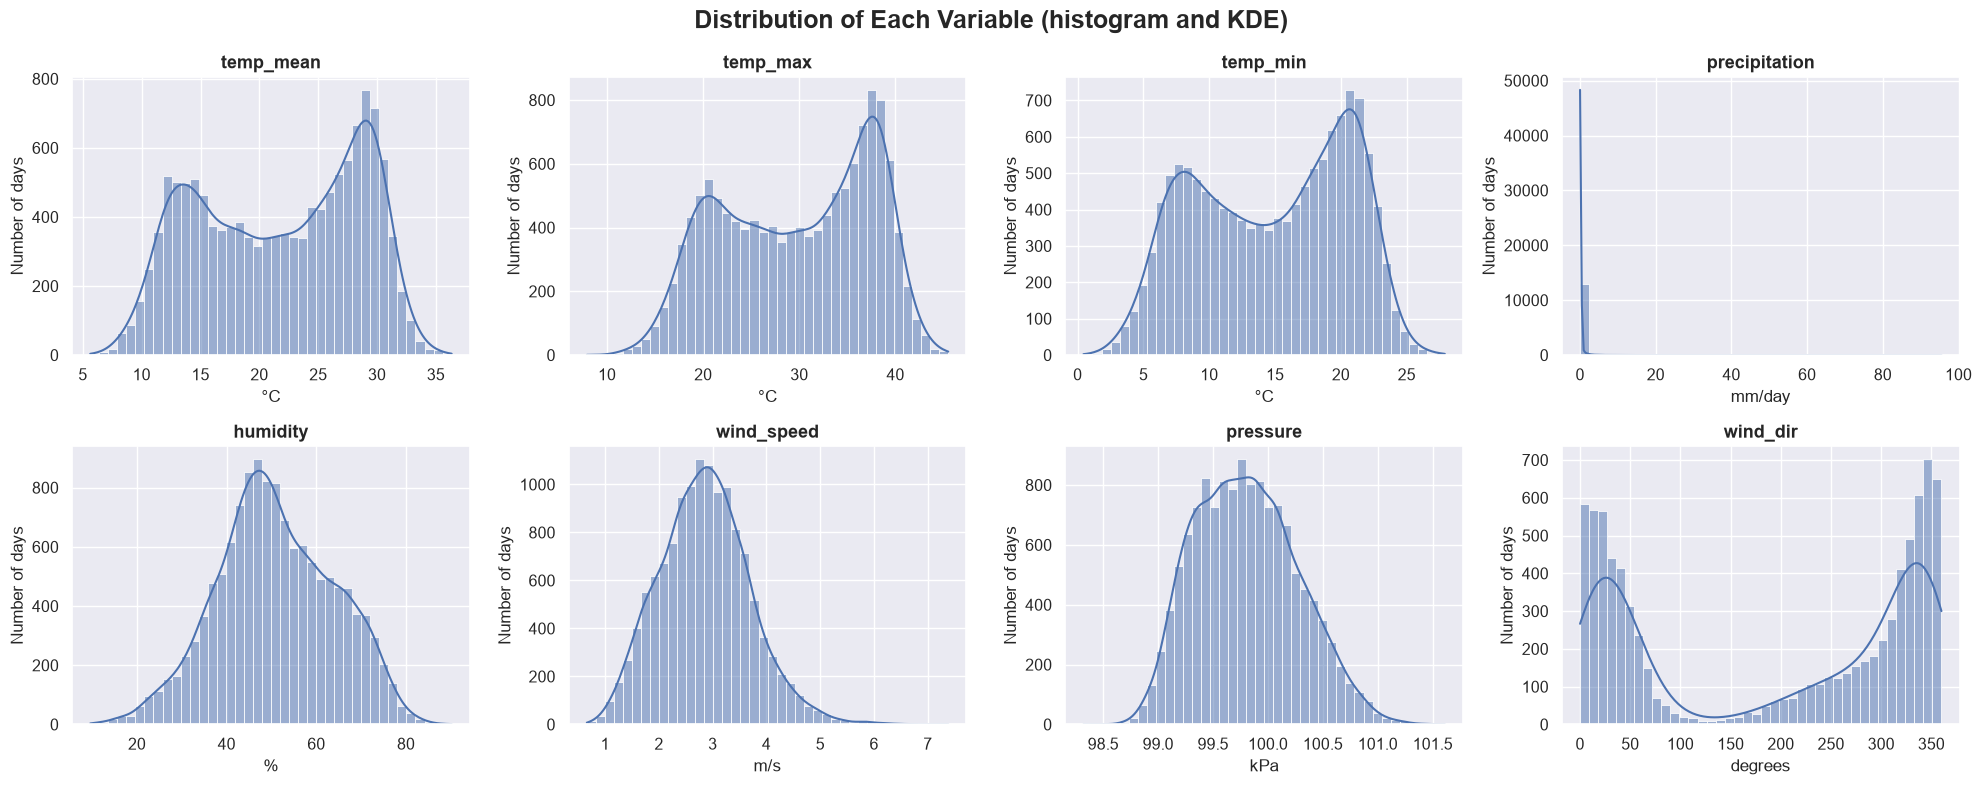

In [331]:
fig, ax = plt.subplots(nrows=2, ncols=4, figsize=(20, 8))
ax = ax.flatten()
for i, column in enumerate(weather.columns):
    sns.histplot(weather[column], bins=40, kde=True, ax=ax[i])
    ax[i].set_title(column)
    ax[i].set_xlabel(UNITS[column])
    ax[i].set_ylabel("Number of days")
plt.suptitle("Distribution of Each Variable (histogram and KDE)")
plt.tight_layout()
plt.show()

**What we see:**
- **Temperature:** Two peaks, not one: winter (mean about 13 °C) and summer (about 29 °C). The overall mean (22 °C) sits between them, where few real days are.
- **Rain:** Almost all days are at zero (rain days are plotted on their own below).
- **Humidity:** One peak around 47 %, with a smaller bump at 60–70 % (humid winter days).
- **Wind speed:** One peak around 2.8 m/s, with a short tail up to about 7 m/s (storm days).
- **Pressure:** A narrow range, about 98.5–101.5 kPa.
- **Wind direction:** Looks like two groups, but 0° and 360° are both north, so it is one group: the wind mostly comes from the north. South winds are rare.

**Why:** Cairo has two long seasons (winter and summer) and two short ones in between, so temperature piles up at two values. The north wind is the breeze from the Mediterranean.

**What we do with it:**
- Give the model the season (day of year), and check outliers month by month, not against the overall mean.
- Pressure barely moves, so a drop in pressure may say more than its value (tested in H5).
- If wind direction is used, turn it into sine and cosine, never a plain number. Rare south winds point to Khamasin days (H6).

### Rain on real rain days only
Most days have zero rain, which hides the shape of the rainy days, so we plot them on their own.

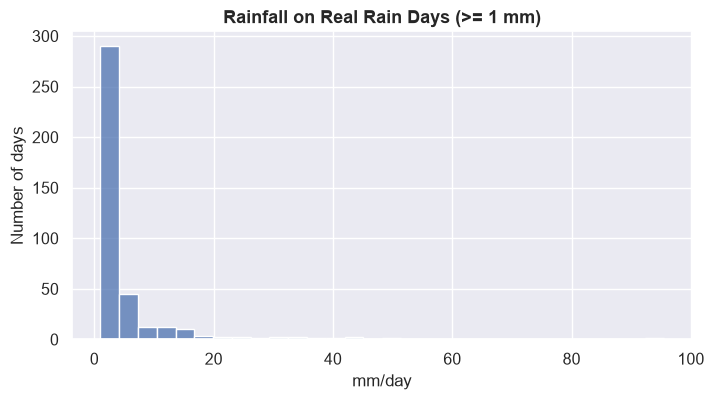

In [332]:
rain_days = weather[weather["precipitation"] >= 1]["precipitation"]

plt.figure(figsize=(8, 4))
sns.histplot(rain_days, bins=30)
plt.title("Rainfall on Real Rain Days (>= 1 mm)")
plt.xlabel("mm/day")
plt.ylabel("Number of days")
plt.show()

**What we see:** Most rain days are light: about 290 of the 387 rain days have less than about 4 mm. Only a handful pass 20 mm, and one day stands alone at 95.5 mm (30 Nov 2016).

**Why:** Cairo is a desert city. Most rain comes as short showers, and big storms are rare.

**What we do with it:** Forecast "rain or not" first. The amount is too rare and too extreme to forecast well: a few huge days would control the error.

## 3.2 Temporal Patterns

### 3.2.1 Full Time Range
Mean temperature and daily rainfall over all 36 years. The red line marks the start of 2016.

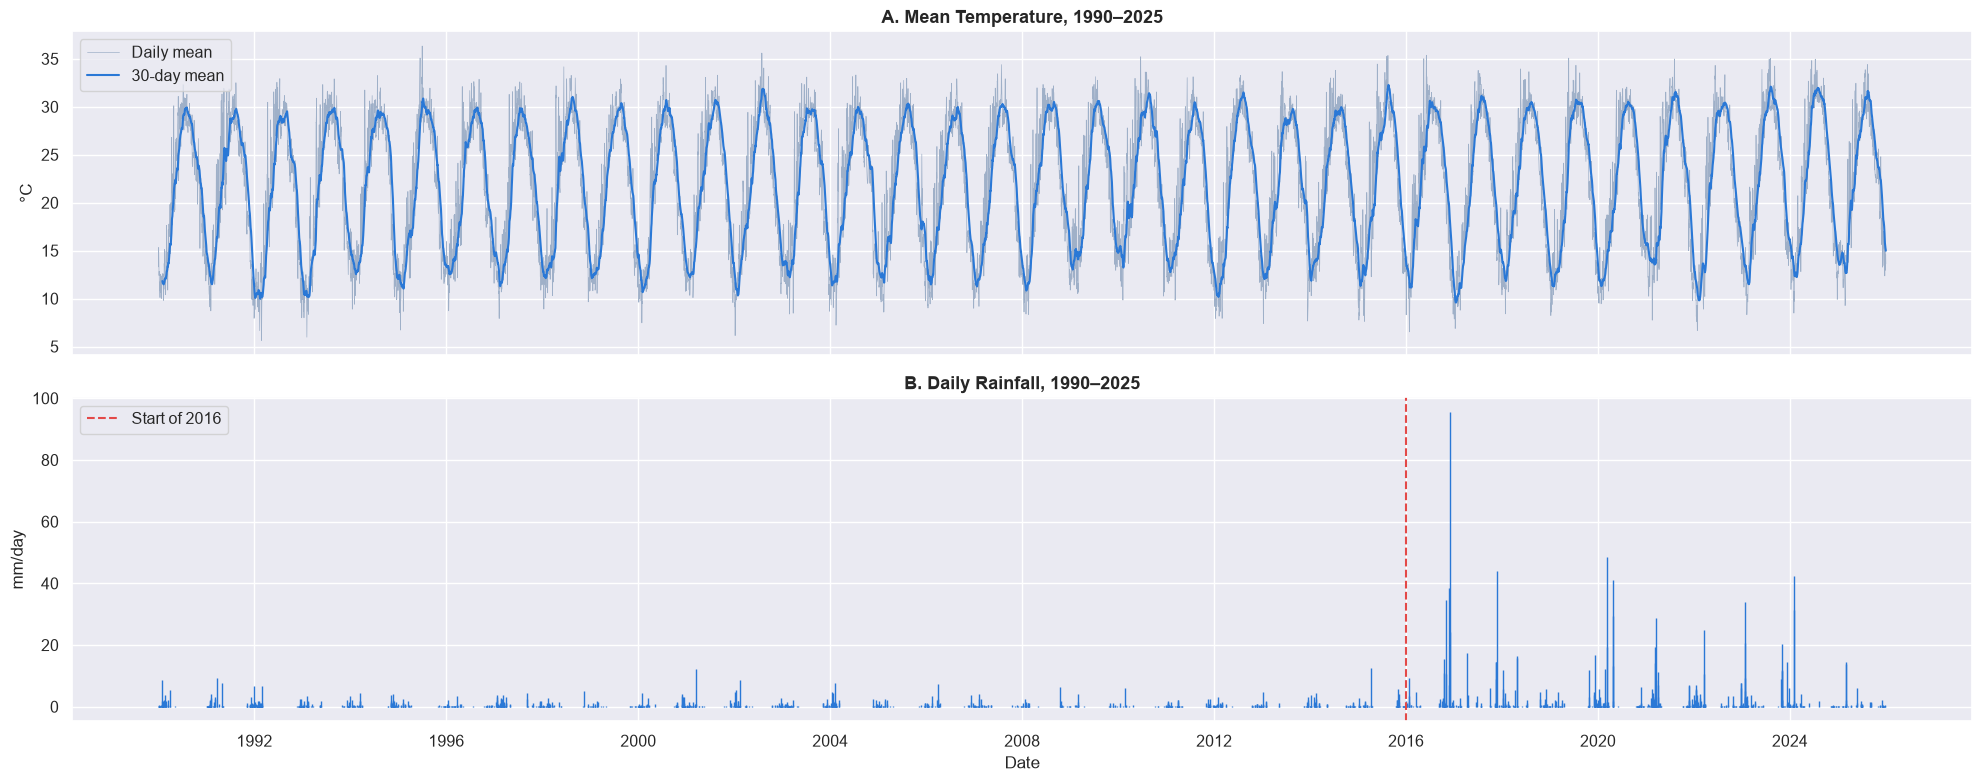

In [333]:
fig, ax = plt.subplots(nrows=2, figsize=(20, 8), sharex=True)

# A. Temperature: every day, and a 30-day mean to see the yearly wave
ax[0].plot(weather.index, weather["temp_mean"], color="#9fb0c8", linewidth=0.5, label="Daily mean")
ax[0].plot(weather.index, weather["temp_mean"].rolling(30).mean(), color="#2a78d6", linewidth=1.5, label="30-day mean")
ax[0].set_title("A. Mean Temperature, 1990–2025")
ax[0].set_ylabel("°C")
ax[0].legend(loc="upper left")

# B. Rainfall: one vertical line per day (thin bars would hide some days)
ax[1].vlines(weather.index, 0, weather["precipitation"], color="#2a78d6", linewidth=1)
ax[1].axvline(pd.Timestamp("2016-01-01"), color="#e34948", linestyle="--", label="Start of 2016")
ax[1].set_title("B. Daily Rainfall, 1990–2025")
ax[1].set_ylabel("mm/day")
ax[1].set_xlabel("Date")
ax[1].legend(loc="upper left")

plt.tight_layout()
plt.show()

**What we see:** Temperature repeats the same yearly wave 36 times, with no gaps: from about 10–15 °C in winter to about 29–32 °C in summer (30-day mean). Rain before 2016 never reaches 13 mm; from late 2016, many days reach 20–50 mm and one reaches 95.5 mm.

**Why:** The wave is the seasons. The rain jump is too sudden to be climate change, which would grow slowly.

**What we do with it:** The season is the main signal for temperature. Whether rain before 2016 can be used is decided in H3.

#### Zoom on two years (2019–2020)
We zoom on 2019–2020 to see the season day by day, and mark the March 2020 storm with a red line.

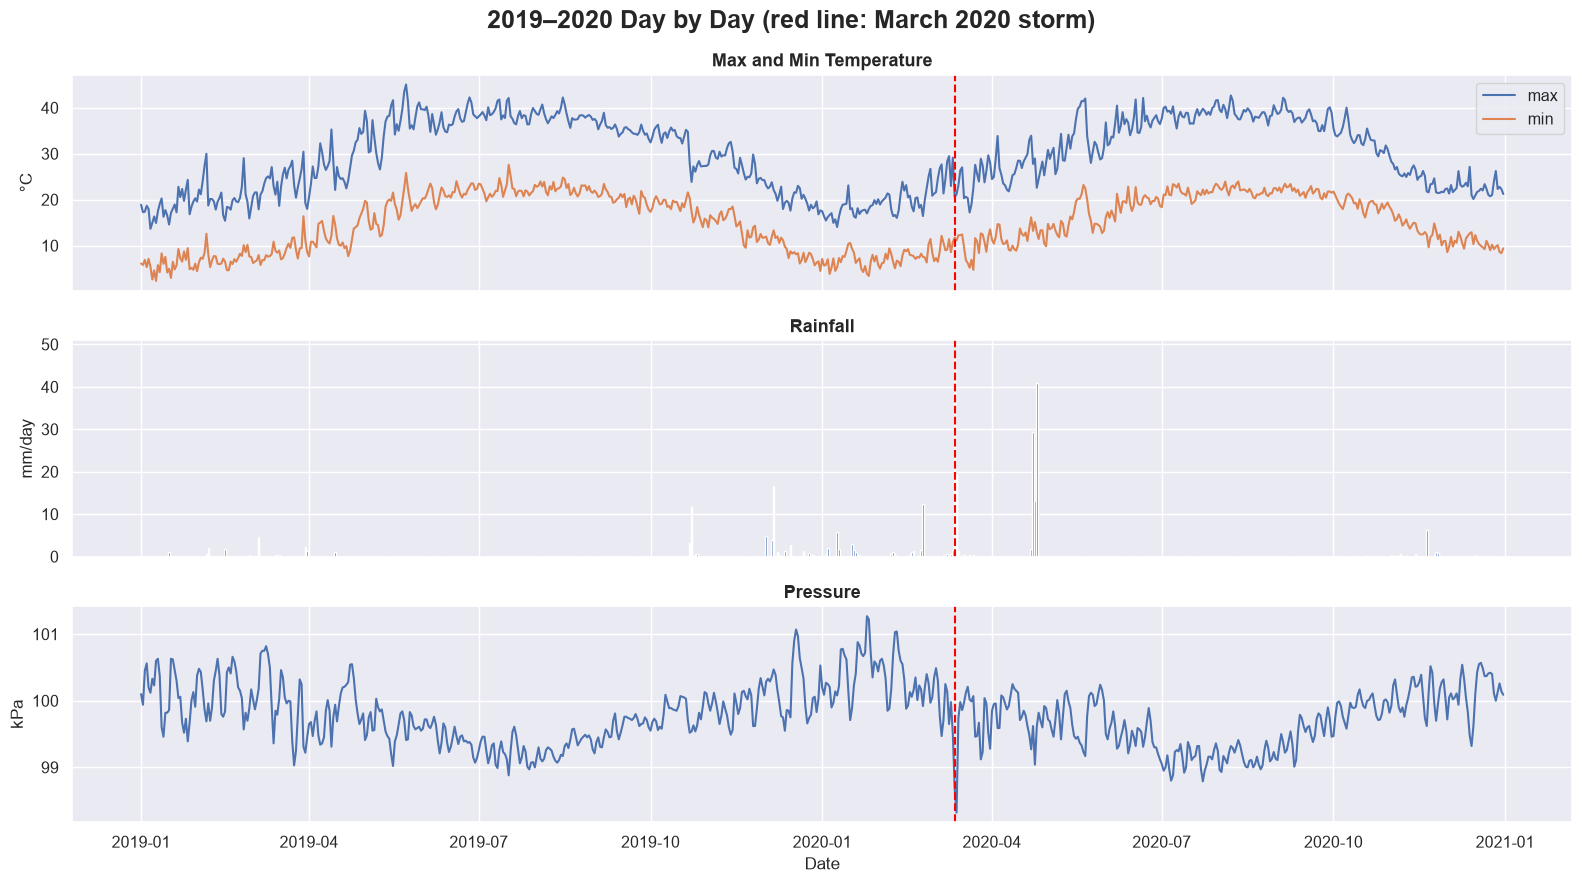

In [334]:
two_years = weather.loc["2019":"2020"]

fig, ax = plt.subplots(nrows=3, figsize=(16, 9), sharex=True)

ax[0].plot(two_years.index, two_years["temp_max"], label="max")
ax[0].plot(two_years.index, two_years["temp_min"], label="min")
ax[0].set_title("Max and Min Temperature")
ax[0].set_ylabel("°C")
ax[0].legend()

ax[1].bar(two_years.index, two_years["precipitation"])
ax[1].set_title("Rainfall")
ax[1].set_ylabel("mm/day")

ax[2].plot(two_years.index, two_years["pressure"])
ax[2].set_title("Pressure")
ax[2].set_ylabel("kPa")

# Red line on the March 2020 storm
for a in ax:
    a.axvline(pd.Timestamp("2020-03-12"), color="red", linestyle="--")

ax[-1].set_xlabel("Date")
plt.suptitle("2019–2020 Day by Day (red line: March 2020 storm)")
plt.tight_layout()
plt.show()

**What we see:**
- Max and min move together, about 15 °C apart. Summer is steady (max 38–42 °C). Spring has the biggest jumps: max can change by about 10 °C in a few days.
- Rain falls only from October to April. The March 2020 storm is on the red line, followed by two heavy rain days in late April 2020 (about 29 and 41 mm).
- Pressure is high in winter and low in summer. Around the storm it falls to about 98.3 kPa, the lowest in 36 years, after a warm day (max about 29 °C) that then drops to about 20 °C.

**Why:** In spring, hot desert air and cooler sea air take turns over Cairo, so temperature jumps. Storms come with low pressure: rising air builds clouds and rain.

**What we do with it:** The month is key for rain. A pressure drop after a warm day is a possible storm warning (tested in H5). Spring will be the hardest season to forecast.

### 3.2.2 Trend

#### Rolling mean
The daily line is noisy. A 30-day mean smooths the days and keeps the seasons; a 365-day mean removes the seasons and shows only the long-term trend.

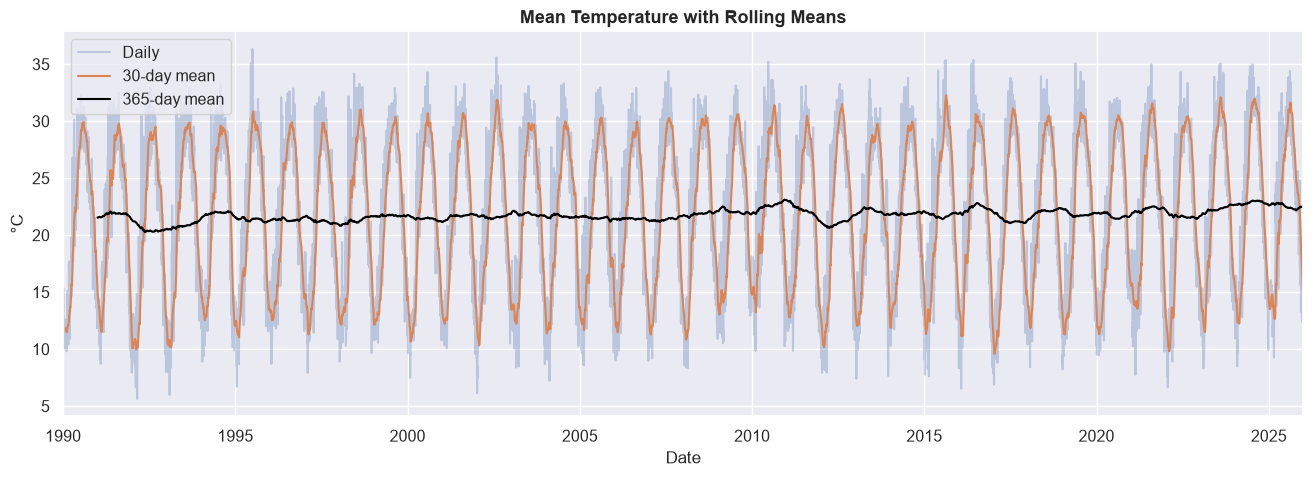

In [335]:
plt.figure(figsize=(16, 5))
weather["temp_mean"].plot(alpha=0.3, label="Daily")
weather["temp_mean"].rolling(30).mean().plot(label="30-day mean")
weather["temp_mean"].rolling(365).mean().plot(label="365-day mean", color="black")
plt.title("Mean Temperature with Rolling Means")
plt.xlabel("Date")
plt.ylabel("°C")
plt.legend()
plt.show()

**What we see:** The 30-day mean repeats the same wave every year (about 10–15 °C in winter, 29–32 °C in summer). The 365-day mean is almost flat, around 21.5–22 °C, with a dip in 1992, a peak around 2010, and a slow rise to 22.5–23 °C in 2023–2025.

**Why:** A 365-day window always holds one full year, so summer and winter cancel out and only the long-term level is left. 1992 was a cold year worldwide, after the Pinatubo volcano erupted in 1991.

**What we do with it:** The season (a swing of about 20 °C) matters far more than the trend (about 1 °C over 36 years). The model learns the season first; the small warming means the test years are slightly warmer than the training years.

#### H1. Is Cairo getting warmer, and are nights warming faster than days?
The yearly mean of max temperature (days) and min temperature (nights), with a straight line to measure the change per 10 years.

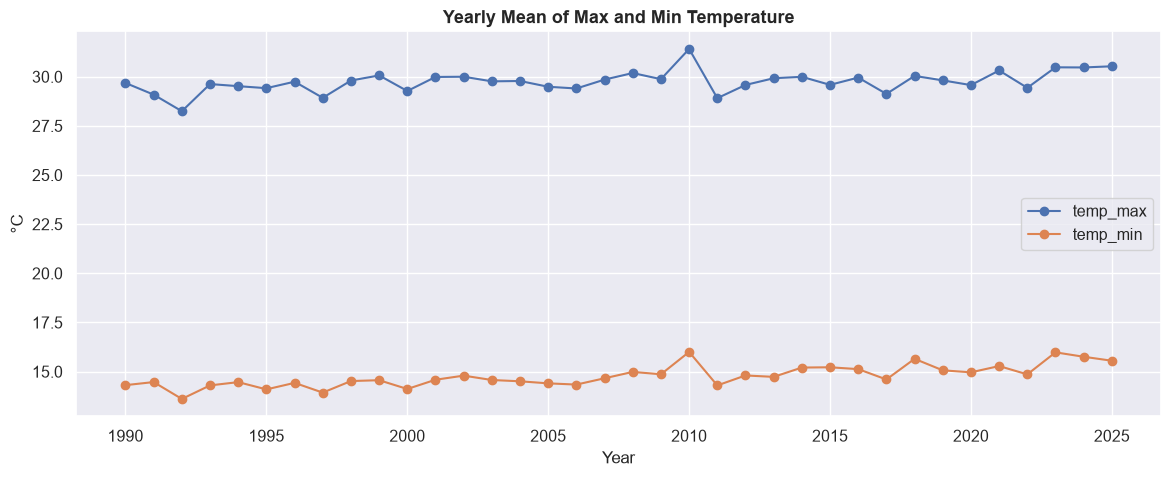

In [336]:
yearly = weather.groupby(weather.index.year)[["temp_max", "temp_min"]].mean()

yearly.plot(marker="o", figsize=(14, 5), title="Yearly Mean of Max and Min Temperature")
plt.xlabel("Year")
plt.ylabel("°C")
plt.show()

In [337]:
# Change per 10 years, from a straight line through the yearly means
for column in ["temp_max", "temp_min"]:
    slope = np.polyfit(yearly.index, yearly[column], 1)[0]
    print(column, "->", round(slope * 10, 2), "°C per 10 years")

temp_max -> 0.23 °C per 10 years
temp_min -> 0.41 °C per 10 years


**What we see:** Both lines rise slowly, but nights (min) rise faster: +0.41 °C per 10 years, against +0.23 °C for days (max). Over 36 years, that is about +1.5 °C at night and +0.8 °C by day.

**Why:** Cities hold heat at night: concrete and asphalt store the day's heat and release it after sunset. Global warming adds to both. This data alone cannot tell which cause is bigger.

**Answer to H1:** Yes. Cairo is getting warmer, and nights are warming almost twice as fast as days.

**What we do with it:** A model trained on older years may forecast nights a little too cold. We will check for this and, if needed, add a trend input or give recent years more weight.

#### H2. Are very hot days becoming more frequent?
A very hot day is a day hotter than 95% of all days (above the 95th percentile of max temperature). We count them in each year.

Very hot day: max temperature above 40.1 °C


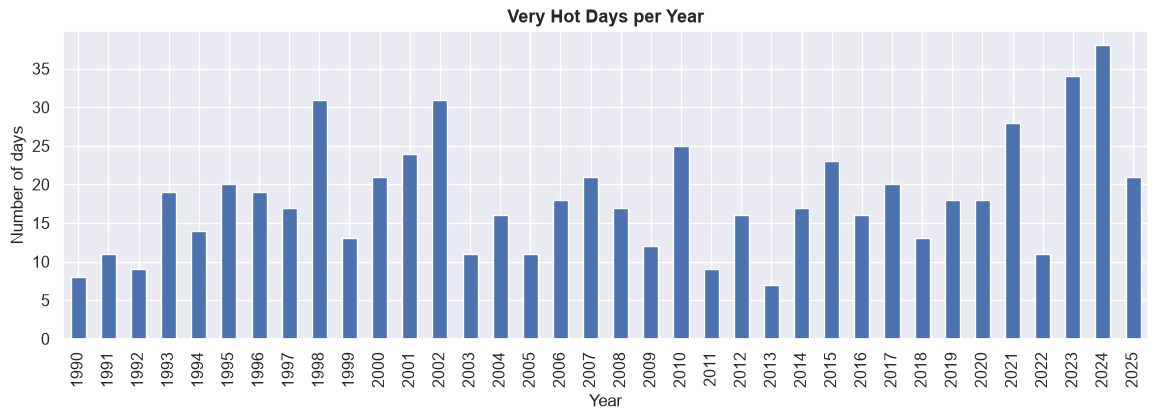

In [338]:
HOT_LIMIT = weather["temp_max"].quantile(0.95)
print("Very hot day: max temperature above", round(HOT_LIMIT, 1), "°C")

hot_days = (weather["temp_max"] > HOT_LIMIT).groupby(weather.index.year).sum()

hot_days.plot(kind="bar", figsize=(14, 4), title="Very Hot Days per Year")
plt.xlabel("Year")
plt.ylabel("Number of days")
plt.show()

**What we see:** A very hot day is above 40.1 °C. Their number jumps from year to year (7 in 2013, 38 in 2024). High years appear in every decade (1998, 2002, 2010), but the two highest are the latest: 2023 (34 days) and 2024 (38).

**Why:** Heat waves depend on weather patterns that change a lot from year to year; warming makes them a little more likely every year.

**Answer to H2:** Partly. The recent years are the most extreme, but the years jump so much that a few more years are needed to call it a clear trend.

**What we do with it:** The test years (2023–2025) have the hottest summers, so the model may under-forecast heat waves. We check errors on very hot days separately.

#### H3. Did heavy rain really increase after 2016, or did the data change?
Real rain days (≥ 1 mm), heavy rain days (≥ 10 mm) and total rain in each year. The red line marks the start of 2016. A slow rise over many years points to a real change; a sudden jump at one year points to a change in the data.

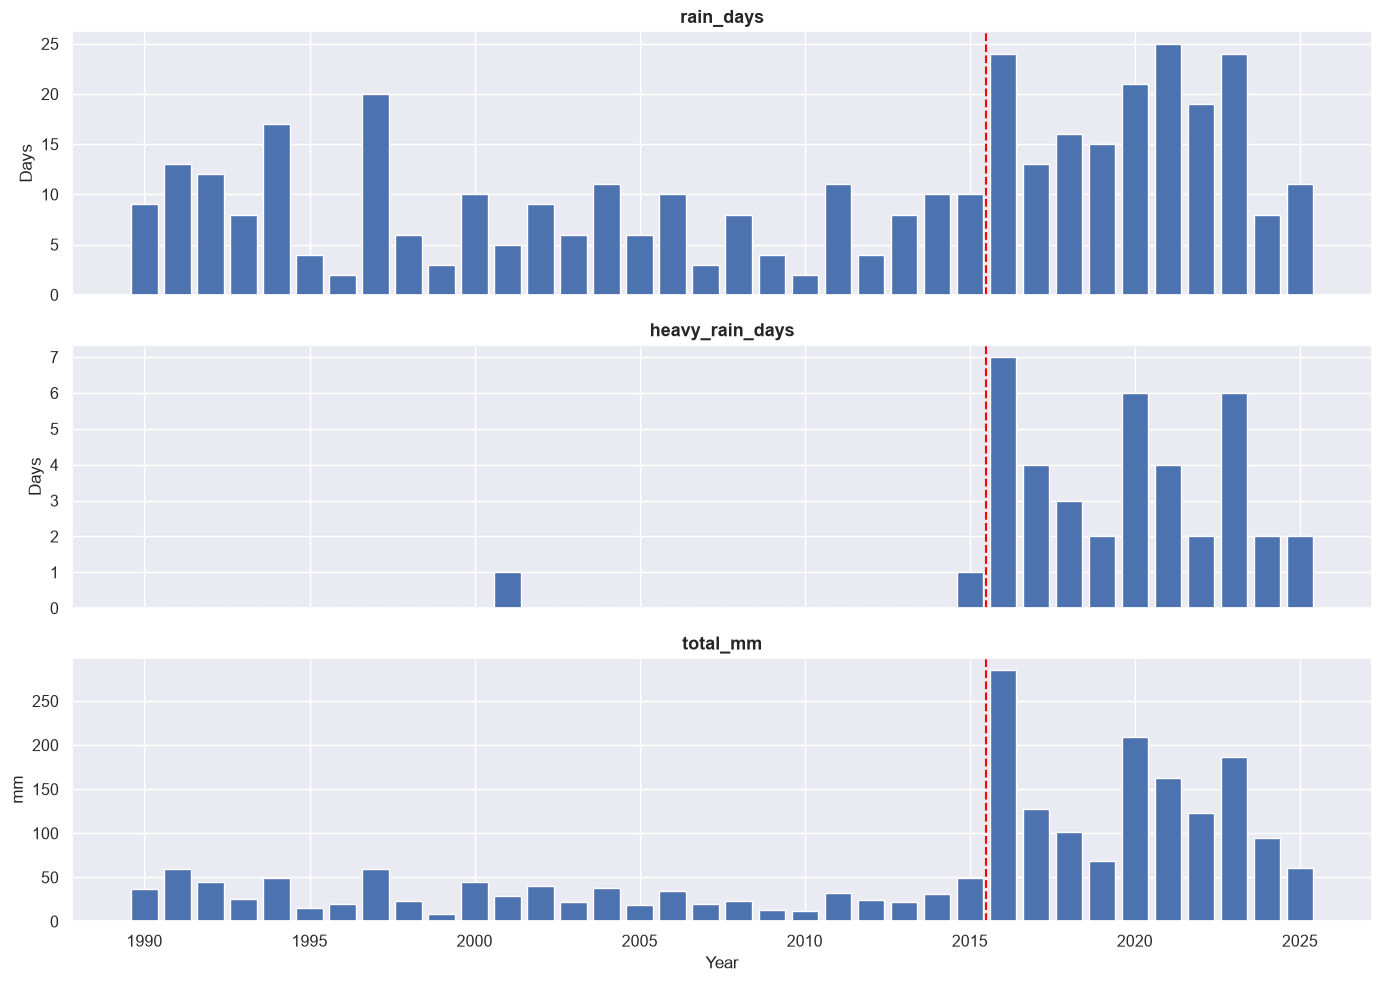

In [339]:
rain_per_year = pd.DataFrame({
    "rain_days": (weather["precipitation"] >= 1).groupby(weather.index.year).sum(),
    "heavy_rain_days": (weather["precipitation"] >= 10).groupby(weather.index.year).sum(),
    "total_mm": weather["precipitation"].groupby(weather.index.year).sum(),
})

fig, ax = plt.subplots(nrows=3, figsize=(14, 10), sharex=True)
for i, column in enumerate(rain_per_year.columns):
    ax[i].bar(rain_per_year.index, rain_per_year[column])
    ax[i].axvline(2015.5, color="red", linestyle="--")
    ax[i].set_title(column)
ax[0].set_ylabel("Days")
ax[1].set_ylabel("Days")
ax[2].set_ylabel("mm")
ax[-1].set_xlabel("Year")
plt.tight_layout()
plt.show()

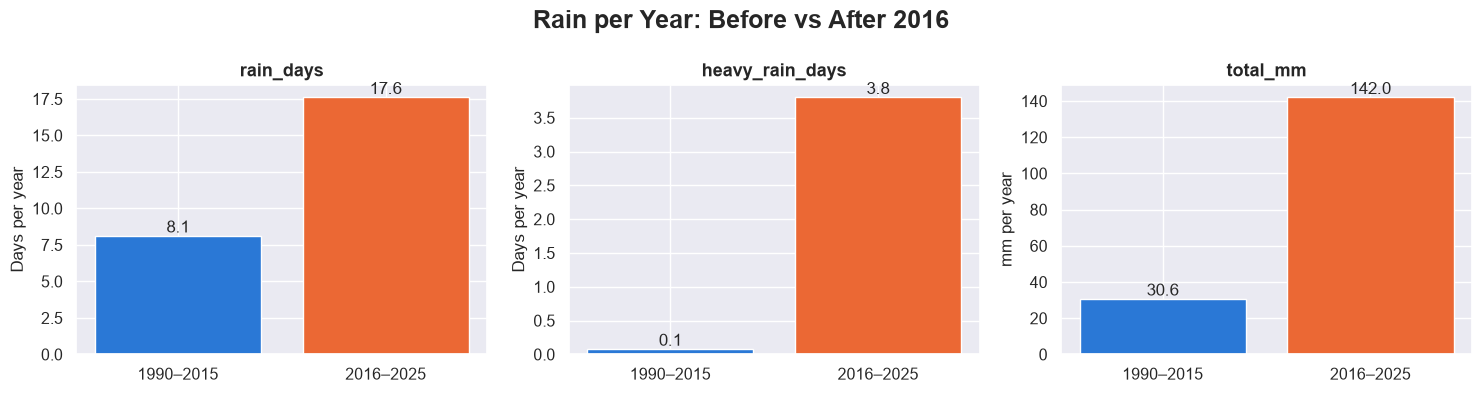

In [340]:
RAIN_UNITS = {"rain_days": "Days per year", "heavy_rain_days": "Days per year", "total_mm": "mm per year"}

fig, ax = plt.subplots(ncols=3, figsize=(15, 4))
for i, column in enumerate(rain_per_year.columns):
    values = [rain_per_year.loc[1990:2015, column].mean(), rain_per_year.loc[2016:2025, column].mean()]
    ax[i].bar(["1990–2015", "2016–2025"], values, color=[BEFORE_COLOR, AFTER_COLOR])
    for k, value in enumerate(values):
        ax[i].text(k, value, str(round(value, 1)), ha="center", va="bottom", fontsize=12)
    ax[i].set_title(column)
    ax[i].set_ylabel(RAIN_UNITS[column])
plt.suptitle("Rain per Year: Before vs After 2016")
plt.tight_layout()
plt.show()

**What we see:** After 2016, rain days double (8.1 → 17.6 per year), heavy rain days (≥ 10 mm) go from 0.1 to 3.8 per year, and total rain grows 4.6 times (30.6 → 142 mm per year). But the storms did not get stronger: the strongest wind (5.97 → 5.59 m/s) and the lowest pressure (98.80 → 98.77 kPa) stay the same.

**Why it is probably the data, not the weather:**
1. The jump happens suddenly in 2016 (Step 2.3). Real climate change is slow.
2. 142 mm per year would be 5–6 times Cairo's usual 20–25 mm, which is not realistic. Before 2016, about 31 mm per year is close to normal.
3. Wind and pressure in storms did not change; only the rain did.

**Answer to H3:** Most likely a change in the data. Rain days after 2016 seem real (the March 2020 storm shows in every variable), but the amounts look inflated.

**What we do with it:** The rain model uses 2016–2025 only. Temperature models can still use all 36 years.

#### H4. Are cold waves becoming rarer? Which years were the strongest?
A very cold night is a night colder than 95% of all nights (below the 5th percentile of min temperature). We count them in each year, and measure the change per 10 years.

Very cold night: min temperature below 5.7 °C


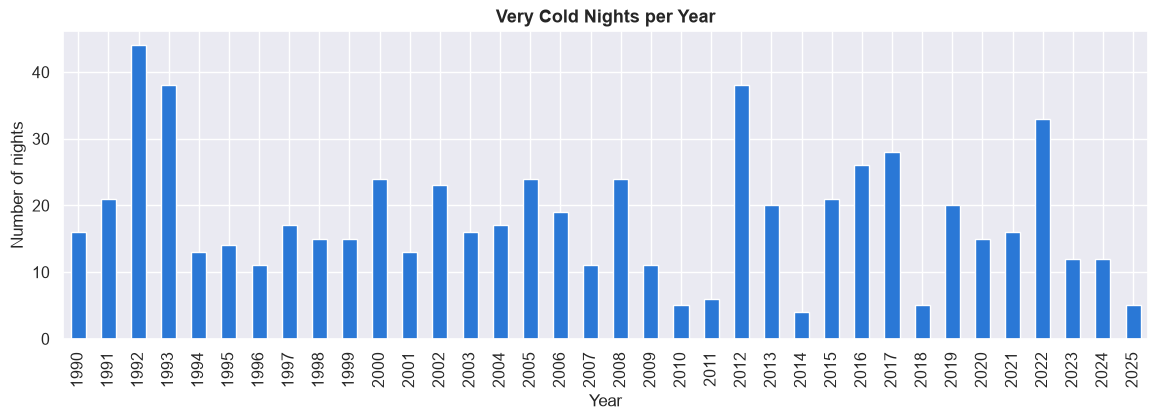

In [341]:
COLD_LIMIT = weather["temp_min"].quantile(0.05)
print("Very cold night: min temperature below", round(COLD_LIMIT, 1), "°C")

cold_nights = (weather["temp_min"] < COLD_LIMIT).groupby(weather.index.year).sum()

cold_nights.plot(kind="bar", figsize=(14, 4), color="#2a78d6", title="Very Cold Nights per Year")
plt.xlabel("Year")
plt.ylabel("Number of nights")
plt.show()

In [342]:
# The 5 years with the most very cold nights
print(cold_nights.sort_values(ascending=False).head())

# Change per 10 years, from a straight line through the yearly counts
slope = np.polyfit(cold_nights.index, cold_nights, 1)[0]
print("Change:", round(slope * 10, 1), "very cold nights per 10 years")

date
1992    44
1993    38
2012    38
2022    33
2017    28
Name: temp_min, dtype: int64
Change: -1.9 very cold nights per 10 years


**What we see:** A very cold night is below 5.7 °C. The coldest years are 1992 (44 nights), 1993 (38), 2012 (38) and 2022 (33). The average per decade falls from 20.4 (1990s) to 18.2, 17.3 and 15.5 (2020–2025): about −1.9 nights per 10 years. Years still jump: 2022 had 33, 2025 only 5.

**Why:** Nights are warming fastest (H1), so fewer of them drop below 5.7 °C. 1992–1993 were cold worldwide after the Pinatubo eruption.

**Answer to H4:** Yes, slowly. Cold nights are getting rarer, but a strong cold year can still happen, like 2022.

**What we do with it:** Cold snaps are rarer in the test years (12, 12 and 5 nights) than in training, but they still happen. We check errors on very cold nights separately.

### 3.2.3 Seasonality

#### Boxplots by month
One box for each month: the line in the middle is the median, the box holds the middle 50% of days, and the dots are unusual days for that month.

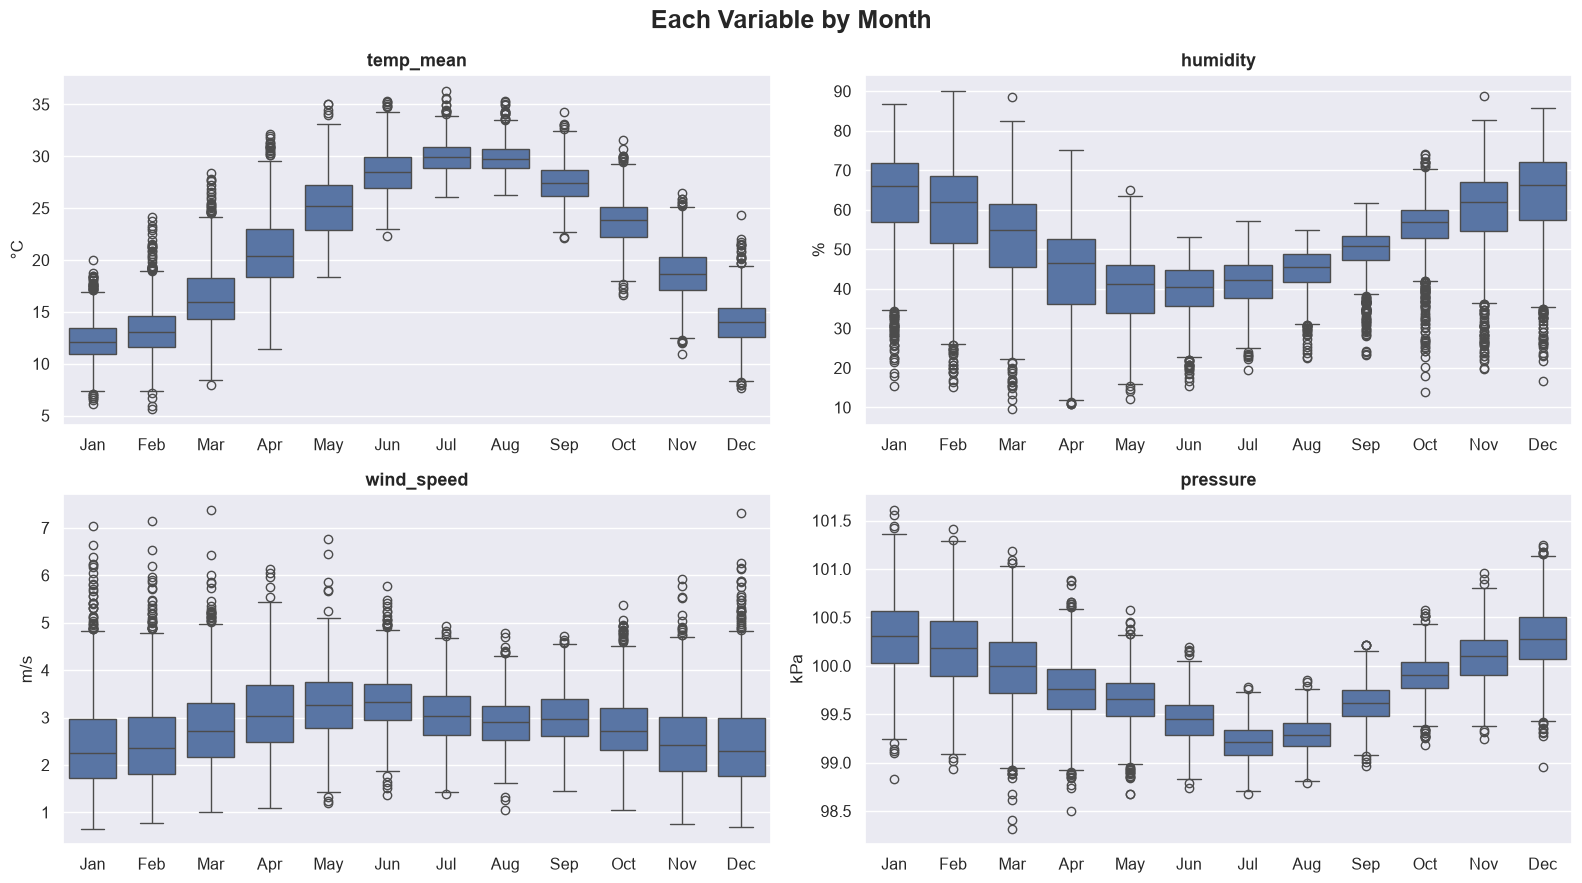

In [343]:
fig, ax = plt.subplots(nrows=2, ncols=2, figsize=(16, 9))
ax = ax.flatten()
for i, column in enumerate(["temp_mean", "humidity", "wind_speed", "pressure"]):
    sns.boxplot(x=weather.index.month, y=weather[column], ax=ax[i])
    ax[i].set_xticks(range(12))
    ax[i].set_xticklabels(MONTHS)
    ax[i].set_title(column)
    ax[i].set_xlabel("")
    ax[i].set_ylabel(UNITS[column])
plt.suptitle("Each Variable by Month")
plt.tight_layout()
plt.show()

**What we see:**
- **Temperature:** median 12.1 °C in January, 29.9 °C in July. The boxes are widest in March–May (4.0–4.6 °C) and narrowest in July–August (about 2 °C).
- **Humidity:** the opposite: about 66 % in December–January, 41 % in May–June.
- **Wind speed:** a small cycle, strongest in May–June (3.3 m/s), weakest in December–January (2.3 m/s).
- **Pressure:** highest in January (100.3 kPa), lowest in July (99.2 kPa).

**Why:** Warm air can hold more water, so the same moisture gives a lower humidity in summer. Hot ground heats the air above it, which rises and lowers the pressure in summer. Spring boxes are wide because spring switches between winter-like and summer-like days.

**What we do with it:** Give the model the day of year as sine and cosine, so 31 December and 1 January count as neighbors. Expect the biggest errors in spring.

#### Rain days by month
Average number of real rain days (≥ 1 mm) in each month. Only 2016–2025 is used, because rain before 2016 is not consistent with rain after it (H3).

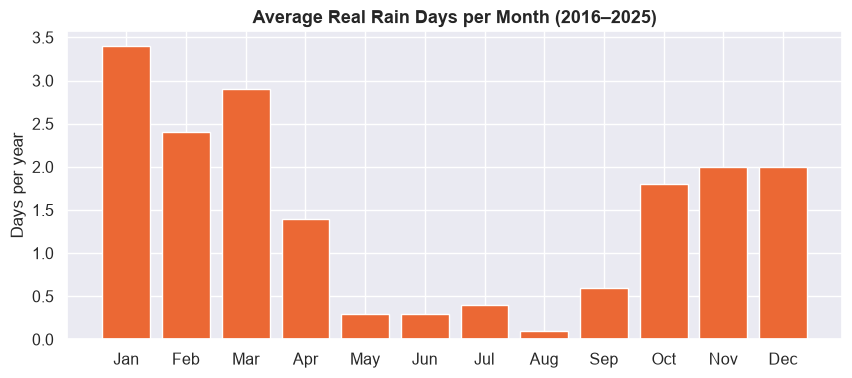

In [344]:
recent = weather.loc["2016":"2025"]
rain_days_per_month = (recent["precipitation"] >= 1).groupby(recent.index.month).sum() / 10

plt.figure(figsize=(10, 4))
plt.bar(MONTHS, rain_days_per_month, color=AFTER_COLOR)
plt.title("Average Real Rain Days per Month (2016–2025)")
plt.ylabel("Days per year")
plt.show()

**What we see:** January has the most rain days (3.4 per year), then March (2.9) and February (2.4). October to December have about 2. May to September have less than 1 (0.1–0.6).

**Why:** Cairo's rain comes from Mediterranean storms, which pass in the cool months. In summer, a stable high-pressure system keeps the sky clear.

**What we do with it:** The month is a strong first guess for rain. In summer "no rain" is almost always right, so the real test of a rain model is October–April. The seasonal baseline in Part 4 uses these monthly chances.

#### Seasonal plot: one line per year
The monthly mean of min temperature for every year. Each gray line is one year; 1992 (the coldest year) is in blue and 2024 (one of the hottest) is in red. A line far below the others marks a year with a strong cold wave.

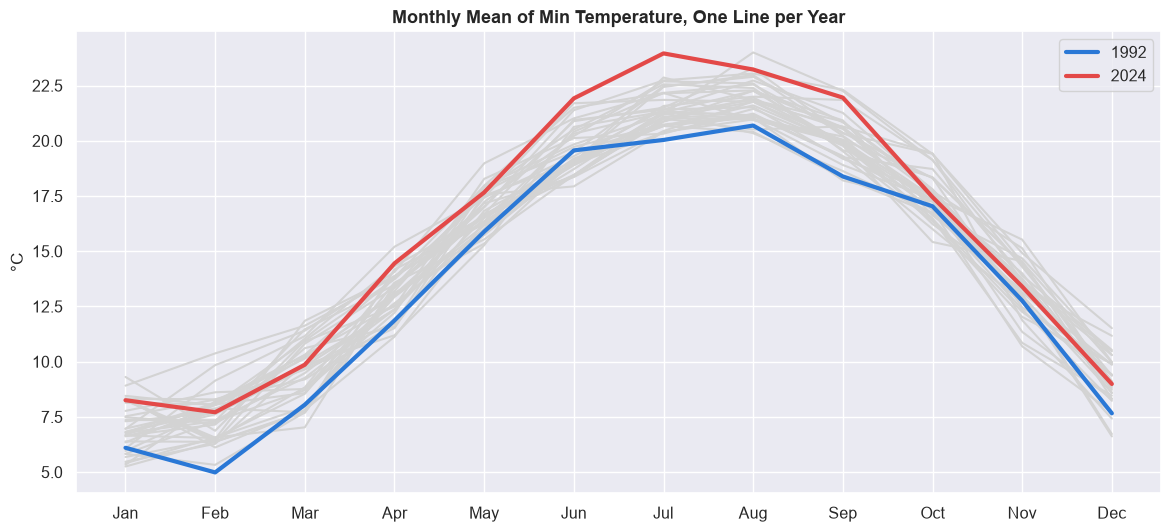

In [345]:
monthly_min = weather.groupby([weather.index.year, weather.index.month])["temp_min"].mean().unstack(level=0)

ax = monthly_min.plot(figsize=(14, 6), color="lightgray", legend=False)
monthly_min[1992].plot(ax=ax, color="#2a78d6", linewidth=3, label="1992")
monthly_min[2024].plot(ax=ax, color="#e34948", linewidth=3, label="2024")
ax.legend(handles=ax.lines[-2:])
ax.set_xticks(range(1, 13))
ax.set_xticklabels(MONTHS)
plt.title("Monthly Mean of Min Temperature, One Line per Year")
plt.xlabel("")
plt.ylabel("°C")
plt.show()

**What we see:** Every year has the same shape. 1992 is the lowest line in late winter and spring (February 5.0 °C, against a normal of 7.4 °C). 2024 is normal in winter but the highest line in summer (July 24.0 °C, against 21.4 °C).

**Why:** The sun sets the shape of the year, so it never changes. But a whole season can sit 2–3 °C above or below normal for months, depending on that year's weather.

**What we do with it:** The calendar alone cannot see these shifts; the last days and weeks can. So the model gets recent values (lags and rolling means) on top of the season.

#### Weekly cycle check
Weather has no reason to follow the days of the week, so all seven boxes should look the same. If they do, day of week is not a useful feature.

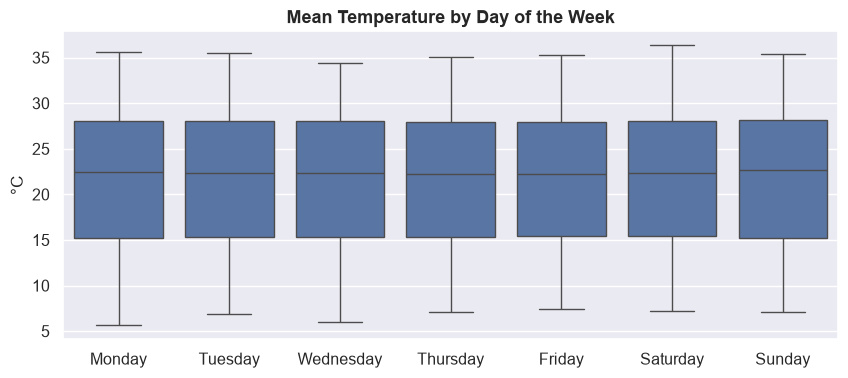

In [346]:
WEEKDAYS = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]

plt.figure(figsize=(10, 4))
sns.boxplot(x=weather.index.day_name(), y=weather["temp_mean"], order=WEEKDAYS)
plt.title("Mean Temperature by Day of the Week")
plt.xlabel("")
plt.ylabel("°C")
plt.show()

**What we see:** All seven boxes look the same: the median is 22.2–22.7 °C on every day of the week.

**Why:** The weather does not know what day of the week it is.

**What we do with it:** Day of week is not used as a feature, even though it is common in other forecasting problems such as sales.

### 3.2.4 Rolling Statistics (Volatility)
How much the temperature jumps from day to day. A: the 30-day rolling standard deviation over 36 years. B: the average day-to-day variability in each month.

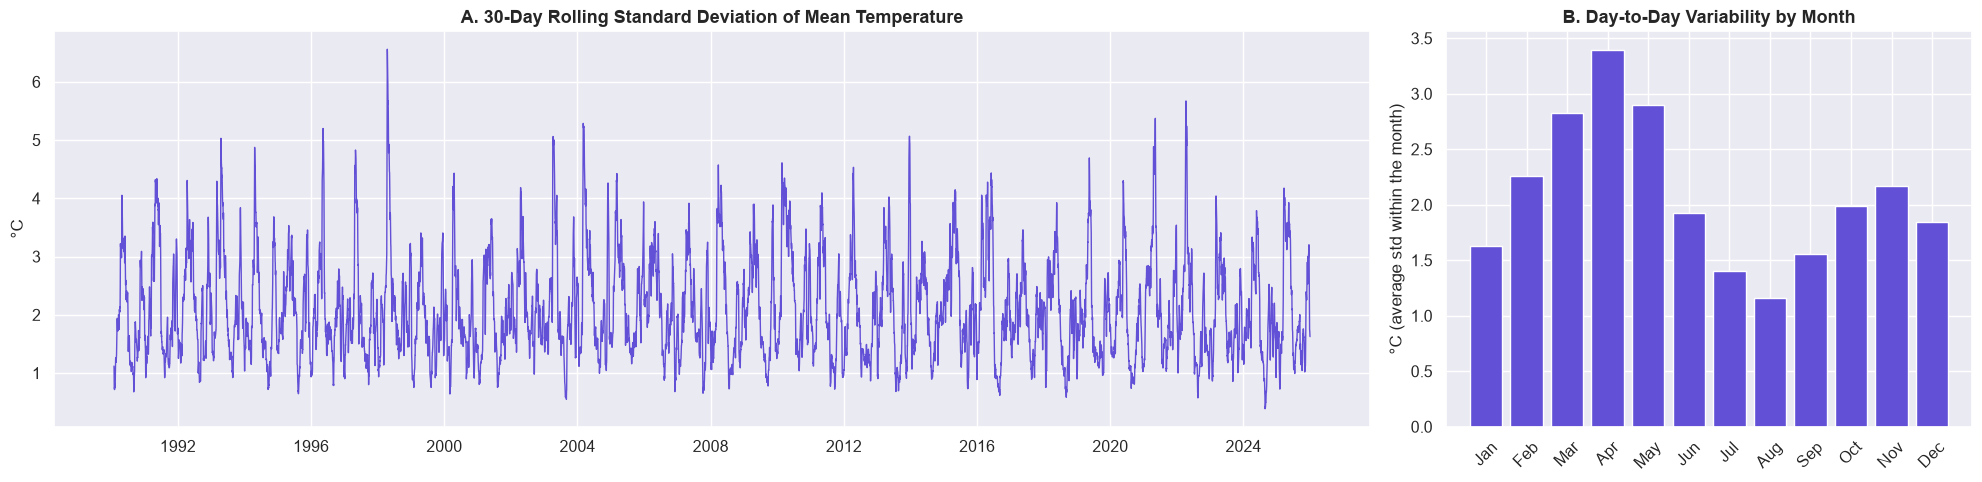

In [347]:
rolling_std = weather["temp_mean"].rolling(30).std()
std_by_month = weather["temp_mean"].groupby([weather.index.year, weather.index.month]).std().groupby(level=1).mean()

fig, ax = plt.subplots(ncols=2, figsize=(20, 5), gridspec_kw={"width_ratios": [3, 1.2]})

ax[0].plot(rolling_std.index, rolling_std, color="#6250d6", linewidth=1)
ax[0].set_title("A. 30-Day Rolling Standard Deviation of Mean Temperature")
ax[0].set_ylabel("°C")

ax[1].bar(MONTHS, std_by_month, color="#6250d6")
ax[1].set_title("B. Day-to-Day Variability by Month")
ax[1].set_ylabel("°C (average std within the month)")
ax[1].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

**What we see:**
- **A:** The 30-day spread moves between 0.4 and 6.6 °C, rising every spring and autumn. The highest is in April 1998.
- **B:** Within a month, temperature moves most in April (3.4 °C) and least in August (1.2 °C). From one day to the next, the average change is 2.0 °C in April and 0.6 °C in August.

**Why:** In spring, hot desert air and cool sea air take turns, so days swing a lot. In August, the same hot air sits over Cairo for weeks. Part of the spring rise in A is also the season itself warming fast.

**What we do with it:** Errors will not be the same all year: "tomorrow = today" misses about three times more in April than in August. We report errors by month and season, not only as one number.

## 3.3 Decomposition and Structure

### 3.3.1 Decomposition
The series is split into three parts: **trend** (the slow long-term change), **seasonal** (the pattern that repeats every 365 days) and **residual** (what is left: weather surprises). Both models are compared:
- **Additive:** temperature = trend + seasonal + residual. Best when the size of the seasonal swing stays the same over the years.
- **Multiplicative:** temperature = trend × seasonal × residual. Best when the seasonal swing grows as the level grows.

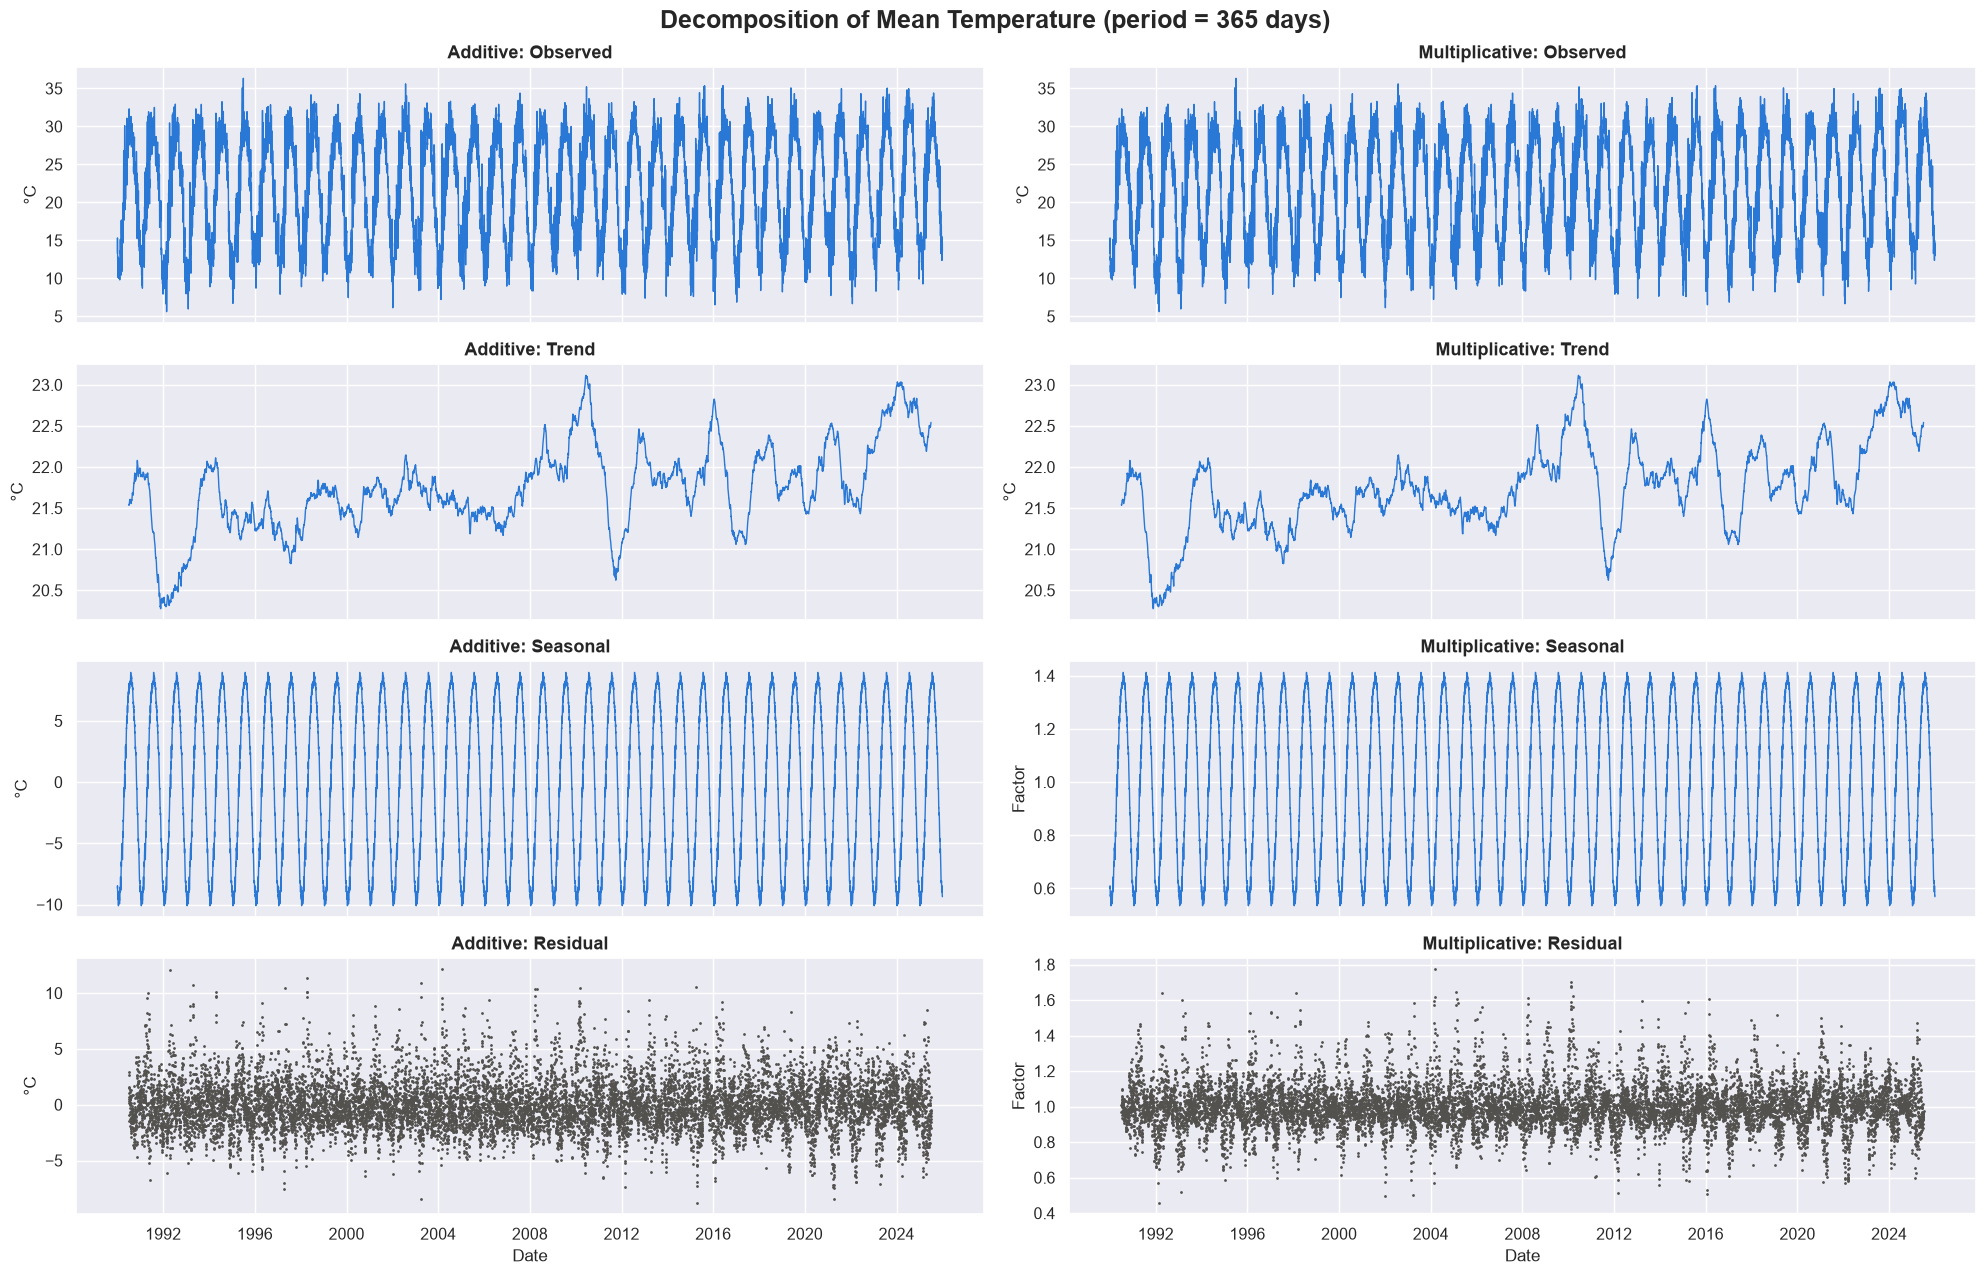

In [348]:
additive = seasonal_decompose(weather["temp_mean"], model="additive", period=365)
multiplicative = seasonal_decompose(weather["temp_mean"], model="multiplicative", period=365)

fig, ax = plt.subplots(nrows=4, ncols=2, figsize=(20, 13), sharex=True)
for j, (name, result) in enumerate([("Additive", additive), ("Multiplicative", multiplicative)]):
    parts = [("Observed", result.observed), ("Trend", result.trend), ("Seasonal", result.seasonal), ("Residual", result.resid)]
    for i, (part_name, part) in enumerate(parts):
        if part_name == "Residual":
            ax[i, j].scatter(part.index, part, s=1, color="#52514e")
        else:
            ax[i, j].plot(part.index, part, color="#2a78d6", linewidth=1)
        ax[i, j].set_title(name + ": " + part_name)
        # Multiplicative season and residual are factors around 1, not degrees
        is_factor = name == "Multiplicative" and part_name in ("Seasonal", "Residual")
        ax[i, j].set_ylabel("Factor" if is_factor else "°C")
    ax[-1, j].set_xlabel("Date")

plt.suptitle("Decomposition of Mean Temperature (period = 365 days)")
plt.tight_layout()
plt.show()

**What we see:** The additive and multiplicative versions look almost the same, and what is left over has the same size (2.22 vs 2.23 °C). The yearly swing does not grow when the level goes up: it stays between 16.3 and 21.4 °C.

**Why:** Multiplicative fits when the swings grow with the level, like sales that grow with a company. Cairo's seasons swing by about the same amount every year, so adding them is enough.

**What we do with it:** Use the additive form: temperature = trend + season + leftover. No log scale needed.

#### Zoom on 2018–2020
The red line (trend + seasonal) is what the model can learn from the calendar; the residual is what it must learn from recent days.

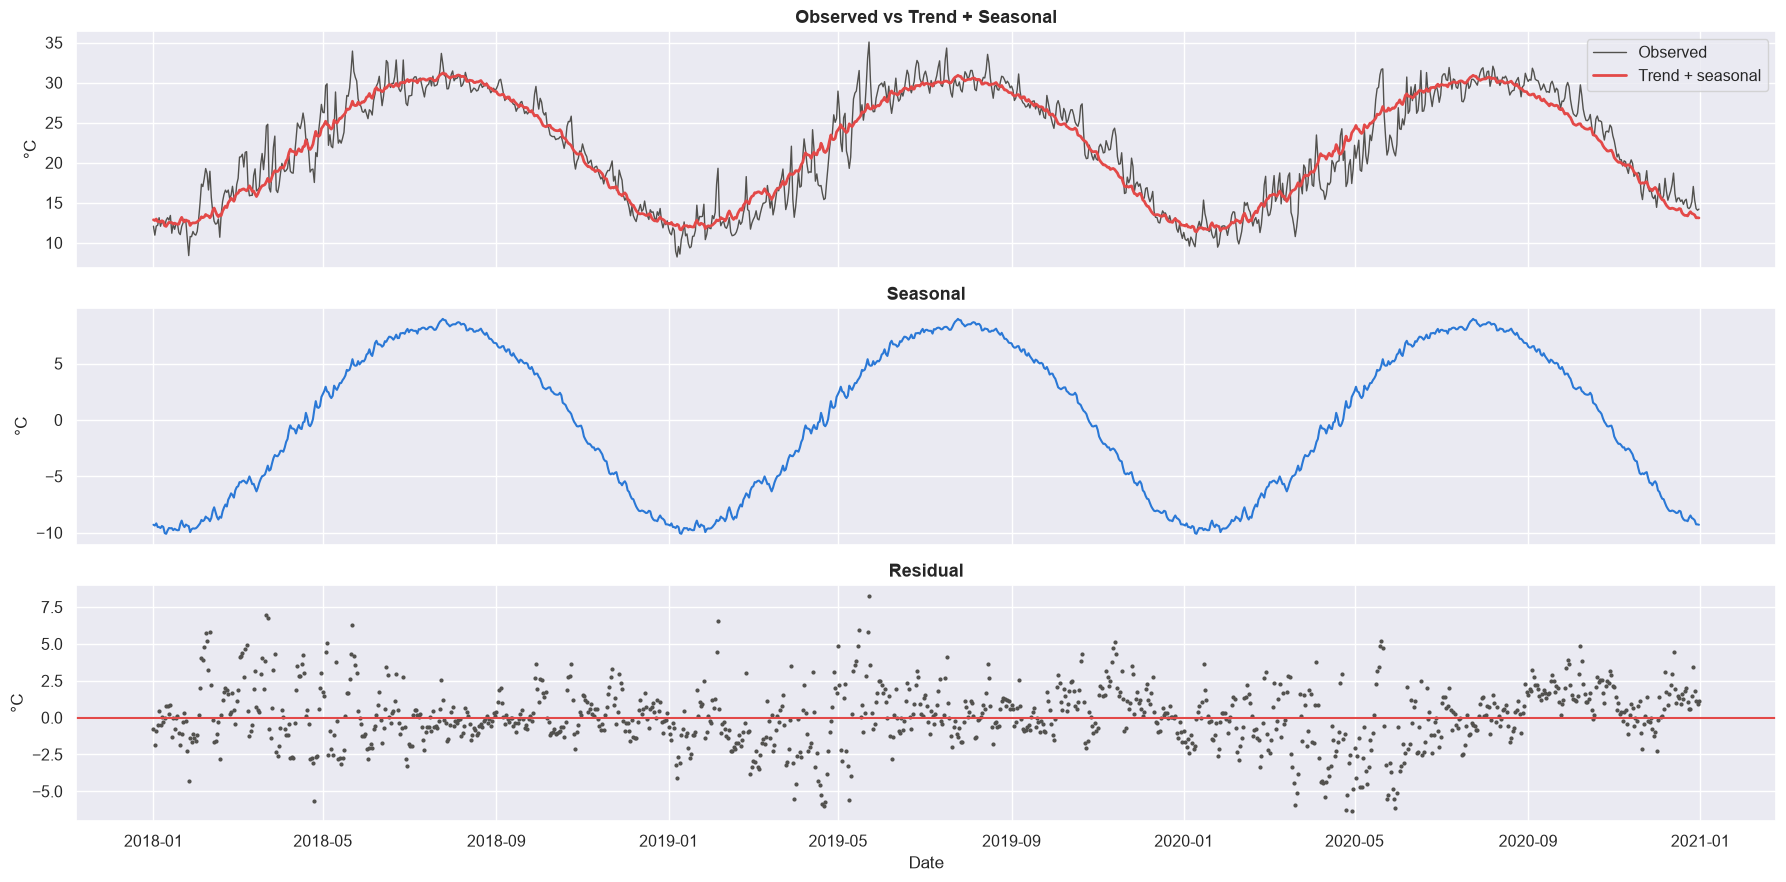

In [349]:
zoom = slice("2018", "2020")

fig, ax = plt.subplots(nrows=3, figsize=(18, 9), sharex=True)
ax[0].plot(additive.observed[zoom], color="#52514e", linewidth=1, label="Observed")
ax[0].plot(additive.trend[zoom] + additive.seasonal[zoom], color="#e34948", linewidth=2, label="Trend + seasonal")
ax[0].set_title("Observed vs Trend + Seasonal")
ax[0].legend()
ax[1].plot(additive.seasonal[zoom], color="#2a78d6")
ax[1].set_title("Seasonal")
ax[2].scatter(additive.resid[zoom].index, additive.resid[zoom], s=4, color="#52514e")
ax[2].axhline(0, color="#e34948")
ax[2].set_title("Residual")
for a in ax:
    a.set_ylabel("°C")
ax[-1].set_xlabel("Date")
plt.tight_layout()
plt.show()

In [350]:
# How big is each part, in °C
print("Seasonal swing:", round(additive.seasonal.max() - additive.seasonal.min(), 1), "°C")
print("Trend change:", round(additive.trend.max() - additive.trend.min(), 1), "°C")
print("Residual std:", round(additive.resid.std(), 1), "°C")

Seasonal swing: 19.1 °C
Trend change: 2.8 °C
Residual std: 2.2 °C


**What we see:** The season swings by 19.1 °C, about 7 times more than the trend moves (2.8 °C, including warm and cold years). The leftover is about 2.2 °C a day: largest in April (3.3 °C), smallest in August (1.3 °C).

**Why:** The calendar explains most of the temperature. The leftover is the day-to-day weather that the calendar cannot know.

**What we do with it:** This leftover is what the model must learn from the recent days. A good model must beat a forecast that only knows the season.

### 3.3.2 Autocorrelation (ACF and PACF)
A lag is a past value: lag 1 is yesterday, lag 7 is a week ago, lag 365 is the same day last year.
- **ACF:** the correlation between today and each past day.
- **PACF:** the direct correlation only, after removing what the days in between already explain.

The PACF uses the daily change (`diff()`), because the season makes every nearby day look related.
A: the yearly cycle · B and C: how many past days matter for temperature · D: does rain today make rain tomorrow more likely? (2016–2025 only, H3)

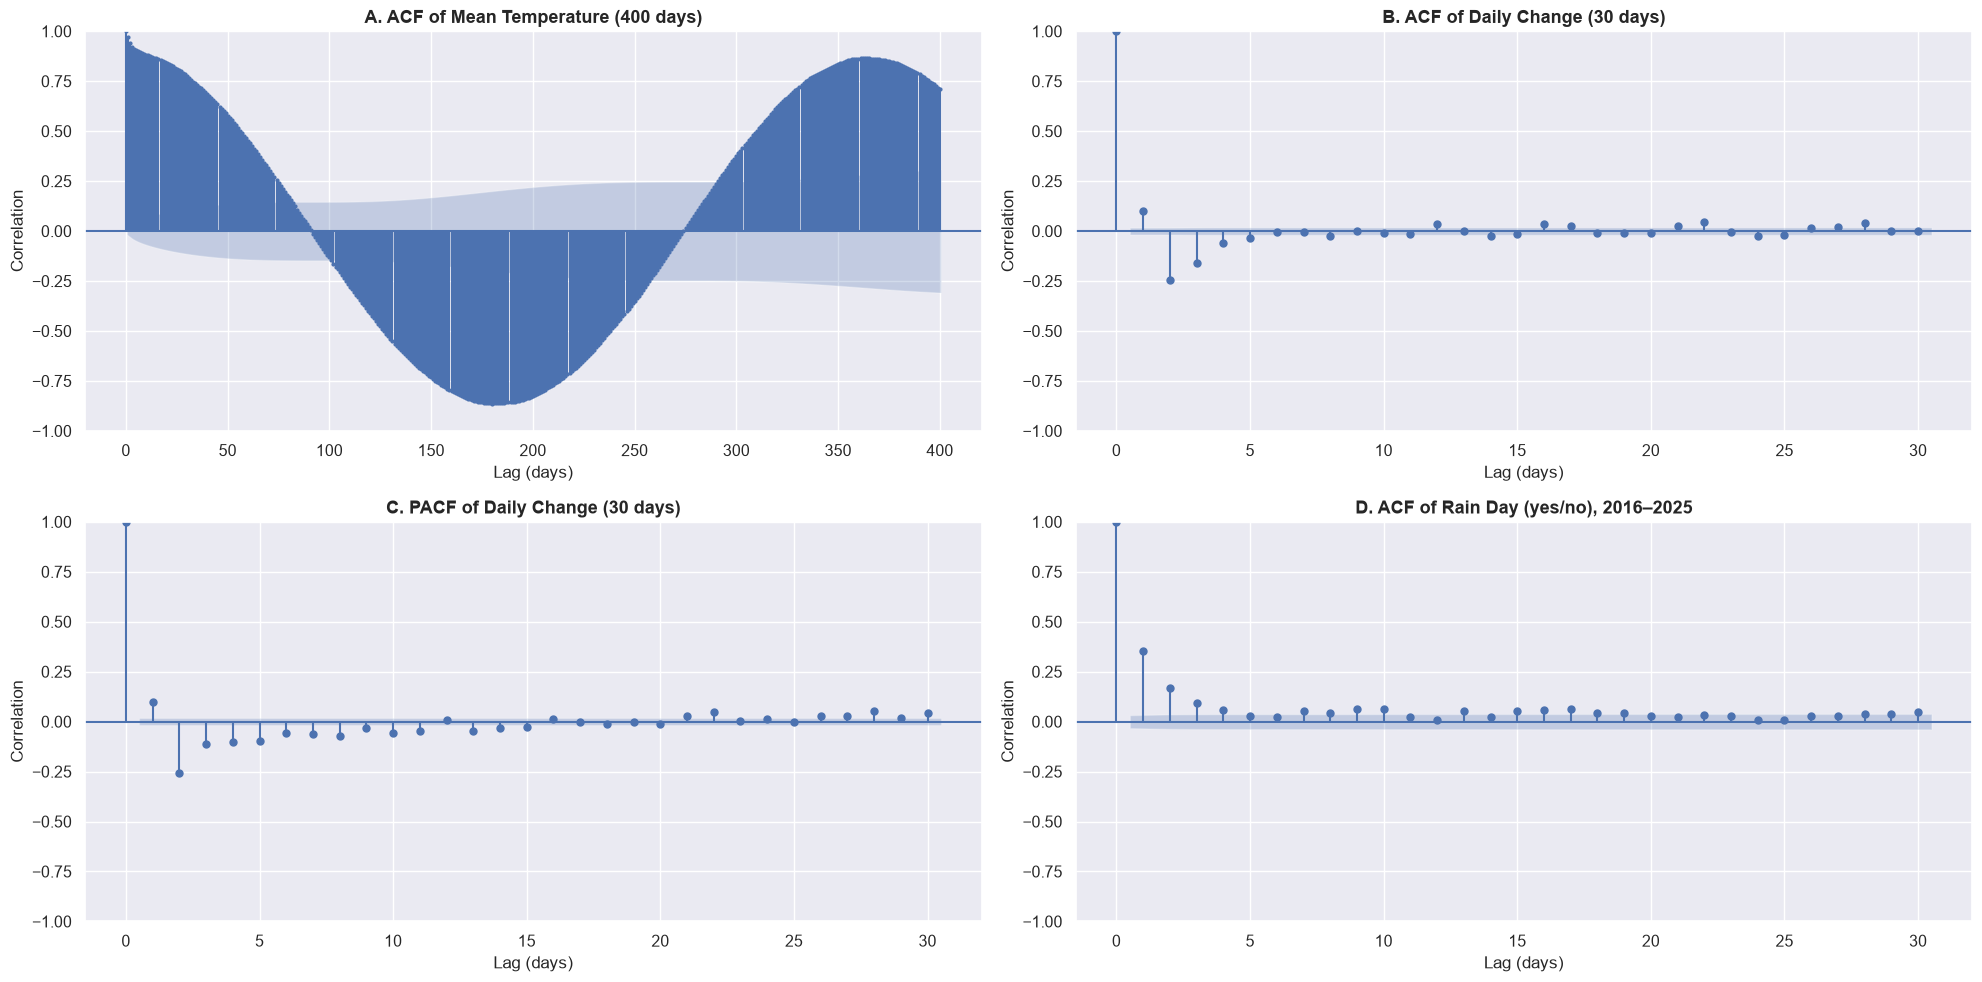

In [351]:
daily_change = weather["temp_mean"].diff().dropna()
recent_rain_day = (weather.loc["2016":, "precipitation"] >= 1).astype(int)

fig, ax = plt.subplots(nrows=2, ncols=2, figsize=(20, 10))
plot_acf(weather["temp_mean"], lags=400, ax=ax[0, 0], markersize=2)
ax[0, 0].set_title("A. ACF of Mean Temperature (400 days)")
plot_acf(daily_change, lags=30, ax=ax[0, 1])
ax[0, 1].set_title("B. ACF of Daily Change (30 days)")
plot_pacf(daily_change, lags=30, ax=ax[1, 0], method="ywm")
ax[1, 0].set_title("C. PACF of Daily Change (30 days)")
plot_acf(recent_rain_day, lags=30, ax=ax[1, 1])
ax[1, 1].set_title("D. ACF of Rain Day (yes/no), 2016–2025")

for a in ax.flatten():
    a.set_xlabel("Lag (days)")
    a.set_ylabel("Correlation")
plt.tight_layout()
plt.show()

**What we see:**
- **A:** Today looks very much like yesterday (0.97) and last week (0.90). The link falls to 0 at about 3 months, turns negative at 6 months (−0.86) and comes back at 1 year (+0.86).
- **B and C:** For the daily change, only the first 5 days matter. The blue band is very narrow (±0.017) because we have 13,000 days, so even tiny links pass it; only lags 1–5 are big enough to matter.
- **D:** Rain days come in groups: after a rain day, the chance of rain tomorrow is 39 %, against 5 % on any day (8 times more).

**Why:** The wave in A is the seasons: 6 months apart means summer against winter. Weather systems last a few days, so the last few days help and older ones do not. A rain storm often lasts more than one day.

**What we do with it:** Temperature: use the last 1–5 days. Rain: "did it rain today?" is the strongest single clue, so the rain persistence baseline will be hard to beat.

#### Which lags make good features?
The feature step plans lags such as t-1, t-7 and t-365. Here each candidate is compared with the target, **tomorrow's mean temperature**, in two ways:
- **With the season:** the plain correlation. Every candidate looks strong here, because all of them follow the same yearly wave.
- **Season removed:** tomorrow's difference from its normal vs the candidate's difference from its normal. This shows what each candidate adds **beyond the calendar**.

Each candidate uses only what is known today. The normal here comes from all years, which is fine for EDA; the models must compute it from the training years only.

In [352]:
temp = weather["temp_mean"]
normal_by_day = temp.groupby(temp.index.dayofyear).transform("mean")
anomaly = temp - normal_by_day

# Target: tomorrow, as it is and as its difference from normal
tomorrow = temp.shift(-1)
tomorrow_anomaly = anomaly.shift(-1)

# Lag k = k days before tomorrow, so "today" is lag 1 and the same date last year is lag 365
candidates = {
    "Today (lag 1)": (temp, anomaly),
    "Yesterday (lag 2)": (temp.shift(1), anomaly.shift(1)),
    "3 days before (lag 3)": (temp.shift(2), anomaly.shift(2)),
    "Same day last week (lag 7)": (temp.shift(6), anomaly.shift(6)),
    "Same day last year (lag 365)": (temp.shift(364), anomaly.shift(364)),
    "Mean of the last 3 days": (temp.rolling(3).mean(), anomaly.rolling(3).mean()),
    "Mean of the last 7 days": (temp.rolling(7).mean(), anomaly.rolling(7).mean()),
    "Mean of the last 30 days": (temp.rolling(30).mean(), anomaly.rolling(30).mean()),
    "Normal for tomorrow's date": (normal_by_day.shift(-1), None),
}

lag_check = pd.DataFrame({
    "With the season": {name: tomorrow.corr(raw) for name, (raw, _) in candidates.items()},
    "Season removed": {name: tomorrow_anomaly.corr(anom) if anom is not None else np.nan
                       for name, (_, anom) in candidates.items()},
})
lag_check.round(2)

,With the season,Season removed
Today (lag 1),0.97,0.77
Yesterday (lag 2),0.94,0.49
3 days before (lag 3),0.92,0.33
Same day last week (lag 7),0.90,0.13
Same day last year (lag 365),0.89,-0.04
Mean of the last 3 days,0.96,0.60
Mean of the last 7 days,0.95,0.45
Mean of the last 30 days,0.91,0.32
Normal for tomorrow's date,0.94,NaN


**What we see:**
- **With the season:** every candidate is above 0.88, so this column cannot tell them apart.
- **Season removed:** today's difference from normal is still strongly linked with tomorrow's (0.77), but the link fades fast: 0.49 for yesterday, 0.13 for a week before, and about 0 for the same day last year.

**Why:** Every candidate follows the same yearly wave, so they all look good until the wave is removed. After that, only recent days carry information. Last year's weather on this date was just last year's luck.

**What we do with it:**
- **Keep:** lags 1–3, the 3- and 7-day means, and the day of year as sine and cosine (this already gives the normal).
- **Drop:** lag 365. It adds nothing the calendar does not, and it would cost us the first year of data.
- **Baseline to beat:** "tomorrow = today".

### 3.3.3 Stationarity (ADF Test)
A series is stationary when its mean and spread do not change over time. Models like ARIMA need this. The Augmented Dickey-Fuller test checks it: p-value below 0.05 means stationary.

The test is run on three versions, because a strong season can still pass the test (the season repeats around a fixed level), while the model still has to learn it.

In [353]:
deseasonalized = weather["temp_mean"] - additive.seasonal

series = {
    "Mean temperature (as it is)": weather["temp_mean"],
    "After removing the season": deseasonalized,
    "Daily change (differenced)": weather["temp_mean"].diff(),
}

rows = []
for name, values in series.items():
    statistic, p_value = adfuller(values.dropna())[:2]
    result = "Stationary" if p_value < 0.05 else "Not stationary"
    rows.append([name, round(statistic, 2), round(p_value, 4), result])

adf_results = pd.DataFrame(rows, columns=["Series", "ADF statistic", "p-value", "Result"])
adf_results

C:\Users\esraa\AppData\Local\Temp\ipykernel_9476\2134689993.py:11: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  statistic, p_value = adfuller(values.dropna())[:2]
C:\Users\esraa\AppData\Local\Temp\ipykernel_9476\2134689993.py:11: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  statistic, p_value = adfuller(values.dropna())[:2]
C:\Users\esraa\AppData\Local\Temp\ipykernel_94

,Series,ADF statistic,p-value,Result
0,Mean temperature (as it is),-9.74,0.0,Stationary
1,After removing the season,-14.67,0.0,Stationary
2,Daily change (differenced),-12.84,0.0,Stationary


**What we see:** The test calls all three versions stationary (p < 0.001), even the raw temperature.

**Why:** Cairo's temperature goes up and down every year, but it always comes back to the same level. It never drifts away the way a stock price can. It is still not fully stationary: the average depends on the date and rises slowly over the years.

**What we do with it:** No need to difference the data (d = 0). The model still has to learn the seasons, so we give it the day of year as sine and cosine. A seasonal ARIMA with a 365-day season is very slow on daily data, so SARIMAX with sine and cosine inputs is the practical choice.

## 3.4 Relationships and Anomalies

### 3.4.1 Correlation
A: the correlation between all variables as they are. B: the same correlation after removing the season (each value minus the normal for its date). Variables that all follow the seasons look strongly related in A even when they are not; B shows the real day-to-day relationships.

Spearman correlation is used instead of Pearson, because rain is very skewed (mostly zeros).

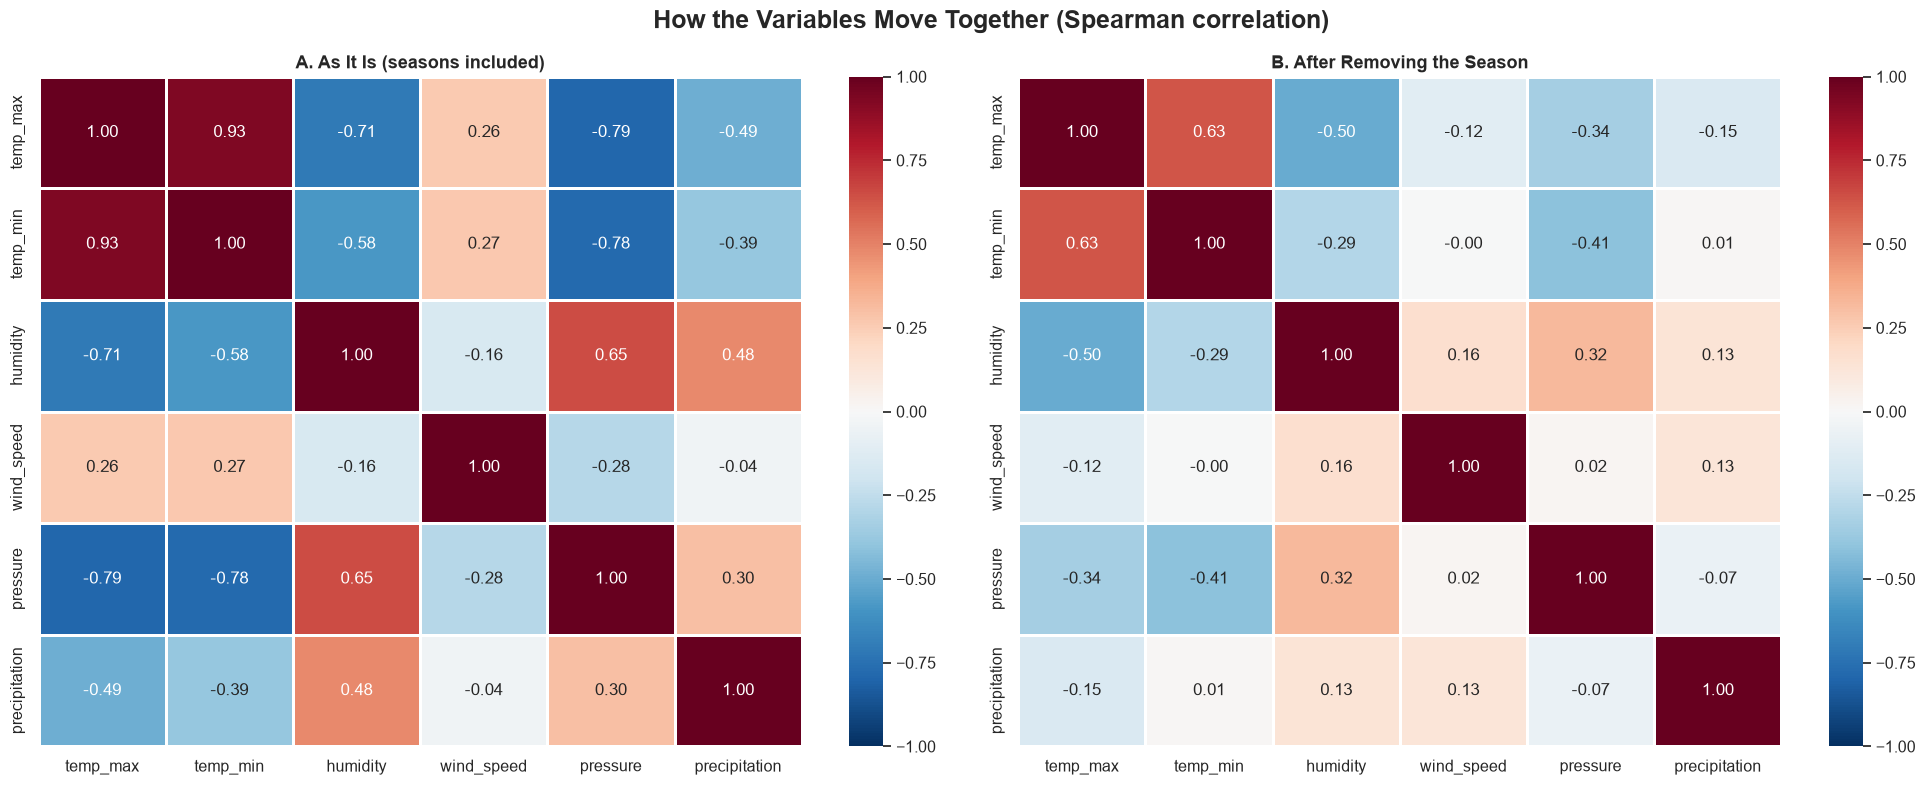

In [354]:
NUMBER_SIGNS = ["temp_max", "temp_min", "humidity", "wind_speed", "pressure", "precipitation"]

# Each value minus the normal for its date (the 36-year mean of that day of the year)
day_of_year = weather.index.dayofyear
anomalies = weather[NUMBER_SIGNS] - weather[NUMBER_SIGNS].groupby(day_of_year).transform("mean")

fig, ax = plt.subplots(ncols=2, figsize=(20, 8))
sns.heatmap(weather[NUMBER_SIGNS].corr(method="spearman"), annot=True, fmt=".2f", cmap="RdBu_r",
            center=0, vmin=-1, vmax=1, linewidths=1, ax=ax[0])
ax[0].set_title("A. As It Is (seasons included)")
sns.heatmap(anomalies.corr(method="spearman"), annot=True, fmt=".2f", cmap="RdBu_r",
            center=0, vmin=-1, vmax=1, linewidths=1, ax=ax[1])
ax[1].set_title("B. After Removing the Season")
plt.suptitle("How the Variables Move Together (Spearman correlation)")
plt.tight_layout()
plt.show()

**What we see:**
- **A. As it is:** Strong links: hot days have lower pressure (−0.79), lower humidity (−0.71) and less rain (−0.49).
- **B. Season removed:** Most links shrink (max temperature vs pressure: −0.34; rain vs humidity: +0.13). Some real day-to-day links stay: a day hotter than normal is also drier than normal (−0.50).

**Why:** In A, many links are just the season: summer is hot, dry and low in pressure all at once, so everything looks related. B removes the season and shows what is really linked from day to day.

**What we do with it:** Humidity and pressure (as differences from normal) are useful extra inputs. Rain has no strong partner, so a rain model must combine several weak clues. Max, mean and min temperature are almost the same (0.93), so linear models need regularization (Ridge) if all three are used.

#### Yesterday's weather vs rain today
Which of yesterday's signs (after removing the season) go with a real rain day (≥ 1 mm) today? Only the rainy months (October–April) of 2016–2025 are used (H3). Red: higher yesterday goes with more rain today. Blue: lower yesterday goes with more rain today.

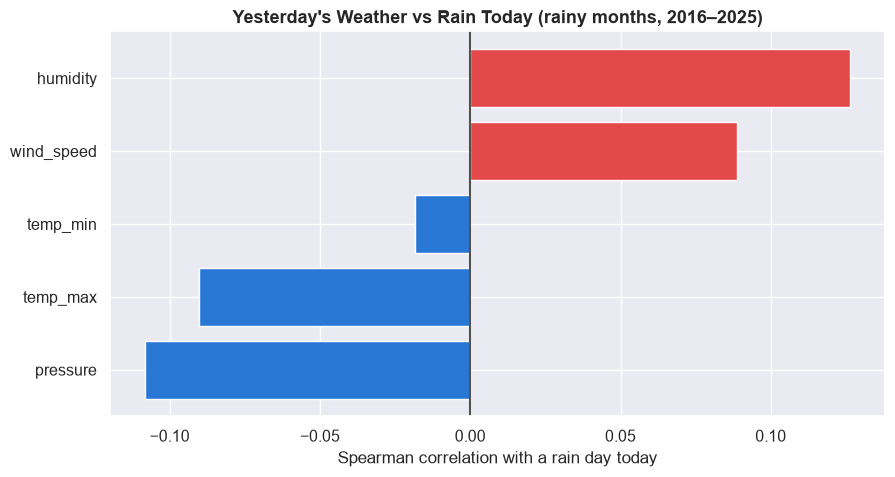

In [355]:
rainy_months = (weather.index.year >= 2016) & weather.index.month.isin([10, 11, 12, 1, 2, 3, 4])
rain_today = (weather["precipitation"] >= 1).astype(int)
yesterday = anomalies.shift(1).drop(columns="precipitation")

corr_yesterday = yesterday[rainy_months].corrwith(rain_today[rainy_months], method="spearman").sort_values()
colors = ["#2a78d6" if value < 0 else "#e34948" for value in corr_yesterday]

plt.figure(figsize=(10, 5))
plt.barh(corr_yesterday.index, corr_yesterday.values, color=colors)
plt.axvline(0, color="#52514e")
plt.title("Yesterday's Weather vs Rain Today (rainy months, 2016–2025)")
plt.xlabel("Spearman correlation with a rain day today")
plt.show()

**What we see:** All links are weak (below 0.15). Rain today is a little more likely after a day that was more humid (+0.13), windier (+0.09), lower in pressure (−0.11) and cooler (−0.09) than normal.

**Why:** These are the signs of a storm arriving: moist air, wind and falling pressure. They are weak because most humid or windy days still end without rain.

**What we do with it:** Use them only together with the strong clues: the month and whether it rained today (0.36 in Step 3.3.2).

### 3.4.2 Outliers on Rolling Windows
A fixed threshold for the whole year misses seasonal extremes: 30 °C is normal in July but very unusual in January. So each day is compared with the 31 days around it: its rolling z-score is (value − rolling mean) / rolling std, and a day is an outlier when it is more than 3 std away. Rain is left out, because it is mostly zeros; its extremes are studied with the rain-day plots below.

In [356]:
OUTLIER_COLUMNS = ["temp_max", "temp_min", "humidity", "wind_speed", "pressure"]
WINDOW = 31

window_mean = weather[OUTLIER_COLUMNS].rolling(WINDOW, center=True).mean()
window_std = weather[OUTLIER_COLUMNS].rolling(WINDOW, center=True).std()
rolling_z = (weather[OUTLIER_COLUMNS] - window_mean) / window_std
outliers = rolling_z.abs() > 3

# Compare with one fixed threshold for the whole series
global_z = (weather[OUTLIER_COLUMNS] - weather[OUTLIER_COLUMNS].mean()) / weather[OUTLIER_COLUMNS].std()
pd.DataFrame({
    "Fixed threshold (whole series)": (global_z.abs() > 3).sum(),
    "Rolling window (31 days)": outliers.sum(),
})

,Fixed threshold (whole series),Rolling window (31 days)
temp_max,0,12
temp_min,0,18
humidity,7,30
wind_speed,70,34
pressure,19,10


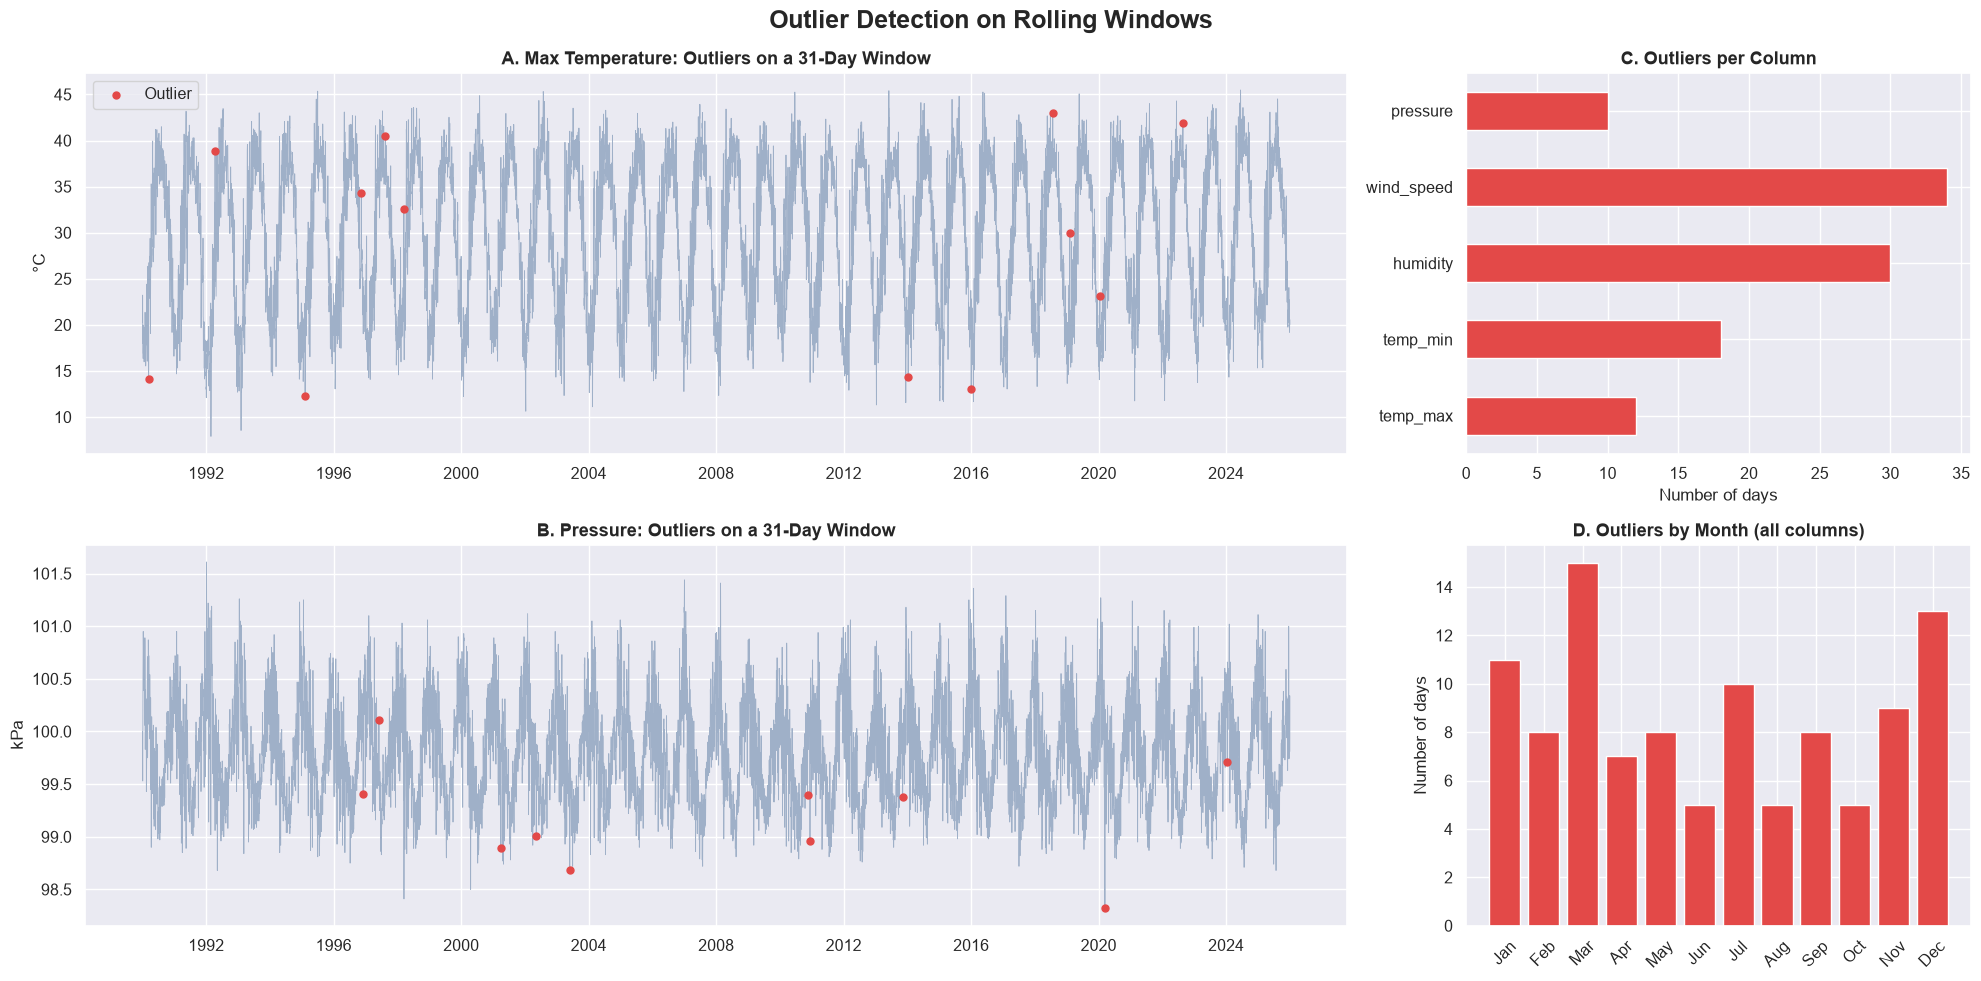

In [357]:
fig, ax = plt.subplots(nrows=2, ncols=2, figsize=(20, 10), gridspec_kw={"width_ratios": [3, 1.2]})

# A. Max temperature with its outliers in red
ax[0, 0].plot(weather.index, weather["temp_max"], color="#9fb0c8", linewidth=0.6)
ax[0, 0].scatter(weather.index[outliers["temp_max"]], weather.loc[outliers["temp_max"], "temp_max"], color="#e34948", s=25, zorder=3, label="Outlier")
ax[0, 0].set_title("A. Max Temperature: Outliers on a 31-Day Window")
ax[0, 0].set_ylabel("°C")
ax[0, 0].legend()

# B. Pressure with its outliers in red
ax[1, 0].plot(weather.index, weather["pressure"], color="#9fb0c8", linewidth=0.6)
ax[1, 0].scatter(weather.index[outliers["pressure"]], weather.loc[outliers["pressure"], "pressure"], color="#e34948", s=25, zorder=3, label="Outlier")
ax[1, 0].set_title("B. Pressure: Outliers on a 31-Day Window")
ax[1, 0].set_ylabel("kPa")

# C. Number of outliers in each column
outliers.sum().plot(kind="barh", color="#e34948", ax=ax[0, 1])
ax[0, 1].set_title("C. Outliers per Column")
ax[0, 1].set_xlabel("Number of days")

# D. In which months the outliers happen
outliers_by_month = outliers.groupby(weather.index.month).sum().sum(axis=1)
ax[1, 1].bar(MONTHS, outliers_by_month, color="#e34948")
ax[1, 1].set_title("D. Outliers by Month (all columns)")
ax[1, 1].set_ylabel("Number of days")
ax[1, 1].tick_params(axis="x", rotation=45)

plt.suptitle("Outlier Detection on Rolling Windows")
plt.tight_layout()
plt.show()

**What we see:**
- One fixed limit for the whole series finds no temperature outliers at all, but 70 windy days. The 31-day window finds 12 max-temperature, 18 min-temperature, 30 humidity, 34 wind and 10 pressure outliers.
- They include cold winter days (12.3 °C on 7 Feb 1995), hot summer days (43.0 °C on 24 Jul 2018), and the lowest pressure of all, the day after the March 2020 storm.
- They happen in every month and are not growing over time (2.6 per year before 2016, 2.1 after).

**Why:** A fixed limit compares January with July, so a very cold January day still looks "normal" next to the whole year. A 31-day window compares each day with its own season.

**What we do with it:** The outliers match real events, so they stay. They will cause the biggest errors, so we report both MAE (the typical error) and RMSE (which punishes big misses).

### 3.4.3 Suspicious Values
Values that are possible but unlikely, and may come from the model rather than real weather: a jump of more than 8 °C in mean temperature from one day to the next, heavy rain on a very dry day, and rain above 50 mm in one day (about twice Cairo's normal rain for a whole year). They are flagged, not removed.

In [358]:
temp_jump = weather["temp_mean"].diff().abs()

suspicious = pd.DataFrame({
    "Temperature jump > 8 °C in one day": temp_jump > 8,
    "Heavy rain (>= 10 mm) with humidity < 30 %": (weather["precipitation"] >= 10) & (weather["humidity"] < 30),
    "Rain above 50 mm in one day": weather["precipitation"] > 50,
})

print(suspicious.sum())
weather.loc[suspicious.any(axis=1), ["temp_mean", "temp_max", "temp_min", "precipitation", "humidity", "wind_speed", "pressure"]].round(2)

Temperature jump > 8 °C in one day            5
Heavy rain (>= 10 mm) with humidity < 30 %    0
Rain above 50 mm in one day                   1
dtype: int64


,temp_mean,temp_max,temp_min,precipitation,humidity,wind_speed,pressure
date,,,,,,,
1991-04-30,23.19,26.76,16.97,0.15,58.73,4.67,99.63
1996-05-02,23.62,31.85,18.21,0.03,42.96,3.99,99.53
2004-03-05,18.40,22.84,14.07,2.07,52.66,4.26,99.53
2013-03-16,17.15,23.45,10.82,0.00,53.51,3.11,99.84
2015-04-09,17.96,22.98,12.05,0.00,49.06,4.93,99.61
2016-11-30,16.49,22.00,11.98,95.48,66.68,4.07,99.75


**What we see:** 5 days jump by more than 8 °C in one day, all in March–May. No heavy rain falls on a very dry day. Only one day passes 50 mm: 30 Nov 2016, with 95.5 mm.

**Why:** Sudden jumps in spring are normal in Cairo (Khamasin winds). But 95.5 mm in one day is about four times Cairo's normal rain for a whole year, so it is very doubtful.

**What we do with it:** Keep the temperature jumps. Flag the 95.5 mm day: a model of rain amounts should cap it or use a log scale. The rain/no-rain model is not affected.

### 3.4.4 Extreme Events
The biggest rain days and the strongest storms over 36 years, what happens before unusual days (H5), and Khamasin-like days (H6).

#### Biggest rain day in each year
The day with the most rain in every year. The 3 biggest are labeled with their date.

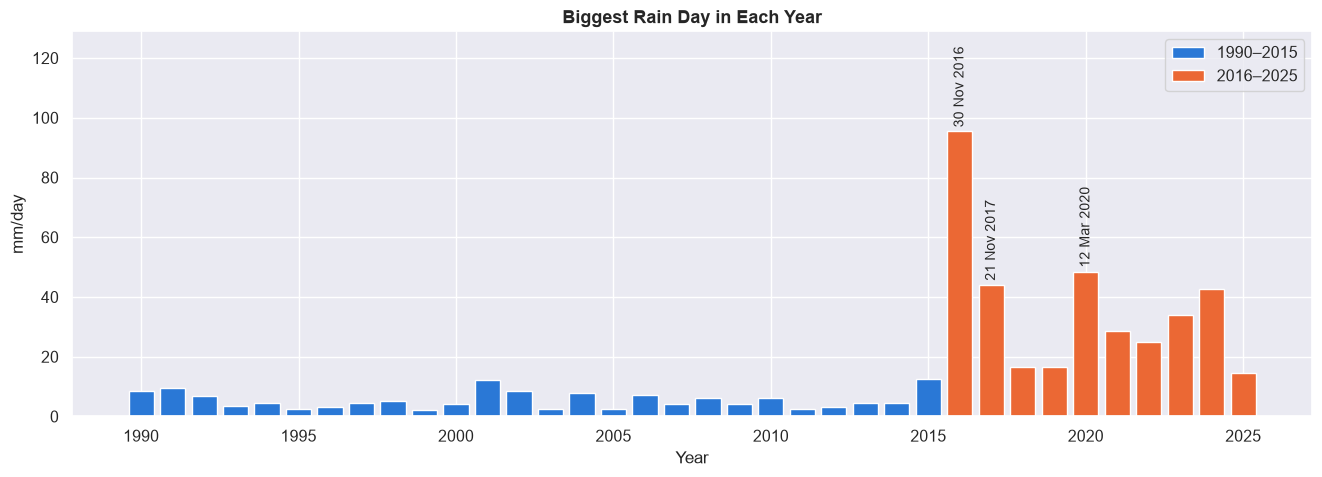

In [359]:
year = weather.index.year

biggest_rain = pd.DataFrame({
    "max_rain_mm": weather["precipitation"].groupby(year).max(),
    "date": weather["precipitation"].groupby(year).idxmax(),
})
before = biggest_rain.loc[:2015]
after = biggest_rain.loc[2016:]

plt.figure(figsize=(16, 5))
plt.bar(before.index, before["max_rain_mm"], color=BEFORE_COLOR, label="1990–2015")
plt.bar(after.index, after["max_rain_mm"], color=AFTER_COLOR, label="2016–2025")

# Label the 3 biggest with their date
for y in biggest_rain["max_rain_mm"].nlargest(3).index:
    label = " " + biggest_rain.loc[y, "date"].strftime("%d %b %Y")
    plt.text(y, biggest_rain.loc[y, "max_rain_mm"], label, ha="center", va="bottom", rotation=90, fontsize=10)

plt.ylim(0, biggest_rain["max_rain_mm"].max() * 1.35)
plt.title("Biggest Rain Day in Each Year")
plt.xlabel("Year")
plt.ylabel("mm/day")
plt.legend()
plt.show()

**What we see:** Before 2016, the biggest rain day of a year averages 5.5 mm; from 2016 it averages 36.6 mm. The top three: 95.5 mm (30 Nov 2016), 48.5 mm (12 Mar 2020) and 44.1 mm (21 Nov 2017).

**Why:** This is the same 2016 jump found in H3.

**What we do with it:** Rain amounts before and after 2016 are not mixed in one model.

#### Top 10 rain days in 36 years

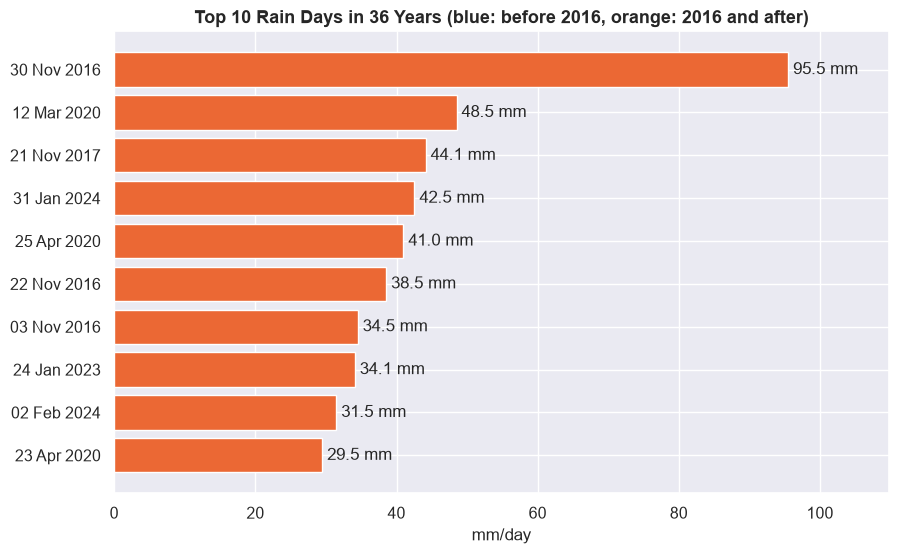

In [360]:
top_rain = weather["precipitation"].nlargest(10).sort_values()
colors = [BEFORE_COLOR if day.year < 2016 else AFTER_COLOR for day in top_rain.index]

plt.figure(figsize=(10, 6))
plt.barh(top_rain.index.strftime("%d %b %Y"), top_rain.values, color=colors)
for i, value in enumerate(top_rain.values):
    plt.text(value, i, " " + str(round(value, 1)) + " mm", va="center")
plt.xlim(0, top_rain.max() * 1.15)
plt.title("Top 10 Rain Days in 36 Years (blue: before 2016, orange: 2016 and after)")
plt.xlabel("mm/day")
plt.show()

**What we see:** All 10 biggest rain days are from 2016 or later. Before 2016, no day reaches 13 mm.

**Why:** If heavy rain were a normal part of Cairo's climate, some of the top 10 would come from the 26 years before 2016.

**What we do with it:** More evidence for H3: rain amounts are only used from 2016.

#### Storm score
Rain amounts are not consistent across the years, so storms are compared with signs that stay consistent for all 36 years: a drop in pressure from yesterday, strong wind, a drop in max temperature from yesterday, and high humidity. Each sign gives every day a rank from 0 (weakest) to 1 (strongest), and the storm score is the average of the four ranks.

In [361]:
signs = pd.DataFrame({
    "pressure_drop": -weather["pressure"].diff(),
    "wind_speed": weather["wind_speed"],
    "temp_drop": -weather["temp_max"].diff(),
    "humidity": weather["humidity"],
})

storm_score = signs.rank(pct=True).mean(axis=1)

#### Top 10 storms in 36 years
The 10 days with the highest storm score. The rain on each day is written next to its bar, to compare the strongest storms with the biggest rain days.

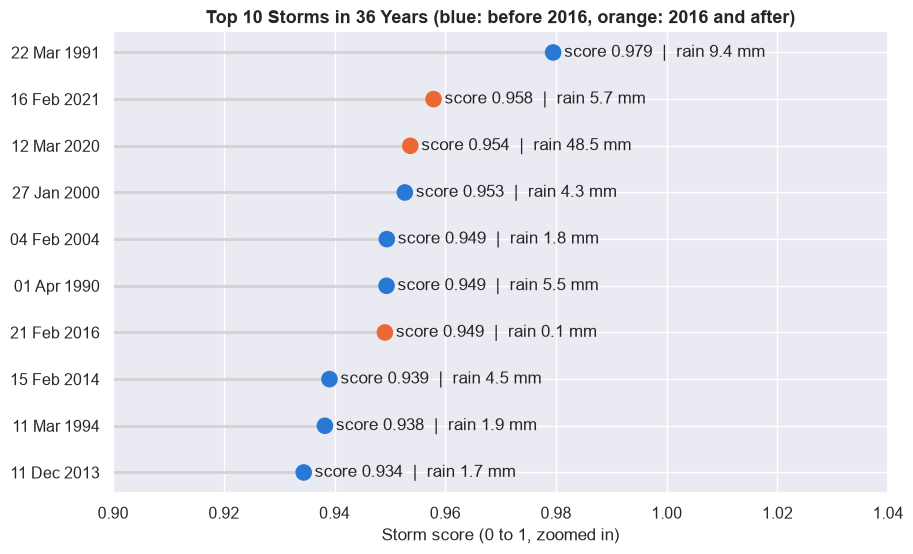

In [362]:
# the 10 strongest storms, as dots so small differences are visible
top_storms = storm_score.nlargest(10).sort_values()
colors = [BEFORE_COLOR if day.year < 2016 else AFTER_COLOR for day in top_storms.index]
labels = top_storms.index.strftime("%d %b %Y")

plt.figure(figsize=(10, 6))
plt.hlines(labels, 0.9, top_storms.values, color="lightgray", linewidth=2)
plt.scatter(top_storms.values, labels, color=colors, s=120, zorder=3)
for i, day in enumerate(top_storms.index):
    plt.text(top_storms[day] + 0.002, i,
             f"score {top_storms[day]:.3f}  |  rain {weather.loc[day, 'precipitation']:.1f} mm",
             va="center")
plt.xlim(0.9, 1.04)
plt.title("Top 10 Storms in 36 Years (blue: before 2016, orange: 2016 and after)")
plt.xlabel("Storm score (0 to 1, zoomed in)")
plt.show()

**What we see:** The 10 strongest storms are spread over 36 years, and 7 of them are before 2016. The strongest (22 Mar 1991) brought only 9.4 mm. Only the March 2020 storm combines a high score with a lot of rain (48.5 mm); several others have less than 2 mm.

**Why:** The storm score uses pressure, wind, temperature drop and humidity, which are consistent over all 36 years. Strong storms happened before 2016 too, but their rain was small in the data.

**What we do with it:** Stronger storms do not explain the rain jump (H3). These four signs describe storms in every year, so they are good inputs for the rain model.

#### Storms vs rain over 36 years
The strongest storm, the strongest wind, the lowest pressure and the biggest rain day in each year. Dashed lines show the average of each period. If storms stay the same after 2016 while rain jumps, the change is in the rain data, not in the storms.

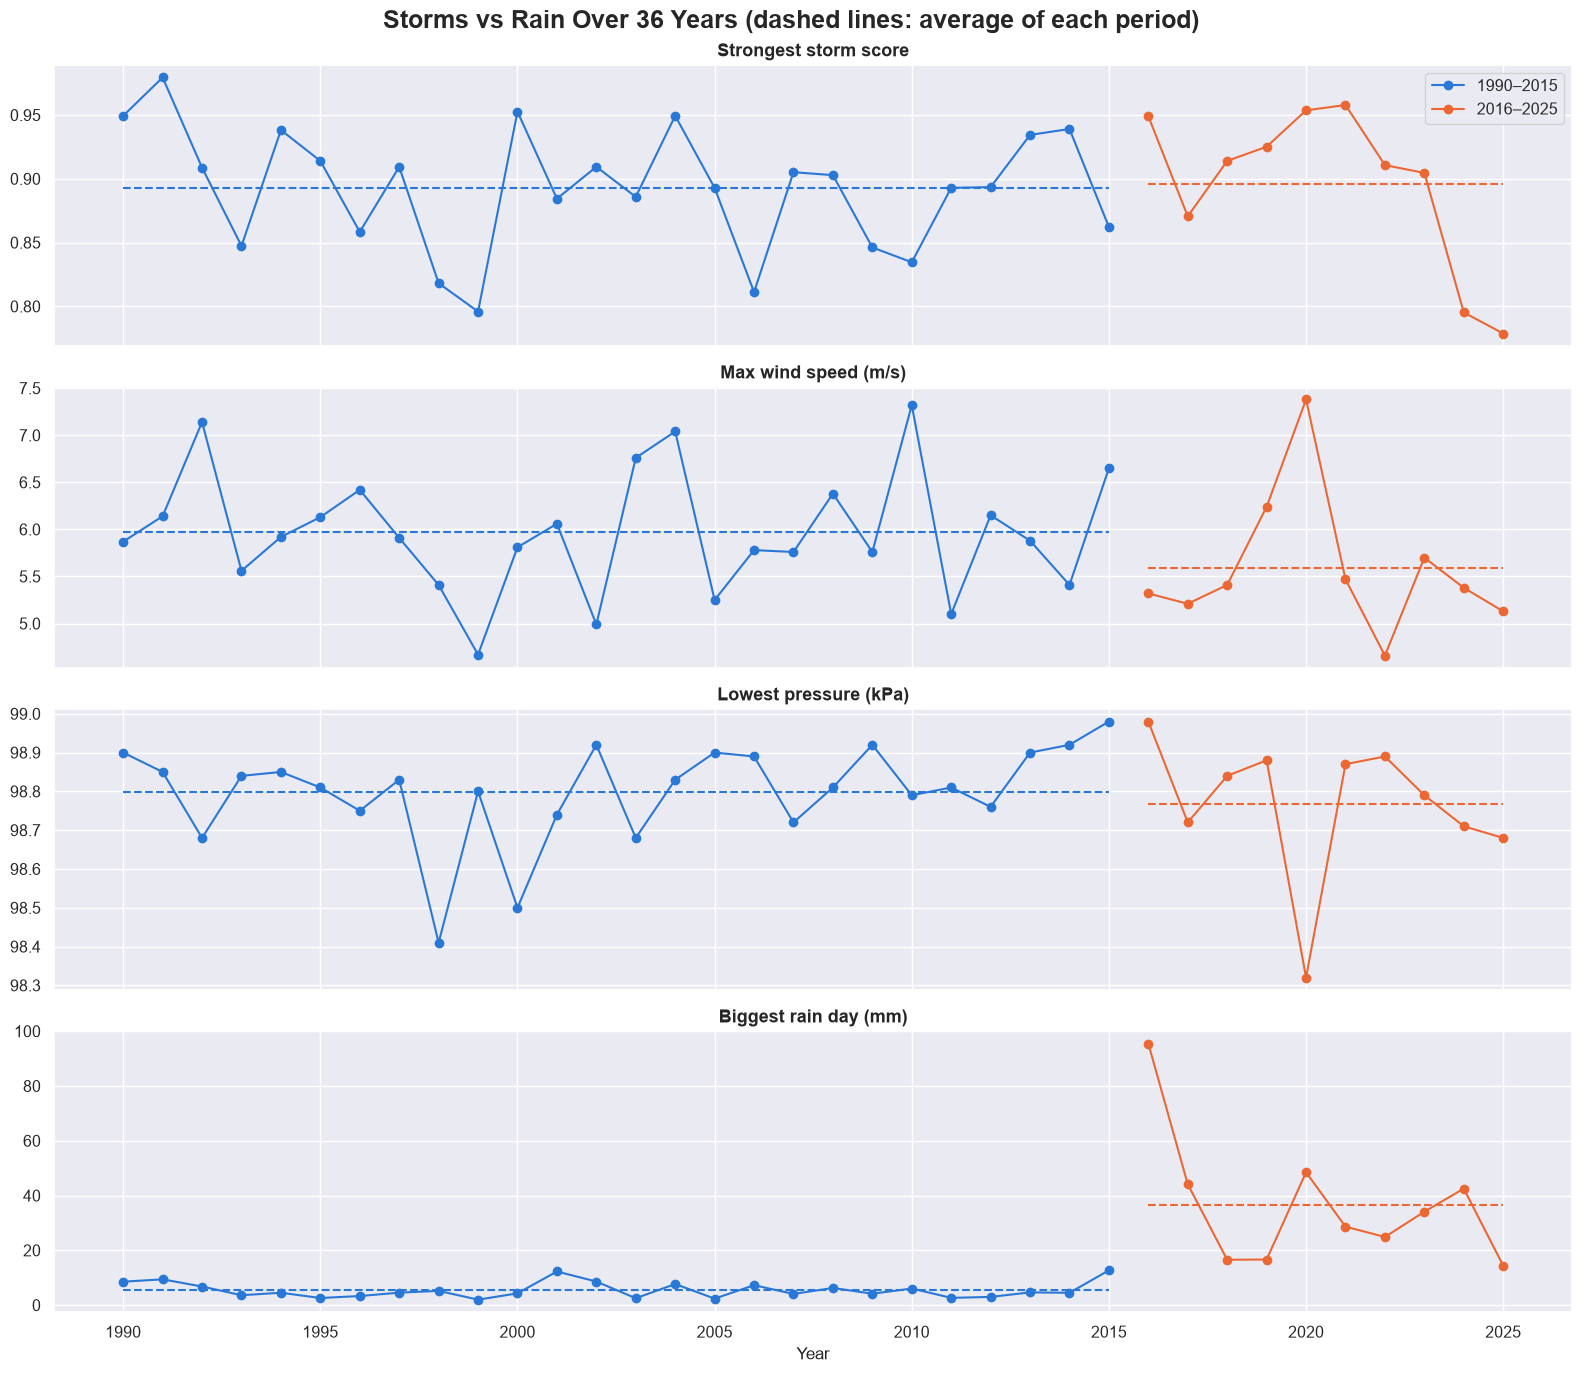

In [363]:
yearly_extremes = pd.DataFrame({
    "Strongest storm score": storm_score.groupby(year).max(),
    "Max wind speed (m/s)": weather["wind_speed"].groupby(year).max(),
    "Lowest pressure (kPa)": weather["pressure"].groupby(year).min(),
    "Biggest rain day (mm)": weather["precipitation"].groupby(year).max(),
})

fig, ax = plt.subplots(nrows=4, figsize=(16, 14), sharex=True)
for i, column in enumerate(yearly_extremes.columns):
    before = yearly_extremes.loc[:2015, column]
    after = yearly_extremes.loc[2016:, column]
    ax[i].plot(before.index, before, marker="o", color=BEFORE_COLOR, label="1990–2015")
    ax[i].plot(after.index, after, marker="o", color=AFTER_COLOR, label="2016–2025")
    ax[i].hlines(before.mean(), 1990, 2015, color=BEFORE_COLOR, linestyle="--")
    ax[i].hlines(after.mean(), 2016, 2025, color=AFTER_COLOR, linestyle="--")
    ax[i].set_title(column)
ax[0].legend()
ax[-1].set_xlabel("Year")
plt.suptitle("Storms vs Rain Over 36 Years (dashed lines: average of each period)")
plt.tight_layout()
plt.show()

**What we see:** The storm signs do not grow after 2016: strongest wind 5.97 → 5.59 m/s, lowest pressure 98.80 → 98.77 kPa. But the biggest rain day jumps from 5.5 to 36.6 mm.

**Why:** If storms had really become stronger, wind and pressure would show it too. Only the rain changed.

**What we do with it:** Strong extra evidence for H3: the change is in the rain data, not in the weather.

#### What a storm looks like: 7 days before and after
The strongest storm before 2016 next to the March 2020 storm. Each row is one variable on the same scale, and day 0 is the storm day.

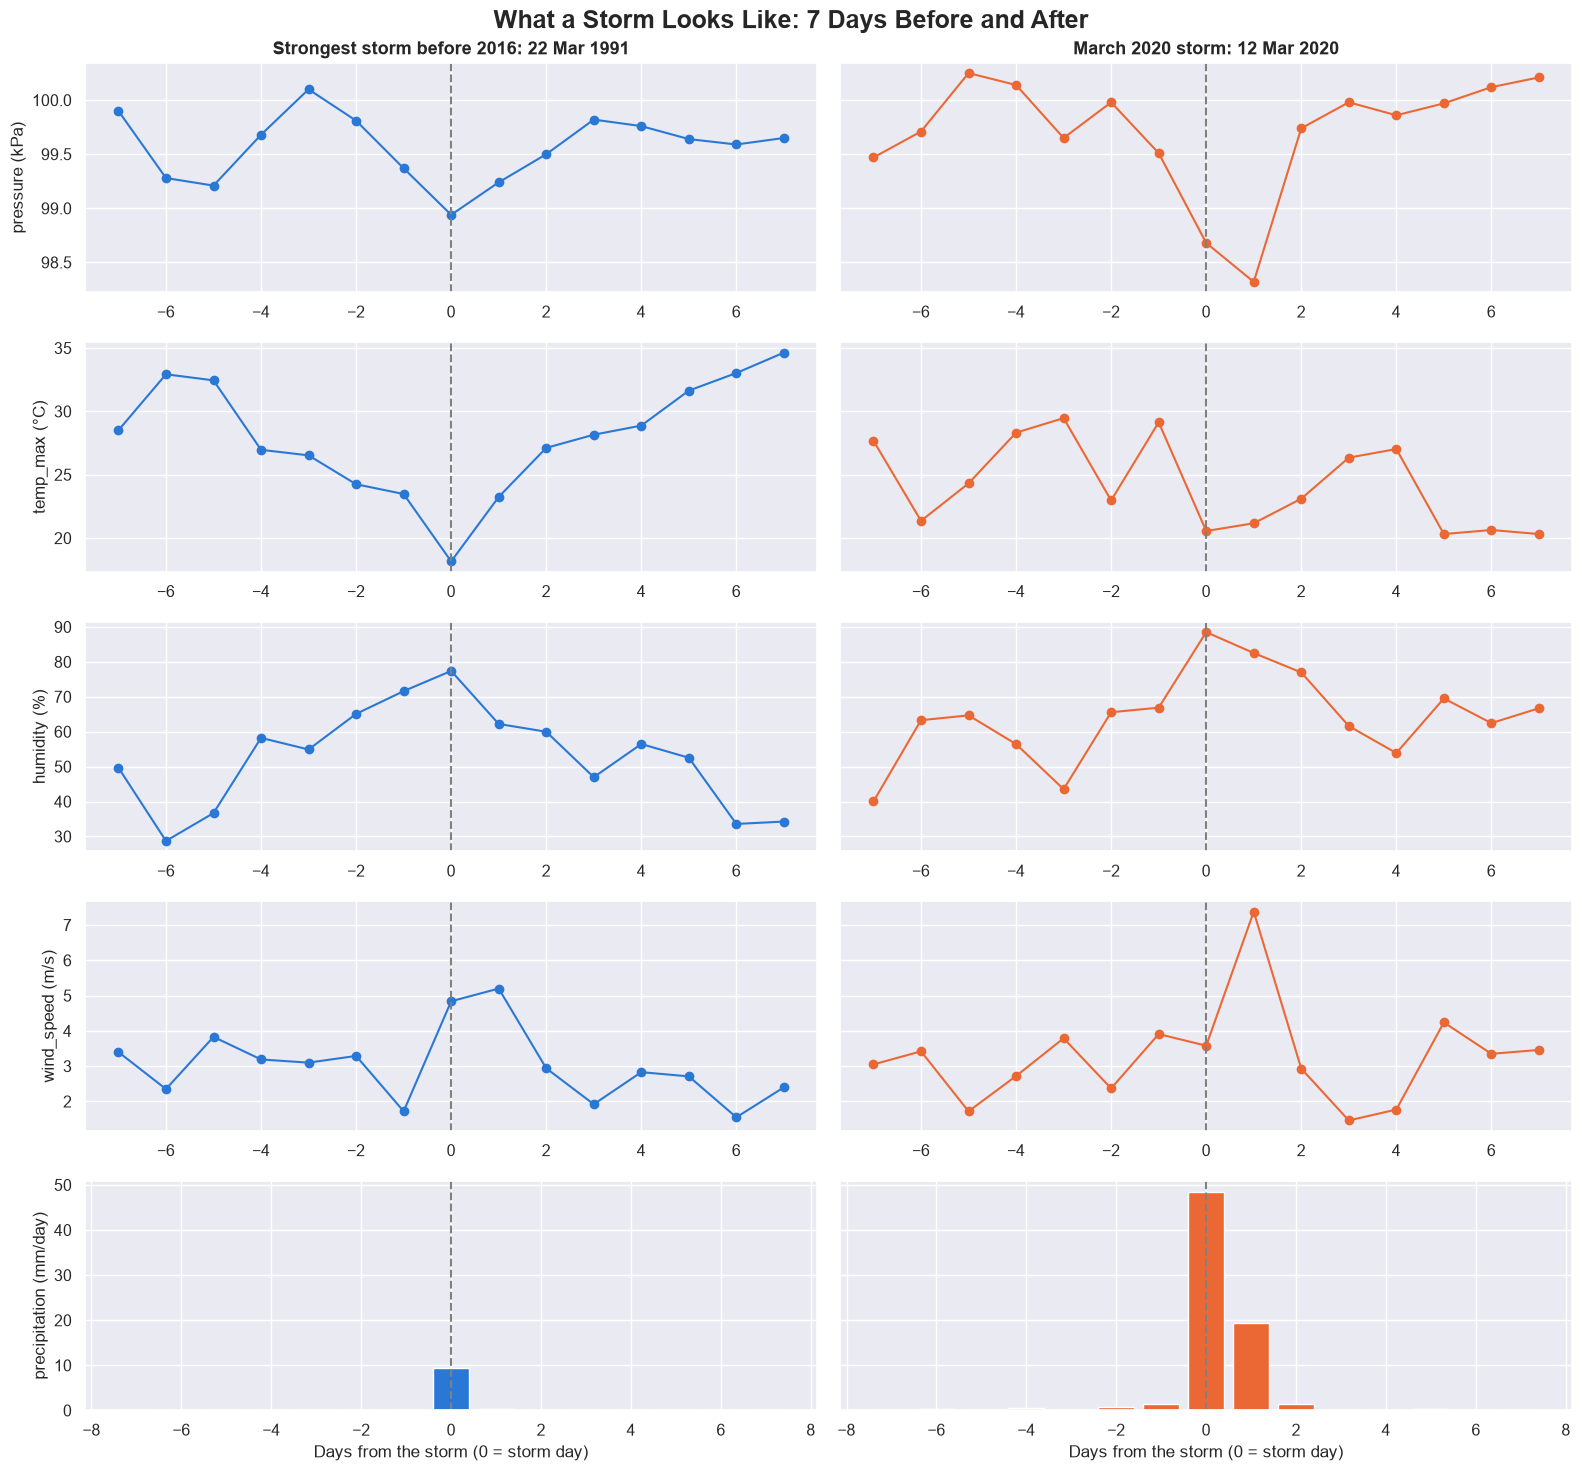

In [364]:
STORMS = {
    "Strongest storm before 2016": storm_score.loc[:"2015"].idxmax(),
    "March 2020 storm": pd.Timestamp("2020-03-12"),
}
COLUMNS = ["pressure", "temp_max", "humidity", "wind_speed", "precipitation"]

fig, ax = plt.subplots(nrows=5, ncols=2, figsize=(16, 15), sharey="row")
for j, (name, day) in enumerate(STORMS.items()):
    window = weather.loc[day - pd.Timedelta(days=7): day + pd.Timedelta(days=7)]
    days_from_storm = (window.index - day).days
    color = BEFORE_COLOR if day.year < 2016 else AFTER_COLOR

    for i, column in enumerate(COLUMNS):
        if column == "precipitation":
            ax[i, j].bar(days_from_storm, window[column], color=color)
        else:
            ax[i, j].plot(days_from_storm, window[column], marker="o", color=color)
        ax[i, j].axvline(0, color="gray", linestyle="--")
        ax[i, 0].set_ylabel(column + " (" + UNITS[column] + ")")

    ax[0, j].set_title(name + ": " + day.strftime("%d %b %Y"))
    ax[-1, j].set_xlabel("Days from the storm (0 = storm day)")

plt.suptitle("What a Storm Looks Like: 7 Days Before and After")
plt.tight_layout()
plt.show()

**What we see:** Both storms follow the same steps: pressure falls for 1–3 days, humidity rises, max temperature drops on the day, and the wind picks up. In 1991 this brings 9.4 mm; in 2020 the same pattern, a bit stronger, brings 48.5 mm and then 19.4 mm.

**Why:** This is how a storm system passes: falling pressure pulls in moist air, then cooler air arrives behind it. A similar storm giving 5 times more rain fits the data change of H3.

**What we do with it:** The change in pressure and humidity over the last 1–3 days is a useful input for the rain model.

#### H5. Do storms have a signature in the days before them?
For every day, we measure how far each sign is from the normal for that date, in standard deviations (0 = normal for that date, +2 = much higher, -2 = much lower). This removes the seasons and puts all signs on the same scale.

Then we take the first day of every unusual event, line them up as day 0, and average the 7 days before and the 3 days after. Storms are compared with heat waves and cold snaps, to see if each kind of event has its own signature.

In [365]:
SIGNS = ["pressure", "humidity", "temp_max", "temp_min", "wind_speed", "precipitation"]

# How unusual each day is for its date: 0 = normal, +2 = much higher than normal, -2 = much lower
day_of_year = weather.index.dayofyear
normal = weather[SIGNS].groupby(day_of_year).transform("mean")
spread = weather[SIGNS].groupby(day_of_year).transform("std")
z = (weather[SIGNS] - normal) / spread

In [366]:
def first_days(is_event):
    # Keep only the first day of each event, so the days before it are not part of the same event
    return is_event[is_event & ~is_event.shift(1, fill_value=False)].index

EVENTS = {
    "Storms (rain ≥ 10 mm, 2016–2025)": first_days((weather["precipitation"] >= 10) & (weather.index.year >= 2016)),
    "Heat waves (max temp ≥ 2 std above normal)": first_days(z["temp_max"] >= 2),
    "Cold snaps (min temp ≥ 2 std below normal)": first_days(z["temp_min"] <= -2),
}

for name, days in EVENTS.items():
    print(name, "->", len(days), "events")

Storms (rain ≥ 10 mm, 2016–2025) -> 25 events
Heat waves (max temp ≥ 2 std above normal) -> 262 events
Cold snaps (min temp ≥ 2 std below normal) -> 114 events


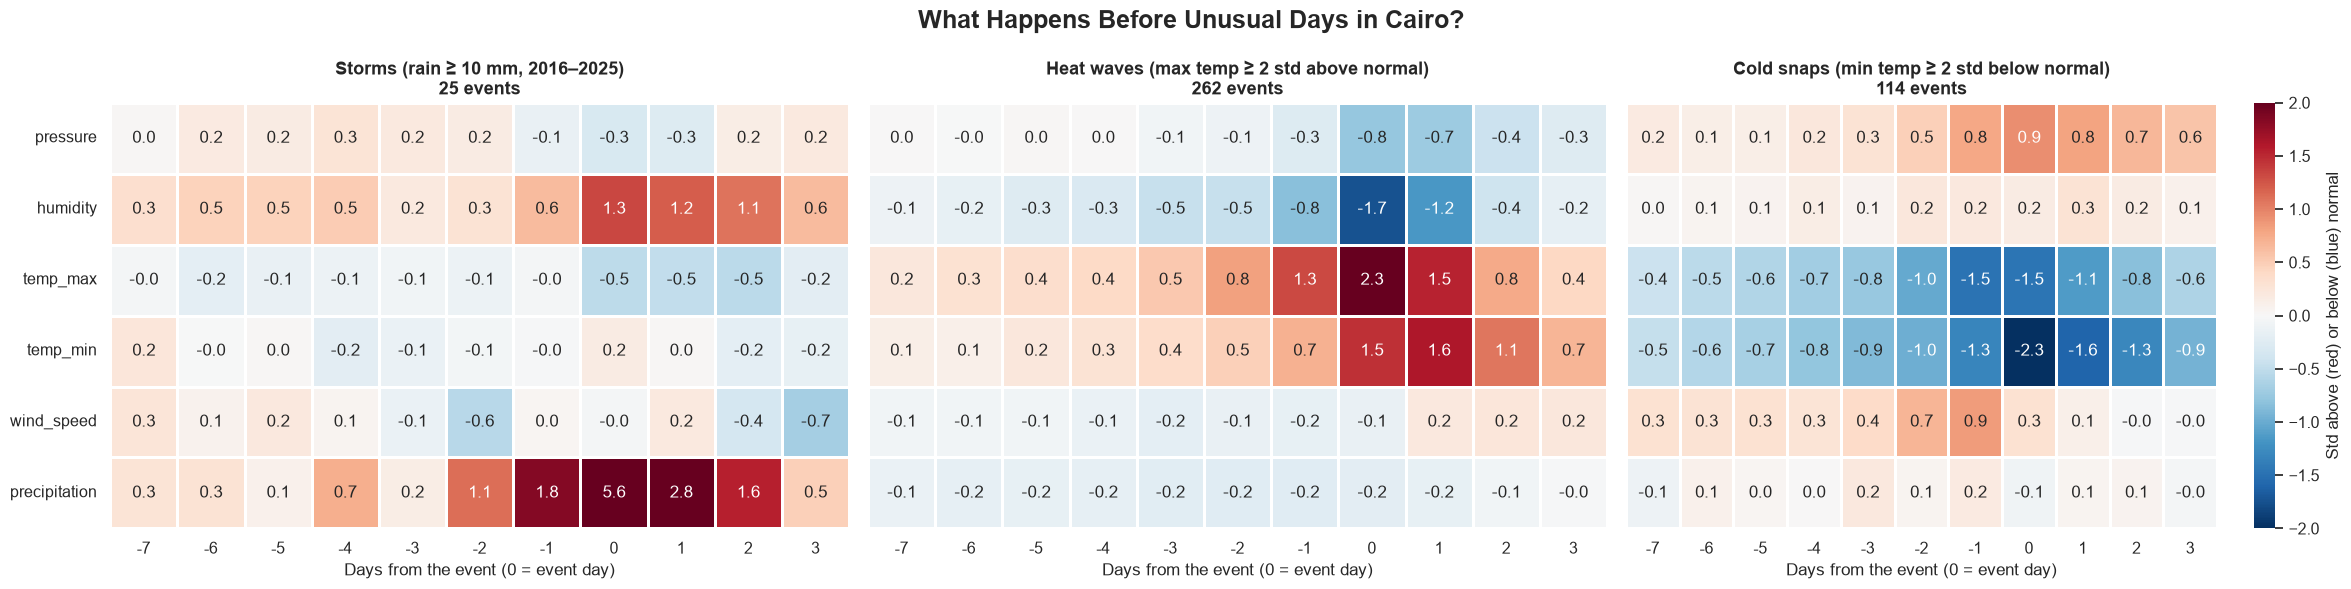

In [367]:
DAYS = range(-7, 4)

def signature(event_days):
    # Average of each sign, from 7 days before the event to 3 days after
    rows = []
    for d in DAYS:
        rows.append(z.shift(-d).loc[event_days].mean())
    return pd.DataFrame(rows, index=DAYS)

fig, ax = plt.subplots(ncols=3, figsize=(24, 6), sharey=True)
for i, (name, days) in enumerate(EVENTS.items()):
    sns.heatmap(signature(days).T, cmap="RdBu_r", center=0, vmin=-2, vmax=2, annot=True, fmt=".1f",
                linewidths=1, cbar=(i == 2), cbar_kws={"label": "Std above (red) or below (blue) normal"}, ax=ax[i])
    ax[i].set_title(name + "\n" + str(len(days)) + " events")
    ax[i].set_xlabel("Days from the event (0 = event day)")
ax[0].set_ylabel("")
plt.suptitle("What Happens Before Unusual Days in Cairo?")
plt.tight_layout()
plt.show()

**What we see:** (0 = normal for that date, +1 = clearly higher, +2 = much higher)
- **Storms (25):** Most signs move only on the storm day itself: humidity goes up (+1.3) and max temperature down (−0.5). Before it, humidity is only a little above normal, and some light rain often falls in the 2 days before.
- **Heat waves (262):** They build up over about 5 days: heat rises, humidity falls, and pressure drops just before.
- **Cold snaps (114):** Temperatures fall for a whole week; pressure rises and the wind gets stronger 1–2 days before.

**Why:** Heat waves and cold snaps come from large, slow air masses, so they show up days ahead. Storms in Cairo are short and fast.

##### The average storm, sign by sign
The line is the average storm; the shaded band holds the middle 50% of storms. A narrow band means most storms follow the same pattern.

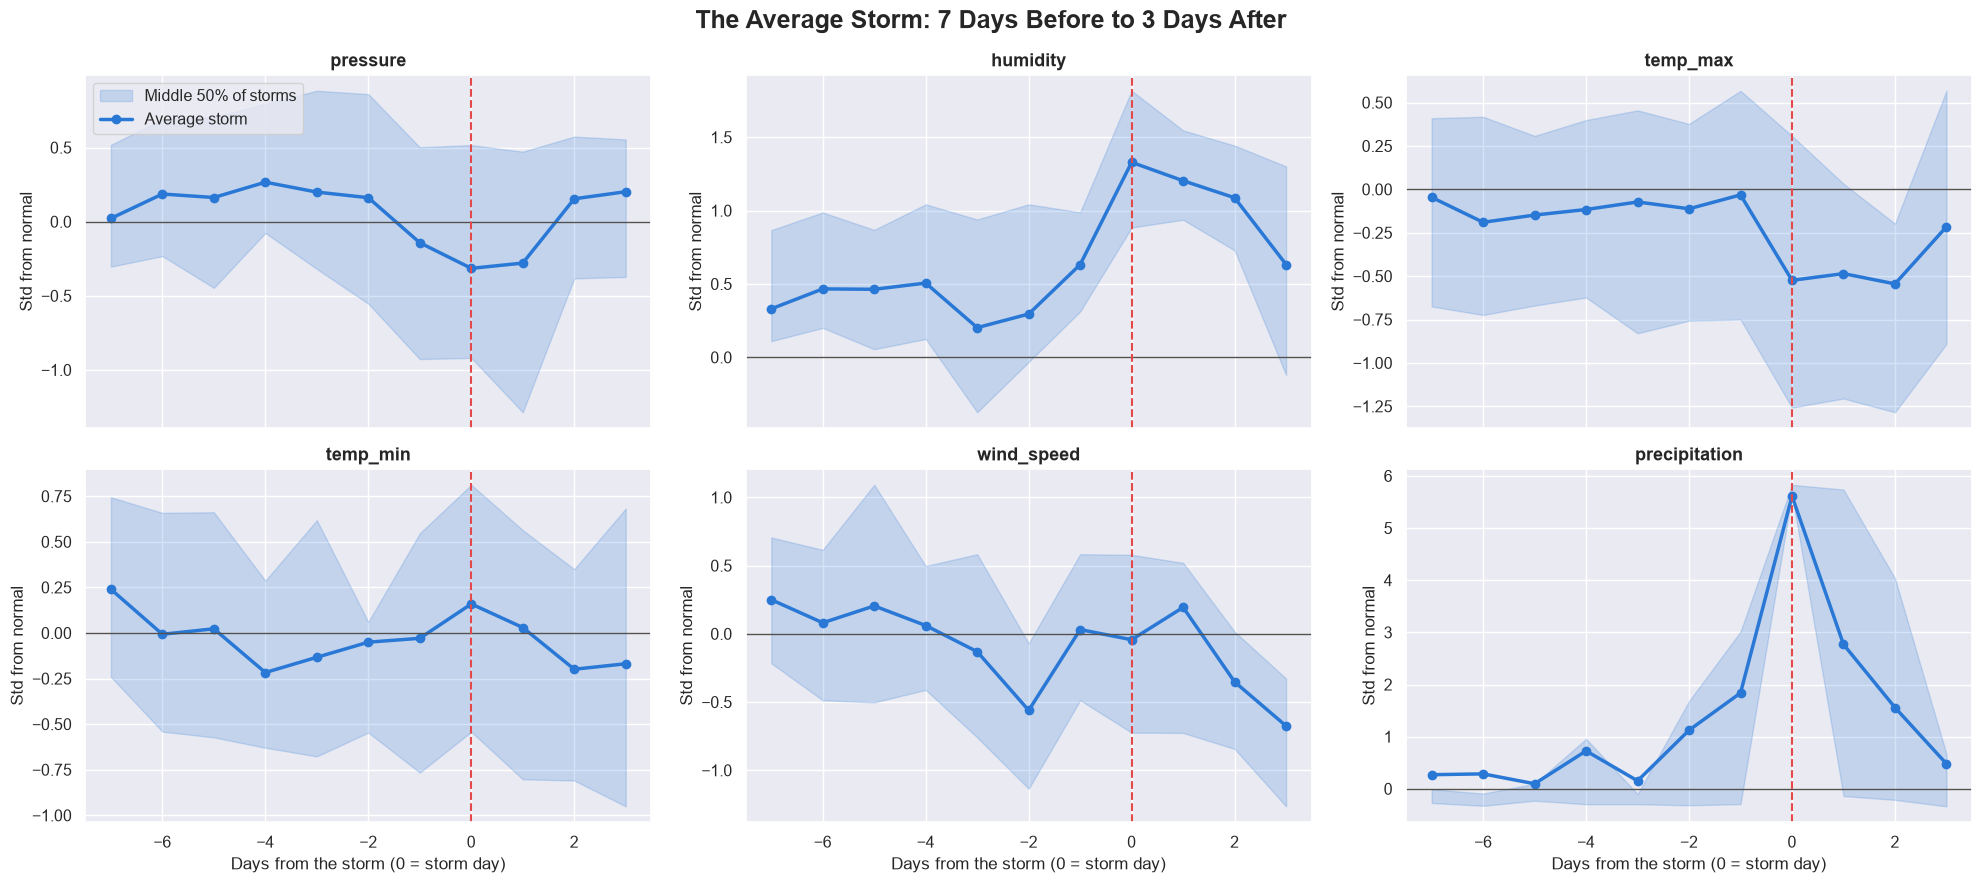

In [368]:
storm_days = EVENTS["Storms (rain ≥ 10 mm, 2016–2025)"]

fig, ax = plt.subplots(nrows=2, ncols=3, figsize=(20, 9), sharex=True)
ax = ax.flatten()
for i, sign in enumerate(SIGNS):
    # One row per storm, one column per day from the storm
    values = pd.DataFrame({d: z[sign].shift(-d).loc[storm_days].values for d in DAYS})
    ax[i].fill_between(list(DAYS), values.quantile(0.25), values.quantile(0.75), color="#2a78d6", alpha=0.2, label="Middle 50% of storms")
    ax[i].plot(list(DAYS), values.mean(), marker="o", color="#2a78d6", linewidth=2.5, label="Average storm")
    ax[i].axhline(0, color="#52514e", linewidth=1)
    ax[i].axvline(0, color="#e34948", linestyle="--")
    ax[i].set_title(sign)
    ax[i].set_ylabel("Std from normal")
ax[0].legend(loc="upper left")
for a in ax[3:]:
    a.set_xlabel("Days from the storm (0 = storm day)")
plt.suptitle("The Average Storm: 7 Days Before to 3 Days After")
plt.tight_layout()
plt.show()

**What we see:** On the day before a storm, the middle half of storms spans both sides of normal for pressure, temperature and wind. Only humidity is above normal for most storms (+0.3 to +1.0), and mostly on the day itself.

**Why:** Storms reach Cairo in different ways, so their average hides very different stories.

**What we do with it:** Humidity is the only sign most storms share, and it arrives late. Do not expect a clear warning a day ahead.

##### Early-warning signals
The correlation between each sign, 1 to 7 days before, and a storm starting. Only the rainy months (October–April) of 2016–2025 are used. Storms are rare, so even useful signals give small numbers: compare the cells with each other, not with 1.

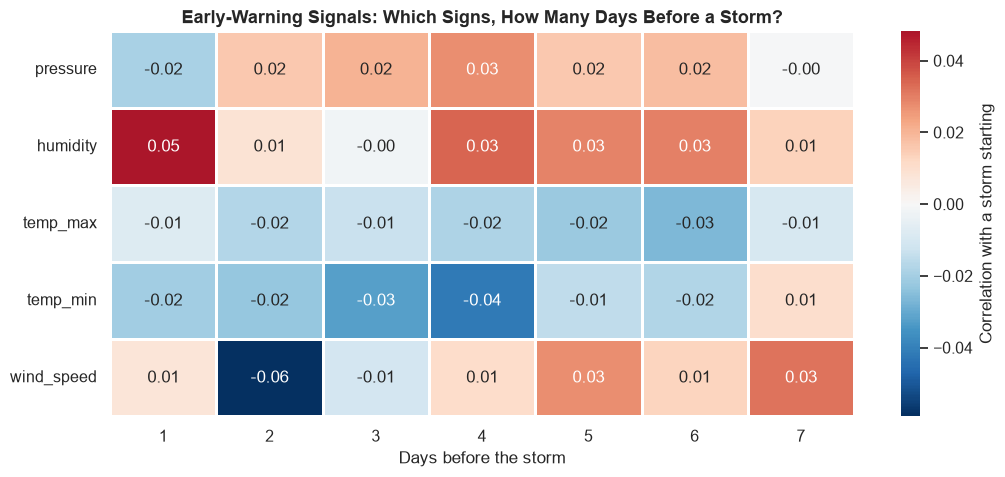

In [369]:
rainy_months = (weather.index.year >= 2016) & weather.index.month.isin([10, 11, 12, 1, 2, 3, 4])

storm_start = pd.Series(0, index=weather.index)
storm_start.loc[storm_days] = 1

lead_corr = pd.DataFrame({
    k: z.shift(k)[rainy_months].corrwith(storm_start[rainy_months]) for k in range(1, 8)
}).drop("precipitation")

plt.figure(figsize=(12, 5))
sns.heatmap(lead_corr, cmap="RdBu_r", center=0, annot=True, fmt=".2f", linewidths=1,
            cbar_kws={"label": "Correlation with a storm starting"})
plt.title("Early-Warning Signals: Which Signs, How Many Days Before a Storm?")
plt.xlabel("Days before the storm")
plt.ylabel("")
plt.show()

**What we see:** All links between the signs and a storm starting are tiny (between −0.06 and +0.05).

**Why:** If a sign gave a real warning, it would show here as a clearly bigger number.

**Answer to H5:** Partly. Heat waves and cold snaps give clear signs days ahead. Storms do not: they mostly show on the day itself.

**What we do with it:**
- **Temperature:** the change in pressure, humidity and wind over the last 1–3 days helps warn of heat waves and cold snaps.
- **Rain:** expect the model to miss many storms. Rain today, humidity and the month are the best clues.

#### H6. Can Khamasin-like days be detected, and when do they happen?
Khamasin winds blow from the desert in the south: they bring sudden heat, very dry air and dust. Here a **Khamasin-like day** is a day with a south wind (135°–225°), max temperature at least 1.5 std above normal for its date, and humidity at least 1.5 std below normal. Only 1990–2012 is used, because wind direction is missing after 2012. This is a data-based definition, not an official one.

In [370]:
# 1990-2012 only: the years with a valid wind direction
valid_years = weather.loc[:"2012"]
valid_z = z.loc[:"2012"]

south_wind = valid_years["wind_dir"].between(135, 225)
khamasin_day = south_wind & (valid_z["temp_max"] >= 1.5) & (valid_z["humidity"] <= -1.5)
print("Khamasin-like days (1990-2012):", khamasin_day.sum())

Khamasin-like days (1990-2012): 125


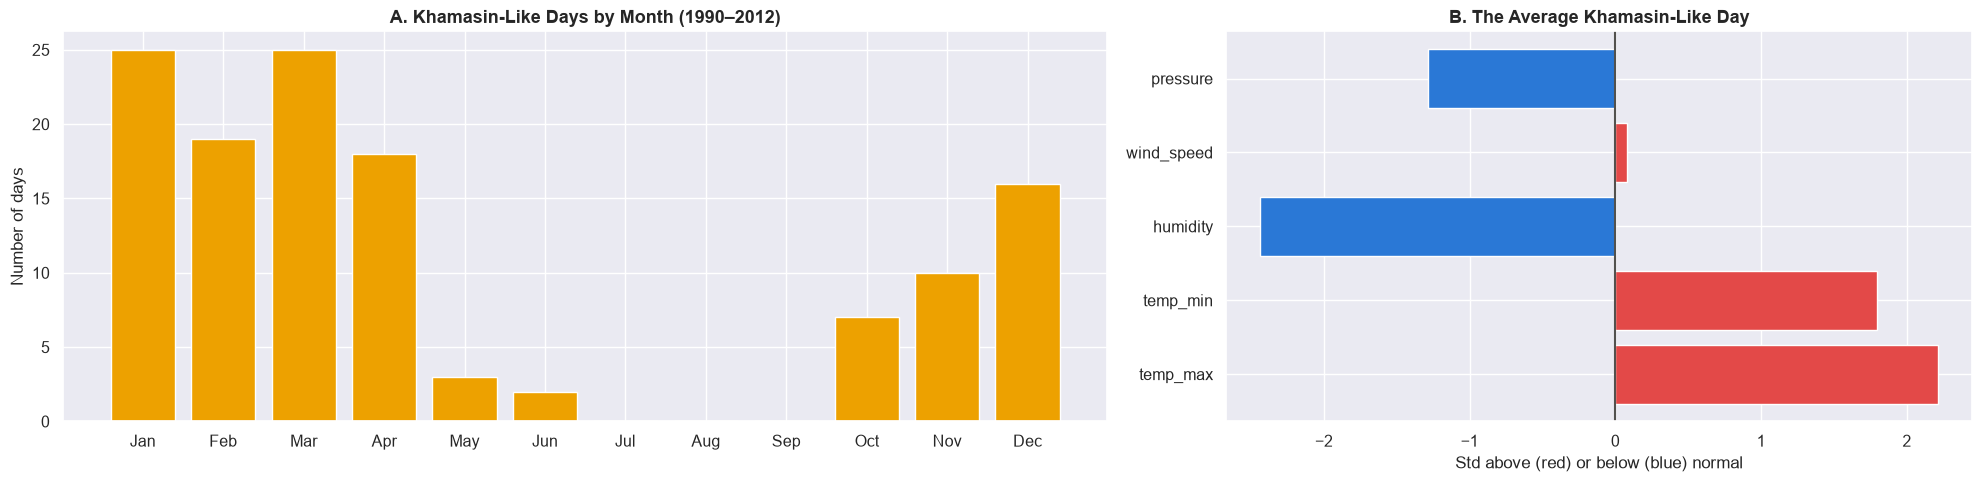

In [371]:
fig, ax = plt.subplots(ncols=2, figsize=(20, 5), gridspec_kw={"width_ratios": [1.4, 1]})

# A. In which months they happen
khamasin_by_month = khamasin_day.groupby(valid_years.index.month).sum().reindex(range(1, 13), fill_value=0)
ax[0].bar(MONTHS, khamasin_by_month, color="#eda100")
ax[0].set_title("A. Khamasin-Like Days by Month (1990–2012)")
ax[0].set_ylabel("Number of days")

# B. What a Khamasin-like day looks like, compared with normal (0)
khamasin_signs = valid_z.loc[khamasin_day, ["temp_max", "temp_min", "humidity", "wind_speed", "pressure"]].mean()
colors = ["#e34948" if value > 0 else "#2a78d6" for value in khamasin_signs]
ax[1].barh(khamasin_signs.index, khamasin_signs.values, color=colors)
ax[1].axvline(0, color="#52514e")
ax[1].set_title("B. The Average Khamasin-Like Day")
ax[1].set_xlabel("Std above (red) or below (blue) normal")

plt.tight_layout()
plt.show()

**What we see:** 125 Khamasin-like days in 1990–2012 (about 5 per year), mostly from December to April and almost none in June–September. They are much hotter (+2.2) and much drier (−2.4) than normal, with low pressure (−1.3) but normal wind speed. 2009 (15 days) and 2010 (21) have the most.

**Why:** Khamasin winds bring hot, dry desert air from the south, often ahead of a low-pressure system. Here they show up from winter to early spring, wider than the usual March–May, because winter weather changes more, so being "much hotter than normal" is easier. The strong wind does not show because the data is a daily average over 50 km.

**Answer to H6:** Yes. They can be found as hot, very dry, low-pressure days with a south wind.

**What we do with it:** Wind direction stops in 2012, so it cannot be used for the test years. Falling pressure, falling humidity and rising heat together can stand in for it.

## 3.5 From EDA to Modeling
Every finding, the proof, and what we do with it.

| # | What we found | Proof | What we do |
|---|---|---|---|
| 1 | The year repeats the same way | A 19 °C swing; a strong link at 1 year (+0.86) and the opposite at 6 months (−0.86) (3.2.3, 3.3.1, 3.3.2) | Give the model the day of year as sine and cosine; the month for rain |
| 2 | Seasons add, they do not multiply | Additive and multiplicative fit the same (3.3.1) | Additive form; no log scale |
| 3 | Temperature always comes back to its normal level | ADF p < 0.001 (3.3.3) | No differencing; teach the season with sine and cosine |
| 4 | Only the last few days help | After removing the season: 0.77 for today, 0.13 a week ago, about 0 a year ago (3.3.2) | Lags 1–3, 3- and 7-day means; drop lag 365 |
| 5 | "Tomorrow = today" is hard to beat | A 0.97 link between today and tomorrow (3.3.2) | Persistence is the main baseline |
| 6 | No weekly pattern | The same median every weekday (3.2.3) | Do not use day of week |
| 7 | Cairo is warming; the test years are the warmest | Nights +0.41 °C, days +0.23 °C per 10 years; most hot days in 2023–2024 (H1, H2) | Check whether the model forecasts the test years too cold |
| 8 | Spring is the hardest season | Day-to-day spread 3.4 °C in April vs 1.2 °C in August (3.2.4) | Report errors by month and season |
| 9 | Humidity and pressure help beyond the season | −0.50 and −0.34 with max temperature after removing the season (3.4.1) | Use them as differences from normal, plus their 1–3-day change |
| 10 | Rain is rare, seasonal, and comes in groups | 2.9 % rain days; 39 % chance after a rain day vs 5 % (3.1, 3.3.2) | Rain yes/no, judged by hits, misses, F1 and CSI; rain today and the month as inputs |
| 11 | Rain data changed in 2016 | Rain days ×2, heavy days ×38, storms the same (H3, 3.4.4) | The rain model uses 2016–2025 only |
| 12 | Storms give almost no warning | All links below 0.06 (H5) | Expect missed storms; compare with persistence |
| 13 | Wind direction stops in 2013 | 36 % missing (2.4, H6) | Do not use it |
| 14 | Outliers are real weather | They match storms, heat and cold; not growing (3.4.2) | Keep them; report MAE and RMSE |
| 15 | The model must not see the future | The EDA normals use all 36 years | From Part 4 on, normals and scalers use training years only |

# Summary (Parts 1–3)

**1. What region and time range did you use?**
Cairo, Egypt (one point at 30.04° N, 31.24° E, covering about 50 km × 50 km), daily from 1990-01-01 to 2025-12-31: 36 years, 13,149 days and 8 variables. 36 years is long enough to see the seasons many times and to measure a trend.

**2. What API and why?**
NASA POWER, daily point API (`/api/temporal/daily/point`, community AG, JSON). It is free, needs no key, and gives one consistent record back to 1981 in a single call, so anyone can repeat it. The parameters are listed in Part 1; the raw JSON and the CSV are saved.

**3. What are the main temporal patterns?**
- **Strong seasons:** temperature swings by about 19 °C and peaks in July–August. Humidity is highest in winter (about 66 %) and lowest in early summer (about 41 %). Pressure is high in January and low in July.
- **Slow warming:** the 365-day mean rose from about 21.5 °C (1990) to 22.5 °C (2025). Nights warm faster (+0.41 °C per 10 years) than days (+0.23 °C).
- **Spring is the most unstable:** temperature moves most in April (3.4 °C) and least in August (1.2 °C).
- **Rain is rare and seasonal:** only 2.9 % of days have ≥ 1 mm, almost all between October and April.
- **No weekly pattern.**

**4. Is the series stationary?**
**Partly.** The ADF test says yes (p < 0.001), even for the raw series: temperature always comes back to the same level, so no differencing is needed. But its average depends on the date (a strong yearly wave) and rises slowly, so the season must be modeled. Once the season is removed, only the last few days help (0.77 for today, about 0 a year ago).

**5. What data quality issues did you find and how did you handle them?**
- **Clean structure:** no missing dates, no duplicates, and consistent units. The −999 missing code appears only in wind direction.
- **Wind direction** is wrong (negative) from 2013 to 2025 (36 % of days). These values were set to empty and not filled, because filling 13 years would mean making up data.
- **Missing values:** short gaps (≤ 3 days) are filled from the days around them; the other columns had none.
- **Rain** jumps in 2016, most likely because of a change in the data, not the climate. Rain is analysed and modeled on 2016–2025 only.
- **Outliers** were found on a 31-day window, so normal summer heat is not flagged. They were kept, because extreme days are real weather.

# Part 4 — Forecasting Setup and Baselines
Parts 1–3 answer the task. This part gets ready for forecasting: what we forecast, how we split the years, how we score, and the simple forecasts every model must beat.

Two forecasts, both for **tomorrow**:

| Task | Target | Type | Years used |
|---|---|---|---|
| Temperature | Mean temperature tomorrow (°C) | Regression | 1990–2025 |
| Rain | Real rain day tomorrow (≥ 1 mm), yes or no | Classification | 2016–2025 (H3) |

## 4.1 Targets and Time Split

**What we do:** For every day, we add tomorrow's value as the target. Then we split the days by time into train, validation and test.

| | Temperature | Rain |
|---|---|---|
| Train | 1990–2019 | 2016–2020 |
| Validation | 2020–2022 | 2021–2022 |
| Test | 2023–2025 | 2023–2025 |

**Why:** A forecast can only use the past. A random split would mix 2024 days into training and 2023 days into testing: the model would peek at the future and look better than it really is.

**What we do with it:** Every baseline and every model uses the same split, so the scores are fair. Validation is for choosing settings; test is used once, at the end. The test years include the hottest summers (H2), so it is a hard, honest test.

In [372]:
# Each row is "today"; the target is tomorrow's value
data = weather.copy()
data["temp_tomorrow"] = data["temp_mean"].shift(-1)
data["rain_tomorrow"] = (data["precipitation"].shift(-1) >= 1).astype(int)

# The last day has no tomorrow, so it is removed
data = data.iloc[:-1]

# Split by time, never at random, so the model only learns from the past
temp_train = data.loc["1990":"2019"]
temp_valid = data.loc["2020":"2022"]
temp_test = data.loc["2023":"2025"]

# Rain uses 2016-2025 only, where the rain data is consistent
rain_train = data.loc["2016":"2020"]
rain_valid = data.loc["2021":"2022"]
rain_test = data.loc["2023":"2025"]

split_sizes = pd.DataFrame({
    "Days (temperature)": [len(temp_train), len(temp_valid), len(temp_test)],
    "Days (rain)": [len(rain_train), len(rain_valid), len(rain_test)],
    "Rain-tomorrow days": [rain_train["rain_tomorrow"].sum(), rain_valid["rain_tomorrow"].sum(), rain_test["rain_tomorrow"].sum()],
}, index=["Train", "Validation", "Test"])
split_sizes["Rain-tomorrow (%)"] = 100 * split_sizes["Rain-tomorrow days"] / split_sizes["Days (rain)"]
split_sizes.round(1)

,Days (temperature),Days (rain),Rain-tomorrow days,Rain-tomorrow (%)
Train,10957,1827,89,4.9
Validation,1096,730,44,6.0
Test,1095,1095,43,3.9


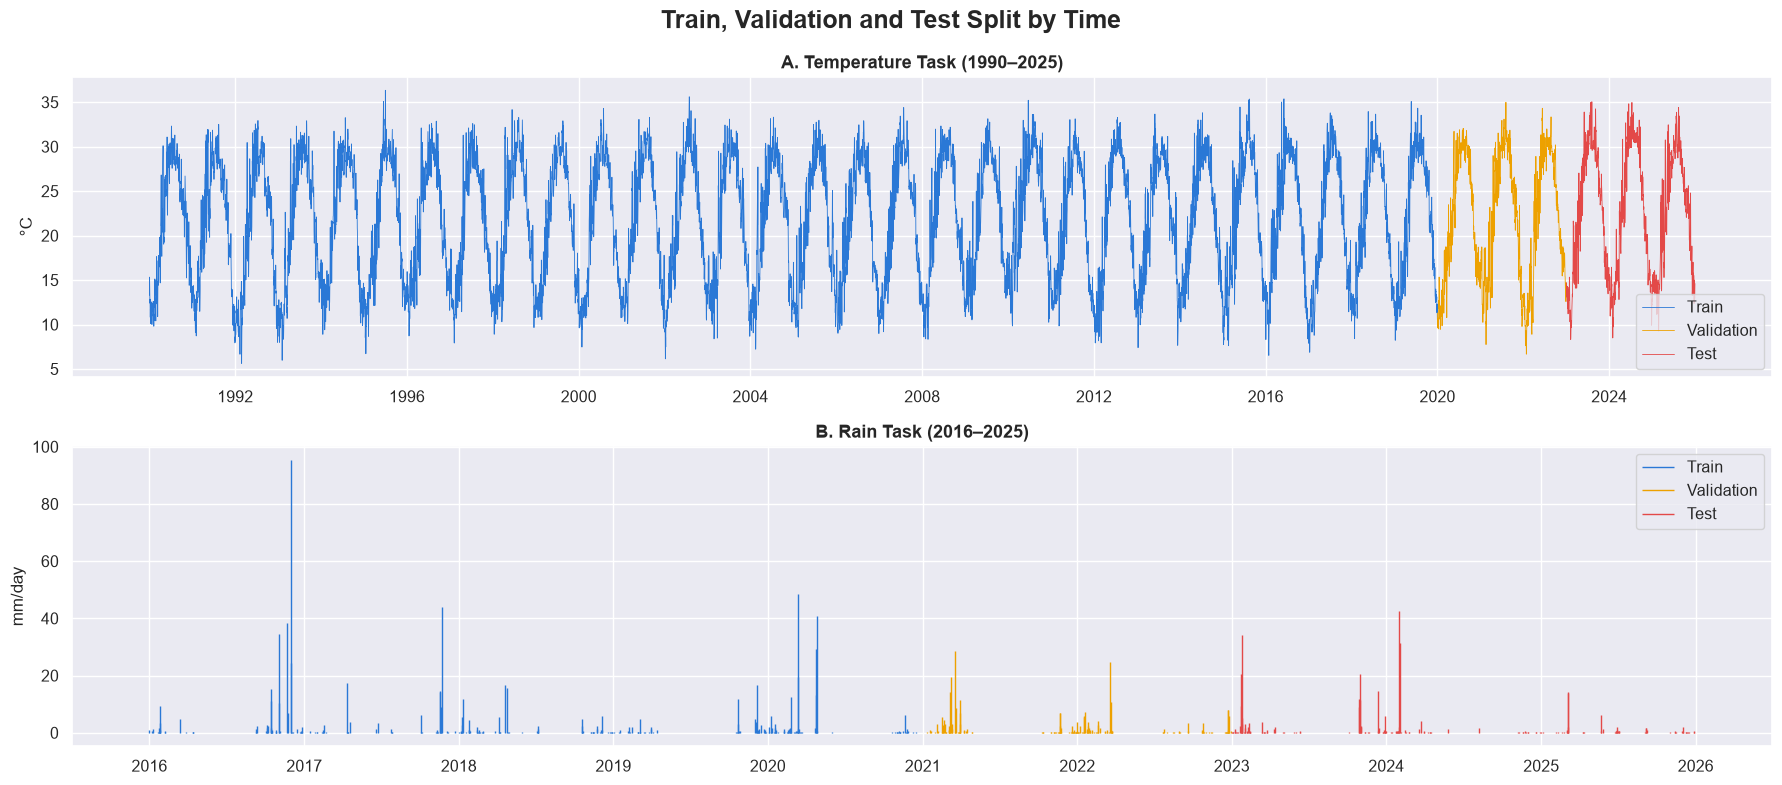

In [373]:
SPLIT_COLORS = {"Train": "#2a78d6", "Validation": "#eda100", "Test": "#e34948"}

fig, ax = plt.subplots(nrows=2, figsize=(18, 8))

# A. Temperature task, one color per split
for name, part in zip(SPLIT_COLORS, [temp_train, temp_valid, temp_test]):
    ax[0].plot(part.index, part["temp_mean"], color=SPLIT_COLORS[name], linewidth=0.6, label=name)
ax[0].set_title("A. Temperature Task (1990–2025)")
ax[0].set_ylabel("°C")
ax[0].legend()

# B. Rain task, one color per split (one vertical line per day, so no rain day is hidden)
for name, part in zip(SPLIT_COLORS, [rain_train, rain_valid, rain_test]):
    ax[1].vlines(part.index, 0, part["precipitation"], color=SPLIT_COLORS[name], linewidth=1, label=name)
ax[1].set_title("B. Rain Task (2016–2025)")
ax[1].set_ylabel("mm/day")
ax[1].legend()

plt.suptitle("Train, Validation and Test Split by Time")
plt.tight_layout()
plt.show()

**What we see:**
- **Temperature:** 30 years to learn from (10,957 days), then 3 years for validation and 3 for test (about 1,095 days each).
- **Rain:** rain tomorrow happens on 4.9 % of train days, 6.0 % of validation days and 3.9 % of test days. Validation has only 44 rain days, and test 43.

**Why:** Rain changes a lot from year to year, and 2023–2025 happened to be drier.

**What we do with it:** Never judge rain by accuracy: "always no rain" already gets 96 % on test. Show the counts (hits, misses, false alarms) next to the percentages, because one rain day more or less moves recall by about 2 points. A rain threshold chosen on the wetter validation years may give too many false alarms on test.

## 4.2 Evaluation Metrics
- **Temperature (regression):** MAE (the typical error in °C), RMSE (punishes big misses more), R².
- **Rain (classification):** hits, misses and false alarms, then precision, recall, F1 and CSI (hits out of all days where rain was forecast or happened). Accuracy is shown but not used to choose, because about 95 % of days are dry.

In [374]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

def regression_scores(y_true, y_pred):
    # Errors in °C, so they are easy to read
    return {
        "MAE (°C)": mean_absolute_error(y_true, y_pred),
        "RMSE (°C)": np.sqrt(mean_squared_error(y_true, y_pred)),
        "R²": r2_score(y_true, y_pred),
    }

def classification_scores(y_true, y_pred):
    # Counts first, because rain days are few and percentages can hide them
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    return {
        "Hits": tp,
        "Misses": fn,
        "False alarms": fp,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "F1": f1_score(y_true, y_pred, zero_division=0),
        # CSI: hits out of all days where rain was forecast or happened (ignores the many easy dry days)
        "CSI": tp / (tp + fn + fp) if (tp + fn + fp) > 0 else 0.0,
    }

In [375]:
# A perfect forecast should give MAE 0 and R² 1
regression_scores(temp_valid["temp_tomorrow"], temp_valid["temp_tomorrow"])

{'MAE (°C)': 0.0, 'RMSE (°C)': np.float64(0.0), 'R²': 1.0}

## 4.3 Regression Baselines (Temperature Tomorrow)

**What we do:** Forecast tomorrow's mean temperature with four simple methods that need no learning, and score them on validation and test.

| Baseline | Forecast for tomorrow | Idea |
|---|---|---|
| Persistence | Today's temperature | Weather changes slowly (Step 3.3.2) |
| Mean of last 7 days | The average of the last 7 days | Smooths out one-day noise |
| Climatology | The normal for tomorrow's date (train years only) | Uses only the season (Step 3.3.1) |
| Same day last year | Tomorrow's date, one year ago | Uses the yearly cycle |

**Why these four:** Each one uses one thing we found in the EDA: recent days, the season, or last year. A real model combines them, so it must beat all four. Climatology uses training years only (1990–2019), so no future data leaks in.

In [376]:
# Normal temperature for each day of the year, from the train years only
normal_by_day = temp_train["temp_mean"].groupby(temp_train.index.dayofyear).mean()
tomorrow_day = (data.index + pd.Timedelta(days=1)).dayofyear

# Each column is one simple forecast for tomorrow
temp_baselines = pd.DataFrame({
    "Persistence (today)": data["temp_mean"],
    "Mean of last 7 days": data["temp_mean"].rolling(7).mean(),
    "Climatology (normal for tomorrow)": normal_by_day.reindex(tomorrow_day).values,
    "Same day last year": data["temp_tomorrow"].shift(365),
}, index=data.index)

# Score every baseline on validation and test
rows = []
for split_name, part in [("Validation", temp_valid), ("Test", temp_test)]:
    for baseline in temp_baselines.columns:
        scores = regression_scores(part["temp_tomorrow"], temp_baselines.loc[part.index, baseline])
        scores["Split"] = split_name
        scores["Baseline"] = baseline
        rows.append(scores)

temp_results = pd.DataFrame(rows).set_index(["Split", "Baseline"])
temp_results.round(2)

MAE (°C)  RMSE (°C)    R²
Split      Baseline                                                    
Validation Persistence (today)                    1.07       1.49  0.96
           Mean of last 7 days                    1.59       2.14  0.91
           Climatology (normal for tomorrow)      1.84       2.40  0.88
           Same day last year                     2.56       3.35  0.77
Test       Persistence (today)                    1.04       1.44  0.96
           Mean of last 7 days                    1.54       2.06  0.91
           Climatology (normal for tomorrow)      1.79       2.33  0.89
           Same day last year                     2.27       2.93  0.82

**What we see:** "Tomorrow = today" wins clearly: MAE 1.07 °C on validation and 1.04 °C on test. Next come the 7-day mean (1.59 and 1.54), the normal for the date (1.84 and 1.79), and last year's same day is the worst (2.56 and 2.27).

**Why:** Weather changes slowly from one day to the next, and only the last few days carry information (Step 3.3.2). Last year's weather on this date is mostly luck.

**What we do with it:** A model is only useful if its MAE is below about 1.04–1.07 °C. That is the number to beat.

## 4.4 Classification Baselines (Rain Tomorrow)

**What we do:** Forecast "real rain tomorrow (≥ 1 mm)" with three simple methods that need no learning, and score them on validation and test (2016–2025 only, H3).

| Baseline | Forecast for tomorrow | Idea |
|---|---|---|
| Always no rain | Never rain | Shows why accuracy is misleading (Step 3.1) |
| Persistence | Rain if it rained today | Rain days come in groups (Step 3.3.2) |
| Seasonal guess | Rain at random, with the month's chance from the train years | Uses only the season (Step 3.2.3); a fixed seed keeps it the same every run |

**Why these three:** They show what you get with no skill, with one day of memory, and with the calendar alone. They are compared on hits, misses, false alarms, precision, recall, F1 and CSI.

In [377]:
# Chance of a rain day in each month, from the train years only
rain_by_month = (rain_train["precipitation"] >= 1).groupby(rain_train.index.month).mean()
tomorrow_month = (data.index + pd.Timedelta(days=1)).month
rain_chance = rain_by_month.reindex(tomorrow_month).values

# Fixed seed so the random guess is the same every run
rng = np.random.default_rng(42)

# Each column is one simple forecast for tomorrow (1 = rain, 0 = no rain)
rain_baselines = pd.DataFrame({
    "Always no rain": 0,
    "Persistence (rain today)": (data["precipitation"] >= 1).astype(int),
    "Seasonal guess (month's chance)": (rng.random(len(data)) < rain_chance).astype(int),
}, index=data.index)

# Score every baseline on validation and test
rows = []
for split_name, part in [("Validation", rain_valid), ("Test", rain_test)]:
    for baseline in rain_baselines.columns:
        scores = classification_scores(part["rain_tomorrow"], rain_baselines.loc[part.index, baseline])
        scores["Split"] = split_name
        scores["Baseline"] = baseline
        rows.append(scores)

rain_results = pd.DataFrame(rows).set_index(["Split", "Baseline"])
rain_results.round(2)

Hits  Misses  False alarms  \
Split      Baseline                                                      
Validation Always no rain                      0      44             0   
           Persistence (rain today)           16      28            28   
           Seasonal guess (month's chance)     3      41            33   
Test       Always no rain                      0      43             0   
           Persistence (rain today)           20      23            23   
           Seasonal guess (month's chance)     2      41            46   

                                            Accuracy  Precision  Recall    F1  \
Split      Baseline                                                             
Validation Always no rain                       0.94       0.00    0.00  0.00   
           Persistence (rain today)             0.92       0.36    0.36  0.36   
           Seasonal guess (month's chance)      0.90       0.08    0.07  0.08   
Test       Always no rain                       0.96       0.00    0.00  0.00   
           Persistence (rain today)             0.96       0.47    0.47  0.47   
           Seasonal guess (month's chance)      0.92       0.04    0.05  0.04   

                                             CSI  
Split      Baseline                               
Validation Always no rain                   0.00  
           Persistence (rain today)         0.22  
           Seasonal guess (month's chance)  0.04  
Test       Always no rain                   0.00  
           Persistence (rain today)         0.30  
           Seasonal guess (month's chance)  0.02

**What we see:**
- **Always no rain:** 94–96 % accuracy, but zero hits.
- **Persistence (rain today → rain tomorrow):** the best. It catches 16 of 44 rain days on validation (F1 0.36, CSI 0.22) and 20 of 43 on test (F1 0.47, CSI 0.30). It gives as many false alarms as misses.
- **Seasonal guess:** almost useless: 3 and 2 hits, with many more false alarms than hits.

**Why:** Rain comes in groups, so "it rained today" is a strong clue (Step 3.3.2). The month only tells you when rain is possible, not which day it falls.

**What we do with it:** Persistence is the rain baseline to beat: a model must catch more than about a third of the rain days on validation without adding many false alarms. Accuracy is ignored.

## Next Steps
The forecasting stages that follow from this notebook, in order:

1. **Features** (fitted on training years only): day of year as sine and cosine; temperature lags 1–3 and 3- and 7-day means; humidity, pressure and wind as differences from normal, and their change over 1–3 days. For rain: rain today, rain days in the last 3 days, the month. Not used: lag 365, day of week, wind direction (3.5).
2. **Candidate models:** Ridge regression, Random Forest and gradient boosting on the features; SARIMAX with Fourier terms for the season (d = 0, from 3.3.3). For rain: logistic regression and gradient boosting, with the decision threshold chosen on validation.
3. **Walk-forward validation:** expanding window, one validation year at a time (2020, 2021, 2022 for temperature; 2021, 2022 for rain). Settings are chosen here; the test years are not touched.
4. **Residual checks** on the validation years: residuals over time, ACF of residuals, Ljung-Box test, error by month, and bias in the warm recent years.
5. **Final test (2023–2025):** refit the chosen model on all years up to 2022, score it once, and compare it with the baselines of 4.3 and 4.4, overall and by month.